<!-- repo-header -->
# Per-branch shadow overlap on H2-1, and its calibration curve

**Why the certification is per-branch.** The Stage-1 output is the weighted stack

    |psi_w> = sum_i w_i |psi_i>_S  |i>_I

and the weights `w_i` are *random* -- they depend on the Stage-1 measurement
outcome, so every shot prepares a differently weighted state. The stack as a whole
therefore cannot be certified directly. Instead, condition on the index register
reading `|i>` and certify the segment `|psi_i>` that the storage register collapses
to. If all four branches carry the right segment, the compression worked.

**What this notebook does.**

1. Submits the branch-resolved shadow-overlap jobs to H2-1 (450 shots per branch:
   150 each of X, Y, Z), accumulating into
   `shadow_branch_hw_4x1024_L1_mid.pkl`. *Needs a Quantinuum account.*
2. **Generates the calibration curves** -- cell 79 for the 4 x 1024 run and cell 68
   for the earlier 4 x 32 run. Following Appendix F of the paper, states of known fidelity are
   synthesised and their shadow overlap computed exactly (feasible here because each
   branch is only 10 qubits), giving 9000 (omega, F) points per branch. Inverting
   this is what turns measured omega into the fidelities of Table I.
   ->  `shadow_vs_fidelity_rows_4x1024_L1_mid_vs_ideal.npz`

**Result.** Per-branch fidelities 0.589, 0.790, 0.721, 0.720, giving a weighted
branch fidelity of **0.7135 +/- 0.0720** against the original segment weights.

> **Credentials are not in this repository.** The auth cell reads `QNX_USER` and
> `QNX_PASS` from the environment. Only the submission cells need it; the
> calibration simulation and all analysis run offline.


# load and prepare circuit

In [1]:
import numpy as np
from qiskit import qpy

with open('mre_qc.qpy', 'rb') as f:
    qc = qpy.load(f)[0]
with open('mre_qc_direct.qpy', 'rb') as f:
    qc_direct = qpy.load(f)[0]
with open('mre_prep_circuits.qpy', 'rb') as f:
    prep_circuits = qpy.load(f)

data = np.load('mre_target_data.npz')
chunks = list(data['chunks'])       # 4 row vectors, chunks[i].shape == (32,)
v_direct = data['v_direct']         # flattened 128-dim direct-encoding target
Y = data['Y']; M = int(data['M']); N = int(data['N'])

print(f"qc: {qc.num_qubits}q   qc_direct: {qc_direct.num_qubits}q   "
      f"{len(prep_circuits)} prep circuits   chunks: {len(chunks)}x{chunks[0].shape}")


qc: 28q   qc_direct: 7q   4 prep circuits   chunks: 4x(32,)


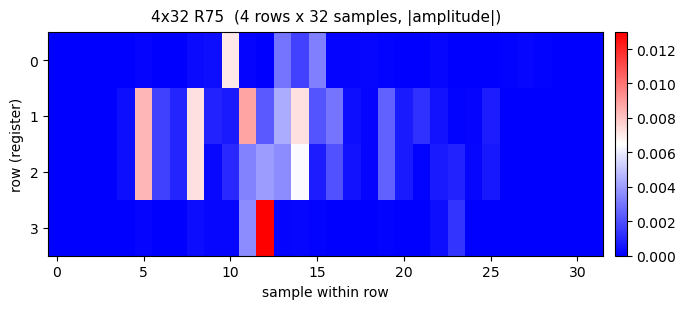

row prep circuits:
  row 0: 5q  55 gates  fidelity(loaded circuit, target) = 0.9999999997  (saved sso_fid = 0.9999999998)
  row 1: 5q  55 gates  fidelity(loaded circuit, target) = 0.9999999997  (saved sso_fid = 0.9999999999)
  row 2: 5q  55 gates  fidelity(loaded circuit, target) = 0.9999999990  (saved sso_fid = 0.9999999990)
  row 3: 5q  55 gates  fidelity(loaded circuit, target) = 0.9999999999  (saved sso_fid = 1.0000000000)

qc (multi-register): 28q   depth=53   gates=255

qc_direct: 7q   depth=107   gates=357   sso_fid=0.9999999909

qc_direct fidelity vs v_direct = 0.9999999909
qc: statevector norm=1.0000000000  (4.29 GB)
qc: ancilla leak = 0.00e+00   (should be ~0)
qc: reconstruction fidelity @ peak outcome u=(10, 11, 5, 12) = 0.9999999995


In [2]:
import matplotlib.pyplot as plt
import mre_prep as mre
from qiskit.quantum_info import Statevector

def show(qc, **kw):
    """Draw with matplotlib; fall back to text if pylatexenc/mpl is unavailable."""
    try:
        return qc.draw('mpl', **kw)
    except Exception as e:
        print(f"(mpl draw unavailable -> text): {e}")
        return qc.draw('text', fold=-1)

# ---- data heatmap ----
img = np.abs(Y.T)
fig, ax = plt.subplots(figsize=(7, 3.2))
im = ax.imshow(img, aspect='auto', cmap='bwr', interpolation='nearest',
               vmin=img.min(), vmax=img.max())
ax.set_title(f'{M}x{N} R75  ({M} rows x {N} samples, |amplitude|)', fontsize=11, pad=8)
ax.set_xlabel('sample within row'); ax.set_ylabel('row (register)')
ax.set_yticks(range(M))
plt.colorbar(im, ax=ax, fraction=0.05, pad=0.02); plt.tight_layout(); plt.show()

# ---- row prep circuits: real fidelity check (loaded circuit vs loaded target) + draw row 0 ----
print("row prep circuits:")
for i, (pc, target) in enumerate(zip(prep_circuits, chunks)):
    f = mre.fidelity(np.asarray(Statevector(pc)), target)
    print(f"  row {i}: {pc.num_qubits}q  {pc.size()} gates  "
          f"fidelity(loaded circuit, target) = {f:.10f}  (saved sso_fid = {pc.metadata['sso_fid']:.10f})")
show(prep_circuits[0], fold=-1, scale=0.7); plt.show()

# ---- full multi-register circuit qc ----
print(f"\nqc (multi-register): {qc.num_qubits}q   depth={qc.depth()}   gates={qc.size()}")
show(qc, fold=-1, scale=0.5); plt.show()

# ---- direct-encoding circuit qc_direct ----
print(f"\nqc_direct: {qc_direct.num_qubits}q   depth={qc_direct.depth()}   gates={qc_direct.size()}   "
      f"sso_fid={qc_direct.metadata['sso_fid']:.10f}")
show(qc_direct, fold=-1, scale=0.45); plt.show()

# ---- qc_direct: full statevector check against the known target ----
sv_direct = mre.simulate_statevector(qc_direct)
print(f"\nqc_direct fidelity vs v_direct = {mre.fidelity(sv_direct, v_direct):.10f}")

# ---- qc: full 28-qubit inner-product smoke test (same check as the build notebook, Sec.4) ----
n = int(np.log2(N)); m = int(np.log2(M))
layout = dict(M=M, N=N, n_low=n + m, anc=True)   # minimal reconstruction; only these fields are used below

sv = mre.simulate_statevector(qc)   # ~5-6s, ~4.3GB
u = mre.peak_outcome(chunks)
block, nrm = mre.extract_SI(sv, u, layout)
f = mre.fidelity(block, mre.weighted_stack_vector(chunks, u))
print(f"qc: statevector norm={np.linalg.norm(sv):.10f}  ({sv.nbytes/1e9:.2f} GB)")
print(f"qc: ancilla leak = {mre.ancilla_leak(sv, layout):.2e}   (should be ~0)")
print(f"qc: reconstruction fidelity @ peak outcome u={u} = {f:.10f}")


# Quantinuum EMULATOR DANGER BE CAREFUL NO ACCADENTAL RUNS

cells are edited after running so if for some reason they run they should instead call an error (from a typo) for saftey

## Login and set project

In [95]:
from qiskit import QuantumCircuit
from pytket.extensions.qiskit import qiskit_to_tk
from qnexus import QuantinuumConfig
import qnexus as qnx
from pytket import OpType
from qnexus.models.references import CircuitRef
import pickle


In [ ]:
# Quantinuum Nexus authentication.
#
# Credentials are deliberately NOT stored in this repository. Supply them at run
# time, e.g. from environment variables:
#
#     export QNX_USER="you@example.com"
#     export QNX_PASS="..."
#
# Everything downstream of this cell -- every job submission -- requires a
# Quantinuum account with H2-1 access. The analysis and plotting notebooks do
# NOT need this cell: they read the committed result files instead.
import os

qnx.client.auth.login_no_interaction(
    user=os.environ["QNX_USER"],
    pwd=os.environ["QNX_PASS"],
)

In [96]:
import qnexus as qnx

project = qnx.projects.get_or_create(name="MultiRegister Encoding")
qnx.context.set_active_project(project)

In [97]:
import pickle
from collections import Counter
import qnexus as qnx            # will prompt for auth if your token has expired

TAG  = "4x1024_L1_mid"
pool = pickle.load(open(f"compiled_pool_branch_{TAG}.pkl", "rb"))

for slot, e in pool.items():
    c = e["ref"].download_circuit()          # the post-compile circuit, as executed
    print(f"{str(slot):<10} {e['shots']:>4d} shots   "
          f"qubits {c.n_qubits:>3d}  depth {c.depth():>4d}  "
          f"gates {c.n_gates:>5d}  2q {c.n_2qb_gates():>4d}   "
          f"{dict(Counter(cmd.op.type.name for cmd in c))}")


('Z', 2)    150 shots   qubits  53  depth  427  gates  1537  2q  478   {'PhasedX': 953, 'ZZPhase': 478, 'Rz': 52, 'Barrier': 1, 'Measure': 53}
(0, 0)       15 shots   qubits  53  depth  427  gates  1538  2q  478   {'PhasedX': 954, 'ZZPhase': 478, 'Rz': 52, 'Barrier': 1, 'Measure': 53}
(0, 1)       15 shots   qubits  53  depth  427  gates  1538  2q  478   {'PhasedX': 954, 'ZZPhase': 478, 'Rz': 52, 'Barrier': 1, 'Measure': 53}
(1, 0)       15 shots   qubits  53  depth  427  gates  1538  2q  478   {'PhasedX': 954, 'ZZPhase': 478, 'Rz': 52, 'Barrier': 1, 'Measure': 53}
(1, 1)       15 shots   qubits  53  depth  427  gates  1538  2q  478   {'PhasedX': 954, 'ZZPhase': 478, 'Rz': 52, 'Barrier': 1, 'Measure': 53}
(2, 0)       15 shots   qubits  53  depth  427  gates  1538  2q  478   {'PhasedX': 954, 'ZZPhase': 478, 'Rz': 52, 'Barrier': 1, 'Measure': 53}
(2, 1)       15 shots   qubits  53  depth  427  gates  1538  2q  478   {'PhasedX': 954, 'ZZPhase': 478, 'Rz': 52, 'Barrier': 1, 'Measure': 53}

## Workflow

In [5]:
#Generate the number of shots that we will take on each basis
import numpy as np
from collections import Counter
num_qubits=28
seed = 42
rng = np.random.default_rng(seed)

shots_taken = []
#take 600 for there to be around 1300 hardware units
for _ in range(600):
    target_qubit = int(rng.integers(0, num_qubits))
    unitary_id = int(rng.integers(0, 3))
    shots_taken.append((target_qubit, unitary_id))

# Count frequencies
freq_counter = Counter(shots_taken)

# Sort by target_qubit, then unitary_id
freq_sorted = dict(sorted(freq_counter.items(), key=lambda x: (x[0][0], x[0][1])))
total_unitary_2 = sum(count for (i, u), count in freq_sorted.items() if u == 2)
print(freq_sorted)
print("\nTotal occurrences of (*, 2):", total_unitary_2)

{(0, 0): 8, (0, 1): 5, (0, 2): 10, (1, 0): 9, (1, 1): 2, (1, 2): 4, (2, 0): 8, (2, 1): 7, (2, 2): 10, (3, 0): 4, (3, 1): 12, (3, 2): 5, (4, 0): 6, (4, 1): 8, (4, 2): 8, (5, 0): 5, (5, 1): 3, (5, 2): 8, (6, 0): 9, (6, 1): 3, (6, 2): 7, (7, 0): 7, (7, 1): 6, (7, 2): 6, (8, 0): 8, (8, 1): 9, (8, 2): 7, (9, 0): 5, (9, 1): 8, (9, 2): 1, (10, 0): 4, (10, 1): 5, (10, 2): 6, (11, 0): 7, (11, 1): 7, (11, 2): 5, (12, 0): 13, (12, 1): 8, (12, 2): 14, (13, 0): 6, (13, 1): 9, (13, 2): 5, (14, 0): 7, (14, 1): 11, (14, 2): 10, (15, 0): 9, (15, 1): 12, (15, 2): 6, (16, 0): 6, (16, 1): 5, (16, 2): 3, (17, 0): 9, (17, 1): 8, (17, 2): 6, (18, 0): 6, (18, 1): 4, (18, 2): 6, (19, 0): 6, (19, 1): 9, (19, 2): 4, (20, 0): 10, (20, 1): 10, (20, 2): 12, (21, 0): 3, (21, 1): 11, (21, 2): 5, (22, 0): 8, (22, 1): 6, (22, 2): 10, (23, 0): 11, (23, 1): 11, (23, 2): 8, (24, 0): 6, (24, 1): 3, (24, 2): 3, (25, 0): 10, (25, 1): 6, (25, 2): 6, (26, 0): 11, (26, 1): 6, (26, 2): 9, (27, 0): 5, (27, 1): 6, (27, 2): 10}

To

{(0, 0): 8, (0, 1): 5, (0, 2): 10, (1, 0): 9, (1, 1): 2, (1, 2): 4, (2, 0): 8, (2, 1): 7, (2, 2): 10, (3, 0): 4, (3, 1): 12, (3, 2): 5, (4, 0): 6, (4, 1): 8, (4, 2): 8, (5, 0): 5, (5, 1): 3, (5, 2): 8, (6, 0): 9, (6, 1): 3, (6, 2): 7, (7, 0): 7, (7, 1): 6, (7, 2): 6, (8, 0): 8, (8, 1): 9, (8, 2): 7, (9, 0): 5, (9, 1): 8, (9, 2): 1, (10, 0): 4, (10, 1): 5, (10, 2): 6, (11, 0): 7, (11, 1): 7, (11, 2): 5, (12, 0): 13, (12, 1): 8, (12, 2): 14, (13, 0): 6, (13, 1): 9, (13, 2): 5, (14, 0): 7, (14, 1): 11, (14, 2): 10, (15, 0): 9, (15, 1): 12, (15, 2): 6, (16, 0): 6, (16, 1): 5, (16, 2): 3, (17, 0): 9, (17, 1): 8, (17, 2): 6, (18, 0): 6, (18, 1): 4, (18, 2): 6, (19, 0): 6, (19, 1): 9, (19, 2): 4, (20, 0): 10, (20, 1): 10, (20, 2): 12, (21, 0): 3, (21, 1): 11, (21, 2): 5, (22, 0): 8, (22, 1): 6, (22, 2): 10, (23, 0): 11, (23, 1): 11, (23, 2): 8, (24, 0): 6, (24, 1): 3, (24, 2): 3, (25, 0): 10, (25, 1): 6, (25, 2): 6, (26, 0): 11, (26, 1): 6, (26, 2): 9, (27, 0): 5, (27, 1): 6, (27, 2): 10}

in z basis 194 shots

## Emulator Runs

typos are intentionally put in device name to prevent accidental runs, with a q at the end of the filename or device for execute and job subimt

present (84): (q0,X), (q0,Y), (q0,Z), (q1,X), (q1,Y), (q1,Z), (q2,X), (q2,Y), (q2,Z), (q3,X), (q3,Y), (q3,Z), (q4,X), (q4,Y), (q4,Z), (q5,X), (q5,Y), (q5,Z), (q6,X), (q6,Y), (q6,Z), (q7,X), (q7,Y), (q7,Z), (q8,X), (q8,Y), (q8,Z), (q9,X), (q9,Y), (q9,Z), (q10,X), (q10,Y), (q10,Z), (q11,X), (q11,Y), (q11,Z), (q12,X), (q12,Y), (q12,Z), (q13,X), (q13,Y), (q13,Z), (q14,X), (q14,Y), (q14,Z), (q15,X), (q15,Y), (q15,Z), (q16,X), (q16,Y), (q16,Z), (q17,X), (q17,Y), (q17,Z), (q18,X), (q18,Y), (q18,Z), (q19,X), (q19,Y), (q19,Z), (q20,X), (q20,Y), (q20,Z), (q21,X), (q21,Y), (q21,Z), (q22,X), (q22,Y), (q22,Z), (q23,X), (q23,Y), (q23,Z), (q24,X), (q24,Y), (q24,Z), (q25,X), (q25,Y), (q25,Z), (q26,X), (q26,Y), (q26,Z), (q27,X), (q27,Y), (q27,Z)
missing (0): none


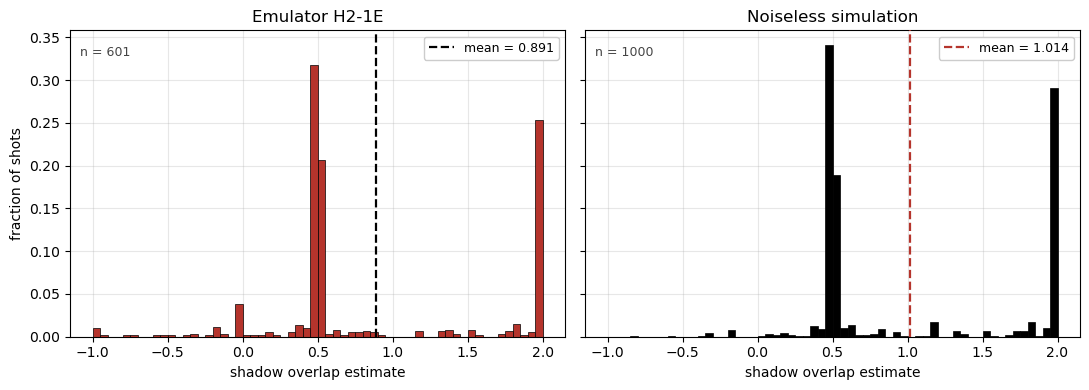

In [82]:
store = load_shadow_results()
emu, _ = pooled_estimates()
sim = np.asarray(np.load("multiregister_shadow_results_grouped.npy"), dtype=float)

present = sorted(store)
missing = sorted(b for b in map(tuple, freq_sorted) if b not in store)
fmt = lambda bs: ", ".join(f"(q{q},{PAULIS[p]})" for q, p in bs) or "none"
print(f"present ({len(present)}): {fmt(present)}")
print(f"missing ({len(missing)}): {fmt(missing)}")

RED, BLACK, NBINS = "#b5342c", "#000000", 60

# one set of bins and one y-scale for both panels; y is a fraction so the
# different shot counts (n=202 vs n=600) stay comparable
edges = np.linspace(min(emu.min(), sim.min()), max(emu.max(), sim.max()), NBINS + 1)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True, sharey=True)
panels = ((axes[0], emu, RED,   BLACK, "Emulator H2-1E"),
          (axes[1], sim, BLACK, RED,   "Noiseless simulation"))
for ax, vals, fill, meanc, name in panels:
    ax.hist(vals, bins=edges, weights=np.full(len(vals), 1 / len(vals)),
            color=fill, edgecolor="black", lw=0.5, zorder=2)
    ax.axvline(vals.mean(), color=meanc, ls="--", lw=1.6, zorder=3,
               label=f"mean = {vals.mean():.3f}")
    ax.set_title(name, fontsize=12)
    ax.set_xlabel("shadow overlap estimate")
    ax.legend(fontsize=9, framealpha=1.0, loc="upper right")
    ax.grid(alpha=0.3, zorder=0)
    ax.text(0.02, 0.95, f"n = {len(vals)}", transform=ax.transAxes,
            va="top", fontsize=9, color="#444444")
axes[0].set_ylabel("fraction of shots")
plt.tight_layout(); plt.show()


In [31]:
#Functions needed and setting target_state once
#Edited from original to work with qiskit rather than quimb circuits
import numpy as np
from scipy.stats import norm, t
import matplotlib.pyplot as plt
import mre_prep as mre

import numpy as np
from pytket.extensions.qiskit import qiskit_to_tk


def nexus_bit_to_qiskit_index(qc):
    """PERM[i] = Qiskit global qubit index measured into classical bit c[i].
       pytket sorts qubits alphabetically by register (A0,A1,A2,A3,I,S,anc);
       Qiskit indexes them as declared (S,I,A0..A3,anc). Not a reversal."""
    names = [f"{q._register.name}[{q._index}]" for q in qc.qubits]
    tk = qiskit_to_tk(qc)
    tk.measure_all()
    wiring = {str(c.args[1]): str(c.args[0]) for c in tk if c.op.type.name == "Measure"}
    return [names.index(wiring[f"c[{i}]"]) for i in range(len(names))]


def nexus_to_statevector_order(b, perm):
    """Reorder one bitstring from get_counts() order into np.binary_repr order,
       so int(b, 2) is a valid index into a Qiskit statevector."""
    n = len(perm)
    s = [None] * n
    for i, g in enumerate(perm):
        s[n - 1 - g] = b[i]          # global qubit g sits at binary_repr position n-1-g
    return "".join(s)


def counts_from_portal_paste(shots, qc, portal_is_reversed=True):
    """Hand-pasted portal bitstrings -> the same dict shape result.get_counts() feeds.

    The portal prints most-significant-classical-bit first, i.e. REVERSED relative
    to get_counts(). Verified via anc[0]: it is c[27] (last in get_counts order) and
    the circuit resets it to |0>, so it must land at position 0 after the remap."""
    perm = nexus_bit_to_qiskit_index(qc)
    counts = {}
    for b in shots:
        c_order = b[::-1] if portal_is_reversed else b
        k = nexus_to_statevector_order(c_order, perm)
        counts[k] = counts.get(k, 0) + 1

    anc_p1 = sum(int(k[0]) * v for k, v in counts.items()) / sum(counts.values())
    print(f"{sum(counts.values())} shots, {len(counts)} distinct")
    print(f"ancilla P(1) after remap = {anc_p1:.3f}  (should be ~0; if it is ~0.5, "
          f"flip portal_is_reversed)")
    return counts
#processing
#Speedup claude made to compute the probability densities at the start to save time.
import numpy as np

H_ = np.array([[1,1],[1,-1]], dtype=complex)/np.sqrt(2)
Sdg_ = np.diag([1,-1j]).astype(complex)

def _rotated_probs(base_sv, pauli, target_qubit, num_qubits):
    """|U-rotated statevector|^2 for `pauli` on Qiskit qubit `target_qubit`, without
    ever holding two full complex statevectors alive at once (matters at 28 qubits)."""
    if pauli == 'Z':
        return np.abs(base_sv) ** 2
    U = H_ if pauli == 'X' else H_ @ Sdg_
    stride = 2 ** target_qubit
    sv3 = base_sv.reshape(-1, 2, stride)
    b0, b1 = sv3[:, 0, :], sv3[:, 1, :]
    rotated = np.empty_like(sv3)
    rotated[:, 0, :] = U[0,0]*b0 + U[0,1]*b1
    rotated[:, 1, :] = U[1,0]*b0 + U[1,1]*b1
    probs = np.abs(rotated.reshape(-1)) ** 2
    del rotated, sv3, b0, b1
    return probs


def get_snapshot_cached(base_sv, num_qubits, cache, verbose=False, basis_select=False):
    """Same interface as get_snapshot_qiskit, but caches the rotated probability
    distribution per (qubit, Pauli) in `cache` (a dict you create once and reuse).
    The expensive rotation happens only the FIRST time a given basis is drawn;
    every later shot at that basis samples the cached CDF in microseconds."""
    paulis = ['X', 'Y', 'Z']
    target_qubit = np.random.randint(0, num_qubits) if not basis_select else basis_select[0]
    P = paulis[np.random.randint(0, 3)] if not basis_select else paulis[basis_select[1]]

    key = (target_qubit, P)
    if key not in cache:
        probs = _rotated_probs(base_sv, P, target_qubit, num_qubits)
        cache[key] = np.cumsum(probs)
        del probs

    idx = int(np.searchsorted(cache[key], np.random.random()))
    bitstring = np.binary_repr(idx, width=num_qubits)
    string_pos = num_qubits - 1 - target_qubit
    if verbose:
        print(f"qubit {target_qubit} (string pos {string_pos}), basis {P}, result {bitstring}")
    return bitstring, string_pos, P


def run_multiple_shadow_overlaps_cached(target_state, base_sv, num_qubits, num_snapshots,
                                        verbose=False, basis_select=False):
    """Drop-in replacement for run_multiple_shadow_overlaps -- pass the already-
    simulated statevector as `base_sv` instead of a circuit."""
    cache = {}
    estimated_fideleities = []
    for i in range(num_snapshots):
        measurement, target_qubit, Pauli = get_snapshot_cached(
            base_sv, num_qubits, cache, verbose=verbose, basis_select=basis_select)
        cond = build_conditional_postmeasurement_single_qubit(target_state, measurement, target_qubit, verbose=verbose)
        estimated_fideleities.append(
            compute_local_overlap(cond, int(measurement[target_qubit]), Pauli, verbose=verbose))
    return estimated_fideleities
H_ = np.array([[1,1],[1,-1]], dtype=complex)/np.sqrt(2)
Sdg_ = np.diag([1,-1j]).astype(complex)

def rotated_probs_lowmem(base_sv, pauli, target_qubit, num_qubits):
    """|U-rotated statevector|^2 for `pauli` on Qiskit qubit `target_qubit`. Never
    allocates a full-size complex 'rotated' array -- only ever holds ONE half-size
    complex temp at a time, on top of the final real-valued probs output."""
    if pauli == 'Z':
        out = np.abs(base_sv)
        np.square(out, out=out)
        return out
    U = H_ if pauli == 'X' else H_ @ Sdg_
    stride = 2 ** target_qubit
    sv3 = base_sv.reshape(-1, 2, stride)
    b0, b1 = sv3[:, 0, :], sv3[:, 1, :]        # views, no copy

    probs = np.empty(base_sv.shape[0], dtype=np.float64)
    probs3 = probs.reshape(-1, 2, stride)

    tmp = U[0,0]*b0 + U[0,1]*b1                 # ONE half-size complex temp
    np.abs(tmp, out=probs3[:, 0, :])
    probs3[:, 0, :] **= 2
    del tmp

    tmp = U[1,0]*b0 + U[1,1]*b1                 # reuse: still only one half-size temp alive
    np.abs(tmp, out=probs3[:, 1, :])
    probs3[:, 1, :] **= 2
    del tmp
    return probs

from collections import defaultdict
import gc

def run_shadow_grouped(target_state, base_sv, num_qubits, total_shots, verbose=False,
                       save_path="multiregister_shadow_results_grouped.npy"):
    """Draws `total_shots` independently random (qubit, Pauli) choices up front (matching
    the original fully-random protocol exactly), groups them by which basis they landed
    on, then processes each DISTINCT basis once: compute its rotated distribution, draw
    exactly as many samples as that basis was picked, then free it before the next group.
    Peak memory = one distribution at a time, and each distinct basis is rotated at most
    once no matter how many total shots hit it."""
    paulis = ['X', 'Y', 'Z']

    qubit_choices = np.random.randint(0, num_qubits, size=total_shots)
    pauli_choices = np.random.randint(0, 3, size=total_shots)

    groups = defaultdict(list)
    for shot_i, (q, p_idx) in enumerate(zip(qubit_choices, pauli_choices)):
        groups[(int(q), paulis[p_idx])].append(shot_i)

    print(f"{total_shots} shots landed on {len(groups)} distinct (qubit, Pauli) combinations "
          f"out of {num_qubits*3} possible")

    estimated_fideleities_taued = [None] * total_shots   # preserves original shot order
    for gi, ((q, p), shot_idxs) in enumerate(groups.items()):
        print(f"[{gi+1}/{len(groups)}] qubit={q} pauli={p}  ({len(shot_idxs)} shots)", flush=True)
        probs = rotated_probs_lowmem(base_sv, p, q, num_qubits)
        cdf = np.cumsum(probs)
        del probs; gc.collect()

        string_pos = num_qubits - 1 - q
        for shot_i in shot_idxs:
            idx = int(np.searchsorted(cdf, np.random.random()))
            bitstring = np.binary_repr(idx, width=num_qubits)
            cond = build_conditional_postmeasurement_single_qubit(target_state, bitstring, string_pos, verbose=verbose)
            estimated_fideleities_taued[shot_i] = compute_local_overlap(cond, int(bitstring[string_pos]), p, verbose=verbose)

        del cdf; gc.collect()
        np.save(save_path, estimated_fideleities_taued, allow_pickle=True)   # checkpoint after each group

    return estimated_fideleities_taued
def get_shadows_from_basis_allcomp_cached(target_state, base_sv, sizes, num_qubits,
                                          cache=None, verbose: bool = False):
    """Classical-simulation analog of get_shadows_from_basis_allcomp: samples
    sum(sizes) shots directly from the Z-basis Born distribution of `base_sv`
    (cached, computed ONCE regardless of how many qubits you segment across),
    then partitions into disjoint per-qubit segments exactly like the hardware
    version -- so the two are directly, apples-to-apples comparable.
    `sizes[i]` = planned shot count for qubit i (e.g. from freq_sorted where
    unitary_id==2). Pass a persistent `cache` dict to reuse the distribution
    across repeated calls."""
    P = 'Z'
    if cache is None: cache = {}
    total_shots = sum(sizes)

    key = ('ALLQ', P)
    if key not in cache:
        probs = rotated_probs_lowmem(base_sv, P, 0, num_qubits)   # target_qubit ignored for Z
        cache[key] = np.cumsum(probs)
        del probs
    cdf = cache[key]

    shot_list = []
    for _ in range(total_shots):
        idx = int(np.searchsorted(cdf, np.random.random()))
        shot_list.append(np.binary_repr(idx, width=num_qubits))
    random.shuffle(shot_list)

    shot_segments, start = [], 0
    for size in sizes:
        shot_segments.append(shot_list[start:start+size]); start += size

    estimates = []
    for target_qubit, shots in enumerate(shot_segments):
        string_pos = num_qubits - 1 - target_qubit   # matches the Qiskit convention used everywhere else
        for measurement in shots:
            cond_state = build_conditional_postmeasurement_single_qubit(target_state, measurement, string_pos, verbose=verbose)
            estimates.append(compute_local_overlap(cond_state, int(measurement[string_pos]), P, verbose=verbose))
    return estimates
def run_shadow_grouped_allcomp(target_state, base_sv, num_qubits, freq_sorted, verbose=False,
                               save_path="multiregister_shadow_results_allcomp.npy"):
    """All-computational-basis analog of run_shadow_grouped: `freq_sorted[i]` = planned
    Z-basis shot count for qubit i (a plain length-`num_qubits` list, e.g. your sizes_z).
    Every shot reads the SAME single Z-basis Born distribution no matter which qubit its
    estimate is assigned to, so there's exactly one CDF to build (trivial for Z -- no
    rotation at all), then it's just sliced into per-qubit segments."""
    sizes = freq_sorted
    total_shots = sum(sizes)
    print(f"{total_shots} shots across {sum(1 for s in sizes if s > 0)} qubits (Z basis only)")

    probs = rotated_probs_lowmem(base_sv, 'Z', 0, num_qubits)   # target_qubit ignored for Z
    cdf = np.cumsum(probs)
    del probs; gc.collect()

    shot_list = []
    for _ in range(total_shots):
        idx = int(np.searchsorted(cdf, np.random.random()))
        shot_list.append(np.binary_repr(idx, width=num_qubits))
    del cdf; gc.collect()

    estimated_fideleities = []
    start = 0
    for target_qubit, size in enumerate(sizes):
        if size == 0:
            continue
        if verbose:
            print(f"qubit={target_qubit}  ({size} shots)", flush=True)
        string_pos = num_qubits - 1 - target_qubit
        for measurement in shot_list[start:start + size]:
            cond = build_conditional_postmeasurement_single_qubit(target_state, measurement, string_pos, verbose=False)
            estimated_fideleities.append(compute_local_overlap(cond, int(measurement[string_pos]), 'Z', verbose=False))
        start += size
        np.save(save_path, estimated_fideleities, allow_pickle=True)   # checkpoint after each qubit

    return estimated_fideleities

import random
def get_shadows_from_basis_allcomp(results,target_state,title,num_qubits=28,verbose:bool=False):
    """
    This function is needed for the niche purpose of batching all of the (_,2) together. Data is collected in the same way for all
    the different basis but we need to make sure they are still all processed randomly as requied on each qubit. This is hardcoded into the funciton, this random choice of which ones they will be in.
    results: dict mapping bitstring -> count
    basis_choice: structure giving Pauli choice per qubit
    """
    
    estimates = []
    paulis = ['X', 'Y', 'Z']

      #if only comp basis selected then make sure we measure in Z.
    
    P = paulis[2]

    # --- Step 1: Expand dictionary into explicit shot list ---
    shot_list = []
    for bitstring, count in results.items():
        shot_list.extend([bitstring] * count)
    if verbose:
        print("Shot list unpacked",shot_list)
    # Shuffle shots randomly
    random.shuffle(shot_list)
    if verbose:
        print("Randomised shot list",shot_list)

    #Break shot list into desired sizes
    shot_segments = []
    sizes= [10,4,10,5,8,8,7,6,7,1,6,5,14,5,10,6,3,6,6,4,12,5,10,8,3,6,9,10]
    start = 0
    for size in sizes:
        end = start + size
        shot_segments.append(shot_list[start:end])
        start = end
    

    #HERE CYCLE OVER ALL THE DIFFERENT SHOTS THAT NEED TO TAKE PLACE
    # --- Step 3: Process each shot sequentially ---
    target_qubit=0
    for shots in shot_segments:
        print("Measuring on qubit",target_qubit, "with", shots)
        string_pos = num_qubits - 1 - target_qubit          # <-- ADD THIS
        for measurement in shots:

            if verbose:
                print(f"Processing shot: {bitstring}")
            # --- Your existing per-shot logic goes here ---
            # e.g. compute single-shot shadow estimate
            conditional_target_qubit_state=build_conditional_postmeasurement_single_qubit(target_state,measurement,string_pos,verbose=verbose)
            estimate=compute_local_overlap(conditional_target_qubit_state, int(measurement[string_pos]),P,verbose=verbose)
            estimates.append(estimate)
        target_qubit=target_qubit+1
    # ---- Histogram Plot ----
    mean= np.mean(estimates)

    # ---- plotting ----
    plt.figure(figsize=(8,5))

    # histogram (grey bars with black edges)
    plt.hist(
        estimates,
        bins=50,
        color='grey',
        edgecolor='black',
        alpha=0.8
    )

    # mean line (black dashed)
    plt.axvline(
        mean,
        color='black',
        linestyle='--',
        linewidth=2,
        label=f"Mean = {mean:.3f}"
    )
    plt.xlabel("Value")
    plt.ylabel("Frequency")
    plt.title(
        title
    )
    plt.legend()
    plt.tight_layout()
    plt.show()

    return estimates


def rotated_outcome_to_zket(measurement_outcome, pauli):
    """
    Map a measurement outcome in a Pauli basis back to the Z basis for the
    classical shadows omega calculation.
    """
    if pauli == 'Z':
        s_ket = np.array([1,0], dtype=complex) if measurement_outcome == 0 else np.array([0,1], dtype=complex)
    elif pauli == 'X':
        s_ket = np.array([1, 1], dtype=complex)/np.sqrt(2) if measurement_outcome == 0 else np.array([1, -1], dtype=complex)/np.sqrt(2)
    elif pauli == 'Y':
        s_ket = np.array([1, 1j], dtype=complex)/np.sqrt(2) if measurement_outcome == 0 else np.array([1, -1j], dtype=complex)/np.sqrt(2)
    else:
        raise ValueError("Pauli must be 'X', 'Y', or 'Z'")
    return s_ket


def split_bitstring(bitstring, target_qubit):
    """
    Given a bitstring and a target qubit index, return two bitstrings:
    - one with target qubit = 0
    - one with target qubit = 1
    """
    if target_qubit < 0 or target_qubit >= len(bitstring):
        raise ValueError("Target qubit index out of range")
    bits = list(bitstring)
    bits0 = bits.copy()
    bits1 = bits.copy()
    bits0[target_qubit] = '0'
    bits1[target_qubit] = '1'
    return ''.join(bits0), ''.join(bits1)


def build_conditional_postmeasurement_single_qubit(target_state, measurement, target_qubit,
                                                   verbose: bool = False, tol=1e-12):
    """Conditional single-qubit state of the target given the other measured bits.
    The norm test is a TOLERANCE, not `== 0`: several ideal amplitudes are stored
    as ~1e-16 rather than exactly zero, so an exact test never fires and shots
    landing outside the ideal support get scored from rounding noise instead of
    receiving the paper's w = 0 convention."""
    zero_component, one_component = split_bitstring(measurement, target_qubit)

    conditional_single_qubit_state = np.array([
        target_state[int(zero_component, 2)],
        target_state[int(one_component, 2)]
    ], dtype=complex)

    norm_ = np.linalg.norm(conditional_single_qubit_state)

    if norm_ < tol:
        if verbose:
            print("No ideal support at this outcome -> returning zero vector so that w = 0")
        return np.array([0, 0], dtype=complex)
    return conditional_single_qubit_state / norm_


def compute_local_overlap(conditional_target_qubit_state, measurement_outcome, P, verbose: bool=False):
    """
    Computes the omega overlap for a single-qubit conditional state.
    """
    conditional_target_qubit_state = np.array(conditional_target_qubit_state, dtype=complex)

    s_ket = rotated_outcome_to_zket(measurement_outcome, P)
    projector = np.outer(s_ket, s_ket.conj())  # |s><s|
    O3 = 3*projector - np.eye(2, dtype=complex)

    if verbose:
        print("Measurement outcome was: ", measurement_outcome)
        print("3|s><s| - I is: ", O3)

    omega = np.vdot(conditional_target_qubit_state, O3 @ conditional_target_qubit_state).real
    return omega


def get_snapshot(circuit, num_qubits, verbose=False, basis_select=False):
    #replacement function for running qiskit circuit rather than quimb
    circ = circuit.copy()

    target_qubit = np.random.randint(0, num_qubits) if not basis_select else basis_select[0]
    paulis = ['X', 'Y', 'Z']
    P = paulis[np.random.randint(0, 3)] if not basis_select else paulis[basis_select[1]]

    if P == 'X':
        circ.h(target_qubit)
    elif P == 'Y':
        circ.sdg(target_qubit); circ.h(target_qubit)

    state = mre.simulate_statevector(circ)          # or Statevector(circ) for small circuits
    probs = np.abs(state) ** 2
    idx = np.random.choice(len(probs), p=probs)
    bitstring = np.binary_repr(idx, width=num_qubits)

    # target_qubit (Qiskit index) -> string position, so callers keep indexing bits[target_qubit] unchanged
    string_pos = num_qubits - 1 - target_qubit
    if verbose:
        print("Ran one circuit shot, target qubit is:",target_qubit,"measured in:",P)
    return bitstring, string_pos, P


def run_multiple_shadow_overlaps(target_state, circuit, num_qubits, num_snapshots, verbose: bool=False, basis_select=False):
    '''runs shadow overlaps on qubits.
    basis_select is for choosing a specific basis to test (qubit_num,pauli). qubit num starts from 0 and pauli is 0=X,1=Y,2=Z'''
    estimated_fideleities = []
    for i in range(num_snapshots):
        if verbose:
            print("Getting snapshot...")
        measurement, target_qubit, Pauli = get_snapshot(circuit, num_qubits, verbose=verbose, basis_select=basis_select)

        if verbose:
            print("Building conditional target qubit state...")
        conditional_target_qubit_state = build_conditional_postmeasurement_single_qubit(target_state, measurement, target_qubit, verbose=verbose)

        if verbose:
            print("Getting Single Estimate")
        single_estimate = compute_local_overlap(conditional_target_qubit_state, int(measurement[target_qubit]), Pauli, verbose=verbose)
        estimated_fideleities.append(single_estimate)
    return estimated_fideleities


def get_confidence_interval(samples, confidence=0.95, verbose: bool=False):
    """
    Compute a confidence interval for a set of shadow measurement samples.
    """
    samples = np.array(samples)
    n = len(samples)
    mean = np.mean(samples)
    var = np.var(samples, ddof=1)
    std_err = np.sqrt(var / n)

    z = norm.ppf(0.5 + confidence / 2)
    lower = mean - z * std_err
    upper = mean + z * std_err

    if verbose:
        print(f"Number of samples: {n}")
        print(f"Mean: {mean}")
        print(f"Standard error: {std_err}")
        print(f"{int(confidence*100)}% confidence interval: [{lower}, {upper}]")

    return (lower, upper)


def plot_single_shot_CI(values, tau, bins=20, title="Shot", show_mean=True, ci=0.90, show_fidelity: bool=True):
    """
    Plot a single-shot distribution with optional mean line and a shaded
    confidence interval for the population mean.
    """
    values = np.array(values)
    n = len(values)
    mean_val = np.mean(values)
    std_val = np.std(values, ddof=1)

    alpha = 1 - ci
    t_multiplier = t.ppf(1 - alpha/2, df=n-1)
    sem = std_val / np.sqrt(n)
    ci_lower = mean_val - t_multiplier * sem
    ci_upper = mean_val + t_multiplier * sem

    plt.figure(figsize=(6, 4))
    plt.hist(values, bins=bins, alpha=0.6, color='black', edgecolor='black')

    if show_mean:
        plt.axvline(mean_val, color='black', linestyle='--', label=f'Mean = {mean_val:.3f}')

    plt.axvspan(ci_lower, ci_upper, color='red', alpha=0.2, label=f'{int(ci*100)}% CI = [{ci_lower:.3f}, {ci_upper:.3f}]')
    if show_fidelity:
        plt.axvspan(1-tau*(1-ci_lower), 1, color='orange', alpha=0.2, label=f'Fidelity range = [{1-tau*(1-ci_lower):.3f}, {1:.3f}]')

    plt.xlabel("Value")
    plt.ylabel("Frequency")
    plt.title(title)
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.show()

import os, time, pickle
import numpy as np
import matplotlib.pyplot as plt

SHADOW_STORE = "shadow_results_by_basis.pkl"
PAULIS = ['X', 'Y', 'Z']

target_state = mre.simulate_statevector(qc)
PERM = nexus_bit_to_qiskit_index(qc)
print("PERM =", PERM)
# TKET decomposition plus measrement
from pytket.extensions.quantinuum import QuantinuumBackend
from pytket.extensions.qiskit import qiskit_to_tk
from qnexus.models.references import CircuitRef
from qnexus import QuantinuumConfig
from qiskit import QuantumCircuit
import qnexus as qnx

def quntinuum_compilation(
    circuits: list[QuantumCircuit],
    backend: QuantinuumConfig, name,
    optimization_level: int = 2
) -> list[CircuitRef]:
    uploaded_circuits = [
        qnx.circuits.upload(
            circuit=circuit,
            name=name
        )
        for circuit in circuits
    ]
    compiled_circuits_ref = qnx.compile(
        programs=uploaded_circuits,
        backend_config=backend,
        optimisation_level=optimization_level,
        name=name
    )

    return compiled_circuits_ref

def _atomic_write(obj, path):
    """Write through a temp file, retrying os.replace past OneDrive/AV locks."""
    tmp = path + ".tmp"
    with open(tmp, "wb") as f:
        pickle.dump(obj, f)
    for _ in range(30):
        try:
            os.replace(tmp, path); return
        except PermissionError:
            time.sleep(0.5)
    os.replace(tmp, path)


def load_shadow_results(path=SHADOW_STORE):
    """-> {(qubit, pauli_id): {estimates, n_shots, job_name, saved}}   ({} if absent)."""
    if not os.path.exists(path):
        return {}
    with open(path, "rb") as f:
        return pickle.load(f)


def save_shadow_result(basis_choice, estimates, job_name=None, raw_counts=None,
                       path=SHADOW_STORE, overwrite=True):
    """Add/replace one basis's entry. Stores the RAW counts alongside the derived
       estimates, so any future post-processing fix can be replayed offline
       instead of re-downloading (or re-running) the job."""
    basis_choice = (int(basis_choice[0]), int(basis_choice[1]))
    store = load_shadow_results(path)
    if basis_choice in store and not overwrite:
        raise KeyError(f"{basis_choice} already stored ({store[basis_choice]['n_shots']} shots); "
                       "pass overwrite=True to replace it")
    prev = store.get(basis_choice)
    store[basis_choice] = {
        "estimates":  np.asarray(estimates, dtype=float),
        "raw_counts": dict(raw_counts) if raw_counts is not None else None,
        "n_shots":    len(estimates),
        "job_name":   job_name,
        "saved":      time.strftime("%Y-%m-%d %H:%M:%S"),
    }
    _atomic_write(store, path)
    q, p = basis_choice
    note = f" (replaced {prev['n_shots']}-shot entry from {prev['saved']})" if prev else ""
    raw = "" if raw_counts is not None else "   [WARNING: no raw counts stored]"
    print(f"saved basis (q={q}, {PAULIS[p]}): {len(estimates)} shots, "
          f"mean {np.mean(estimates):+.4f}{note}{raw}  ->  {path}")
    return store



def shadow_coverage(freq_sorted, path=SHADOW_STORE):
    """Which planned bases are done, and do the shot counts match the plan?"""
    store = load_shadow_results(path)
    done = miss = mism = 0
    rows = []
    for basis, planned in sorted(freq_sorted.items()):
        got = store.get(tuple(basis))
        n = got["n_shots"] if got else 0
        if got is None:
            miss += 1
        elif n != planned:
            mism += 1; rows.append((basis, planned, n))
        else:
            done += 1
    print(f"bases: {done} complete, {mism} shot-count mismatch, {miss} missing "
          f"(of {len(freq_sorted)})")
    print(f"shots: {sum(v['n_shots'] for v in store.values())} stored / "
          f"{sum(freq_sorted.values())} planned")
    for basis, planned, n in rows:
        print(f"   mismatch {basis}: planned {planned}, stored {n}")
    return store


def pooled_estimates(path=SHADOW_STORE, bases=None):
    """All estimates concatenated across bases -> (values, labels)."""
    store = load_shadow_results(path)
    keys = sorted(store) if bases is None else [tuple(b) for b in bases]
    vals, labs = [], []
    for k in keys:
        if k not in store:
            continue
        e = store[k]["estimates"]
        vals.append(e); labs.extend([k] * len(e))
    return (np.concatenate(vals) if vals else np.array([])), labs


def plot_all_bases(path=SHADOW_STORE, bins=50, ci=0.90, title=None,
                   reference=None, ref_label="noiseless simulation"):
    """Pooled histogram over every stored basis, plus a per-basis mean breakdown."""
    store = load_shadow_results(path)
    if not store:
        print("store is empty"); return None
    vals, labs = pooled_estimates(path)
    mean = float(np.mean(vals))
    sem = float(np.std(vals, ddof=1) / np.sqrt(len(vals))) if len(vals) > 1 else float("nan")
    lo, hi = np.percentile(vals, [(1 - ci) / 2 * 100, (1 + ci) / 2 * 100])

    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(12, 4.4),
                                  gridspec_kw={"width_ratios": [1.6, 1]})
    ax.hist(vals, bins=bins, color="grey", edgecolor="black", lw=0.3, alpha=0.85)
    ax.axvline(mean, color="black", ls="--", lw=2, label=f"mean = {mean:.4f} +/- {sem:.4f}")
    if reference is not None:
        ax.axvline(reference, color="#c0392b", ls=":", lw=2, label=f"{ref_label} = {reference:.4f}")
    ax.set_xlabel("shadow overlap estimate"); ax.set_ylabel("shots")
    ax.set_title(title or f"All bases pooled: {len(store)} bases, {len(vals)} shots")
    ax.legend(fontsize=8); ax.grid(axis="y", alpha=0.3)

    for pid, colour in zip(range(3), ["#2a78d6", "#eb6834", "#4a3aa7"]):
        qs = sorted(q for (q, p) in store if p == pid)
        if not qs:
            continue
        ms = [float(np.mean(store[(q, pid)]["estimates"])) for q in qs]
        ax2.plot(qs, ms, "o", ms=4, color=colour, label=f"{PAULIS[pid]} ({len(qs)} qubits)")
    ax2.axhline(mean, color="black", ls="--", lw=1.2)
    ax2.set_xlabel("target qubit"); ax2.set_ylabel("mean estimate")
    ax2.set_title("per-basis means"); ax2.legend(fontsize=8); ax2.grid(alpha=0.3)
    plt.tight_layout(); plt.show()

    print(f"pooled mean = {mean:.4f} +/- {sem:.4f} (sem)   {int(ci*100)}% range [{lo:.3f}, {hi:.3f}]")
    return {"mean": mean, "sem": sem, "ci": (lo, hi), "values": vals, "labels": labs}

def get_shadows_from_basis_single(results, target_state, basis_choice,
                                  title=None, plot=True, verbose=False):
    """Post-process ONE (target_qubit, pauli) job.

    The Z batch needed shuffling + slicing because a single Z circuit serves all
    28 qubits. An X/Y circuit has the rotation on one specific qubit, so every
    shot here belongs to that qubit and the estimates are just a straight map.

    results      : {bitstring: count}, ALREADY remapped to statevector order
                   (i.e. through nexus_to_statevector_order)
    basis_choice : (target_qubit, unitary_id), unitary_id 0=X 1=Y 2=Z
    """
    target_qubit, unitary_id = basis_choice
    P = ['X', 'Y', 'Z'][unitary_id]
    num_qubits = len(next(iter(results)))
    string_pos = num_qubits - 1 - target_qubit          # same convention as the sim

    estimates = []
    for bitstring, count in results.items():
        cond = build_conditional_postmeasurement_single_qubit(
            target_state, bitstring, string_pos, verbose=verbose)
        omega = compute_local_overlap(cond, int(bitstring[string_pos]), P, verbose=verbose)
        estimates.extend([omega] * count)               # identical shots -> identical estimate

    if plot:
        mean = np.mean(estimates)
        plt.figure(figsize=(8, 5))
        plt.hist(estimates, bins=50, color='grey', edgecolor='black', alpha=0.8)
        plt.axvline(mean, color='black', ls='--', lw=2, label=f"Mean = {mean:.3f}")
        plt.xlabel("Value"); plt.ylabel("Frequency")
        plt.title(title or f"Emulator: basis {basis_choice}, {len(estimates)} shots")
        plt.legend(); plt.tight_layout(); plt.show()
    return estimates


PERM = [7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 5, 6, 0, 1, 2, 3, 4, 27]


In [32]:
# TKET decomposition
from pytket.extensions.quantinuum import QuantinuumBackend
from pytket.extensions.qiskit import qiskit_to_tk
# ---------- job index: basis -> job name, survives kernel restarts ----------
import json

JOB_INDEX = "shadow_jobs.json"

def _key(basis_choice):
    return str((int(basis_choice[0]), int(basis_choice[1])))

def register_job(basis_choice, name, shots, path=JOB_INDEX):
    idx = json.load(open(path)) if os.path.exists(path) else {}
    idx[_key(basis_choice)] = {"name": name, "shots": int(shots),
                               "submitted": time.strftime("%Y-%m-%d %H:%M:%S")}
    tmp = path + ".tmp"
    with open(tmp, "w") as f:
        json.dump(idx, f, indent=1)
    os.replace(tmp, path)
    return idx

def job_name_for(basis_choice, path=JOB_INDEX):
    return json.load(open(path))[_key(basis_choice)]["name"]

def next_basis(freq_sorted, path=SHADOW_STORE):
    """First planned basis with nothing in the store yet."""
    todo = [b for b in freq_sorted if b not in load_shadow_results(path)]
    return todo[0] if todo else None


def build_tket_circuit_from_tk_no_measure(tk_circ, basis_choice=False, perm=None):
    '''Append the shadow-overlap basis rotation (if any), then measure_all().

    basis_choice = (target_qubit, pauli), pauli 0=X, 1=Y, 2=Z.
    target_qubit is a QISKIT qubit index -- the same convention as freq_sorted,
    the classical simulation, and get_shadows_from_basis_single.

    pytket sorts qubits alphabetically (A0,A1,A2,A3,I,S,anc), Qiskit keeps
    declaration order (S,I,A0..A3,anc), so the two disagree on 27 of 28 qubits.
    PERM[i] = qiskit index measured into c[i], and measure_all() sends
    circ.qubits[i] -> c[i], so PERM.index(g) is the tket position of qiskit qubit g.
    '''
    circ = tk_circ.copy()
    if basis_choice:
        target_qubit, unitary_id = int(basis_choice[0]), int(basis_choice[1])
        p = PERM if perm is None else perm
        tket_pos = p.index(target_qubit)          # qiskit index -> tket qubit / clbit
        qubit = circ.qubits[tket_pos]
        P = ['X', 'Y', 'Z'][unitary_id]
        print(f"target: qiskit q{target_qubit} = {qubit} (tket/clbit {tket_pos}), measuring {P}")
        if P == 'X':
            circ.H(qubit)                          # H maps X->Z
        elif P == 'Y':
            circ.Sdg(qubit); circ.H(qubit)         # Sdg then H maps Y->Z
        # P == 'Z' -> no rotation
    circ.measure_all()
    return circ

tk_circ_clean = qiskit_to_tk(qc)
# ---------- what's done, what's in flight, what's left ----------
import ast, json

def basis_status(freq_sorted, store_path=SHADOW_STORE, index_path=JOB_INDEX):
    """filed = results in the store; pending = submitted, not yet analysed;
       todo = never submitted. Anything filed or pending has already cost credits."""
    store = load_shadow_results(store_path)
    index = json.load(open(index_path)) if os.path.exists(index_path) else {}
    submitted = {tuple(ast.literal_eval(k)) for k in index}
    return {"filed":   sorted(b for b in freq_sorted if b in store),
            "pending": sorted(b for b in freq_sorted if b not in store and b in submitted),
            "todo":    sorted(b for b in freq_sorted if b not in store and b not in submitted)}

def next_basis(freq_sorted, **kw):
    """First basis that has NEVER been submitted (not just: not yet filed)."""
    todo = basis_status(freq_sorted, **kw)["todo"]
    return todo[0] if todo else None

def show_status(freq_sorted):
    st = basis_status(freq_sorted)
    mark = {b: "#" for b in st["filed"]} | {b: "~" for b in st["pending"]}
    print("   q   X Y Z        # filed   ~ in flight   . not run")
    for q in sorted({q for q, _ in freq_sorted}):
        row = " ".join(mark.get((q, p), ".") for p in range(3))
        print(f"  {q:>3d}  {row}")
    shots = lambda bs: sum(freq_sorted[b] for b in bs)
    for k in ("filed", "pending", "todo"):
        print(f"\n{k:>8s}: {len(st[k]):>2d} bases, {shots(st[k]):>3d} shots", end="")
        if st[k] and k != "filed":
            print("  ->", ", ".join(f"(q{q},{PAULIS[p]})" for q, p in st[k][:12])
                  + (" ..." if len(st[k]) > 12 else ""), end="")
    print(f"\n\nnext to run: {next_basis(freq_sorted)}")




### Other basis shots

In [80]:
#See overall job status of the project and which ones need to run.
show_status(freq_sorted)

   q   X Y Z        # filed   ~ in flight   . not run
    0  # # #
    1  # # #
    2  # # #
    3  # # #
    4  # # #
    5  # # #
    6  # # #
    7  # # #
    8  # # #
    9  # # #
   10  # # #
   11  # # #
   12  # # #
   13  # # #
   14  # # #
   15  # # #
   16  # # #
   17  # # #
   18  # # #
   19  # # #
   20  # # #
   21  # # #
   22  # # #
   23  # # #
   24  # # #
   25  # # #
   26  # # #
   27  # # #

   filed: 84 bases, 600 shots
 pending:  0 bases,   0 shots
    todo:  0 bases,   0 shots

next to run: None


In [73]:
# ---------- 1. UPLOAD ----------
basis_choice = (27,1)      # insert choice here
assert basis_choice in freq_sorted, f"{basis_choice} is not in the plan"

import datetime
tk_circ = build_tket_circuit_from_tk_no_measure(tk_circ_clean, basis_choice)

jobname_suffix = datetime.datetime.now().strftime("%Y_%m_%d-%H-%M-%S")
name = f"MultiRegister_Circ_{basis_choice}-{jobname_suffix}"
backend = qnx.QuantinuumConfig(device_name="H2-1E", noisy_simulation=True)

compiled_circuits_ref = quntinuum_compilation(circuits=[tk_circ], backend=backend, name=name)
compiled_circuits = [c.download_circuit() for c in compiled_circuits_ref]

compiled_basis, compiled_name = basis_choice, name
print(f"compiled {basis_choice} -> {name}   ({freq_sorted[basis_choice]} shots planned)")


target: qiskit q27 = anc[0] (tket/clbit 27), measuring Y
compiled (27, 1) -> MultiRegister_Circ_(27, 1)-2026_08_31-12-54-36   (6 shots planned)


In [ ]:
# ---------- 2. EXECUTE ----------
ARM = False        # <<< set True to actually submit, then set back to False
assert ARM, "not armed -- set ARM = True to spend credits"
assert "compiled_basis" in dir(), "run the upload cell first"

basis  = compiled_basis                      # never a loose basis_choice
name   = compiled_name
shots  = freq_sorted[basis]
pkl    = f"{name}_results.pkl"
assert not os.path.exists(pkl), f"{pkl} exists -- refusing to overwrite"

job_ref = qnx.start_execute_job(programs=compiled_circuits_ref,
                                n_shots=[shots] * len(compiled_circuits_ref),
                                backend_config=backend, name=name)
with open(pkl, "wb") as f:
    pickle.dump([job_ref], f)
register_job(basis, name, shots)
print(f"submitted {basis}: {shots} shots -> {name}")
print("come back any time and just run the analyse cell.")


submitted (27, 1): 6 shots -> MultiRegister_Circ_(27, 1)-2026_08_31-12-54-36
come back any time and just run the analyse cell.


In [79]:
# ---------- 3. ANALYSE + SAVE  (stateless -- reads shadow_jobs.json off disk) ----------
# Safe to run at any time, as often as you like. Needs only the setup cells
# (circuit load, functions/PERM/target_state, freq_sorted, job index) to have run.
ONLY      = None      # None = every pending job; or one basis, e.g. (7, 1)
REANALYSE = False     # True to re-file bases already in the store

import ast, json
from qnexus.models.job_status import JobStatusEnum

store = load_shadow_results()
index = json.load(open(JOB_INDEX)) if os.path.exists(JOB_INDEX) else {}

todo = []
for k, rec in index.items():
    basis = tuple(ast.literal_eval(k))
    if ONLY is not None and basis != tuple(ONLY):
        continue
    if basis in store and not REANALYSE:
        continue
    todo.append((basis, rec))
todo.sort()

print(f"{len(index)} submitted, {len(store)} filed, {len(todo)} to process\n")

filed, waiting = 0, 0
for basis, rec in todo:
    name = rec["name"]
    # the index is the only basis->name link, so check the name agrees with it
    assert f"_Circ_{basis}-" in name, f"index mismatch: {basis} vs job name {name}"

    pkl = f"{name}_results.pkl"
    if not os.path.exists(pkl):
        print(f"  {basis}: {pkl} missing -- skipped"); continue
    with open(pkl, "rb") as f:
        job_refs = pickle.load(f)

    try:
        st = qnx.jobs.status(job_refs[0]).status
    except Exception as e:
        print(f"  {basis}: status lookup failed ({type(e).__name__}: {e})"); continue
    if st != JobStatusEnum.COMPLETED:
        print(f"  {basis}: {st.value} -- not ready"); waiting += 1; continue

    counts = qnx.jobs.results(job_refs[0])[0].download_result().get_counts()
    got, planned = sum(counts.values()), freq_sorted[basis]
    if got != planned:
        print(f"  {basis}: WARNING got {got} shots, plan says {planned}")

    bitstring_counts = {
        nexus_to_statevector_order(''.join(map(str, bit_tuple)), PERM): count
        for bit_tuple, count in counts.items()
    }
    est = get_shadows_from_basis_single(bitstring_counts, target_state, basis,
                                        plot=(ONLY is not None))
    save_shadow_result(basis, est, job_name=name, raw_counts=counts,
                       overwrite=REANALYSE)
    filed += 1

print(f"\nfiled {filed}, still running {waiting}")
shadow_coverage(freq_sorted)
print("next basis to run:", next_basis(freq_sorted))


55 submitted, 80 filed, 4 to process



Unknown OpType in BackendInfo: `RZZ`, will omit from BackendInfo. Consider updating your pytket version.
Unknown OpType in BackendInfo: `Rxxyyzz`, will omit from BackendInfo. Consider updating your pytket version.
Unknown OpType in BackendInfo: `U1q`, will omit from BackendInfo. Consider updating your pytket version.
Unknown OpType in BackendInfo: `ZZ`, will omit from BackendInfo. Consider updating your pytket version.


saved basis (q=26, X): 11 shots, mean +1.1813  ->  shadow_results_by_basis.pkl


Unknown OpType in BackendInfo: `RZZ`, will omit from BackendInfo. Consider updating your pytket version.
Unknown OpType in BackendInfo: `Rxxyyzz`, will omit from BackendInfo. Consider updating your pytket version.
Unknown OpType in BackendInfo: `U1q`, will omit from BackendInfo. Consider updating your pytket version.
Unknown OpType in BackendInfo: `ZZ`, will omit from BackendInfo. Consider updating your pytket version.


saved basis (q=26, Y): 6 shots, mean +0.5000  ->  shadow_results_by_basis.pkl


Unknown OpType in BackendInfo: `RZZ`, will omit from BackendInfo. Consider updating your pytket version.
Unknown OpType in BackendInfo: `Rxxyyzz`, will omit from BackendInfo. Consider updating your pytket version.
Unknown OpType in BackendInfo: `U1q`, will omit from BackendInfo. Consider updating your pytket version.
Unknown OpType in BackendInfo: `ZZ`, will omit from BackendInfo. Consider updating your pytket version.


saved basis (q=27, X): 5 shots, mean +0.5000  ->  shadow_results_by_basis.pkl


Unknown OpType in BackendInfo: `RZZ`, will omit from BackendInfo. Consider updating your pytket version.
Unknown OpType in BackendInfo: `Rxxyyzz`, will omit from BackendInfo. Consider updating your pytket version.
Unknown OpType in BackendInfo: `U1q`, will omit from BackendInfo. Consider updating your pytket version.
Unknown OpType in BackendInfo: `ZZ`, will omit from BackendInfo. Consider updating your pytket version.


saved basis (q=27, Y): 6 shots, mean +0.5000  ->  shadow_results_by_basis.pkl

filed 4, still running 0
bases: 83 complete, 1 shot-count mismatch, 0 missing (of 84)
shots: 601 stored / 600 planned
   mismatch (7, 0): planned 7, stored 8
next basis to run: None


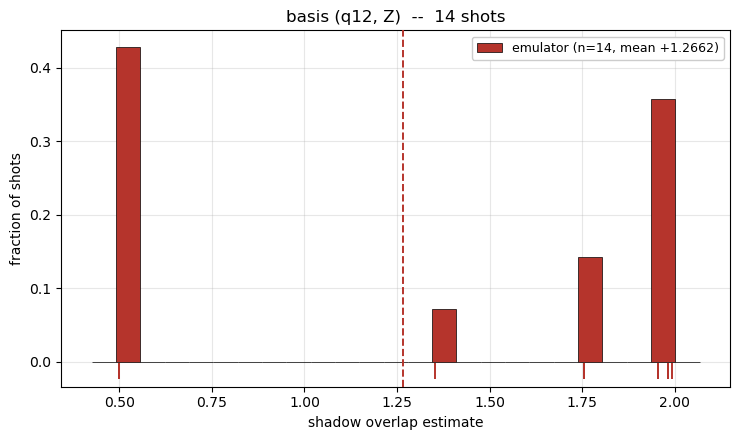

basis      (q12, Z)
job        MultiRegister_Circ_(12, 2)-2026_08_26-16-37-17 [shared Z batch, portal paste]
saved      2026-08-27 13:50:35   raw counts: no
emulator   +1.2662 +/- 0.1891 (sem)   n=14   range [+0.500, +1.993]
           values: [0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 1.3515, 1.7545, 1.7545, 1.9545, 1.9545, 1.9823, 1.9823, 1.993]
simulating 600 noiseless shots for (12, 2) ...


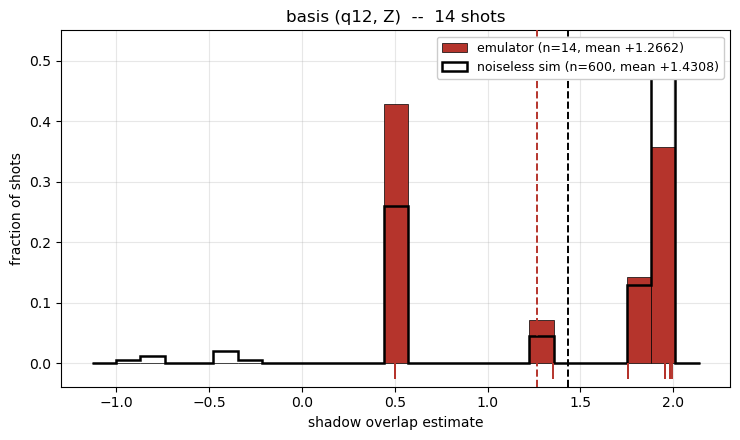

basis      (q12, Z)
job        MultiRegister_Circ_(12, 2)-2026_08_26-16-37-17 [shared Z batch, portal paste]
saved      2026-08-27 13:50:35   raw counts: no
emulator   +1.2662 +/- 0.1891 (sem)   n=14   range [+0.500, +1.993]
           values: [0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 1.3515, 1.7545, 1.7545, 1.9545, 1.9545, 1.9823, 1.9823, 1.993]
sim        +1.4308 +/- 0.0305 (sem)   n=600
difference -0.1645  (0.9 sigma)


{'basis': (12, 2),
 'emu': array([1.98232371, 0.5       , 1.99295393, 0.5       , 0.5       ,
        1.95451873, 1.95451873, 1.35147933, 0.5       , 1.75453141,
        1.75453141, 1.98232371, 0.5       , 0.5       ]),
 'sim': array([ 1.99295393,  1.95451873,  1.98232371,  0.5       ,  1.99295393,
         1.98232371,  1.98232371,  1.95451873,  0.5       ,  0.5       ,
         1.98232371,  1.98232371,  1.99295393,  1.98232371,  1.98232371,
         1.98232371, -0.75453141,  1.98232371,  0.5       ,  1.75453141,
         1.75453141,  1.35147933,  1.99295393,  1.75453141,  0.5       ,
         1.75453141,  0.5       ,  1.98232371,  1.99295393,  1.99295393,
         1.95451873,  0.5       , -0.95451873,  1.99295393,  1.98232371,
         0.5       ,  1.75453141,  1.98232371,  1.98232371,  1.98232371,
         1.99295393,  1.35147933, -0.35147933,  1.99295393,  1.94507252,
         1.35147933,  1.99295393,  1.94507252,  1.95451873, -0.75453141,
         1.99295393,  0.5       ,  1.954518

In [13]:
# ---------- inspect one basis from the store ----------
def plot_basis(basis, sim_values=None, sim_shots=0, bins=25, path=SHADOW_STORE,
               floor=None, title=None):
    """Histogram one stored basis, optionally against the classical simulation.

    basis      : (target_qubit, pauli_id) -- qiskit index, 0=X 1=Y 2=Z
    sim_values : pre-computed noiseless estimates for this basis, or
    sim_shots  : >0 to generate them now with run_multiple_shadow_overlaps_cached
                 (~10 s; needs `target_state` in memory)
    floor      : optional vertical reference line (e.g. 0.5)
    """
    basis = (int(basis[0]), int(basis[1]))
    store = load_shadow_results(path)
    if basis not in store:
        print(f"basis (q{basis[0]},{PAULIS[basis[1]]}) is not in the store"); return None
    rec = store[basis]
    est = np.asarray(rec["estimates"], dtype=float)

    sim = None
    if sim_values is not None:
        sim = np.asarray(sim_values, dtype=float)
    elif sim_shots:
        print(f"simulating {sim_shots} noiseless shots for {basis} ...")
        sim = np.asarray(run_multiple_shadow_overlaps_cached(
            target_state, target_state, 28, sim_shots, basis_select=basis), dtype=float)

    lo = min(est.min(), sim.min() if sim is not None else est.min())
    hi = max(est.max(), sim.max() if sim is not None else est.max())
    pad = 0.05 * max(hi - lo, 1e-9)
    edges = np.linspace(lo - pad, hi + pad, bins + 1)

    fig, ax = plt.subplots(figsize=(7.5, 4.5))
    ax.hist(est, bins=edges, weights=np.full(len(est), 1 / len(est)),
            color="#b5342c", edgecolor="black", lw=0.5, zorder=2,
            label=f"emulator (n={len(est)}, mean {est.mean():+.4f})")
    ax.axvline(est.mean(), color="#b5342c", ls="--", lw=1.4, zorder=4)
    ax.plot(est, np.full(len(est), -0.012), "|", ms=11, color="#b5342c",
            mew=1.4, clip_on=False, zorder=5)          # every individual shot

    if sim is not None:
        ax.hist(sim, bins=edges, weights=np.full(len(sim), 1 / len(sim)),
                histtype="step", color="black", lw=1.8, zorder=3,
                label=f"noiseless sim (n={len(sim)}, mean {sim.mean():+.4f})")
        ax.axvline(sim.mean(), color="black", ls="--", lw=1.4, zorder=4)
    if floor is not None:
        ax.axvline(floor, color="#52514e", ls=":", lw=1.5, zorder=1, label=f"floor = {floor}")

    ax.set_xlabel("shadow overlap estimate"); ax.set_ylabel("fraction of shots")
    ax.set_title(title or f"basis (q{basis[0]}, {PAULIS[basis[1]]})"
                          f"  --  {rec['n_shots']} shots")
    ax.legend(fontsize=9, framealpha=1.0, loc="upper right")
    ax.grid(alpha=0.3, zorder=0)
    plt.tight_layout(); plt.show()

    sem = est.std(ddof=1) / np.sqrt(len(est)) if len(est) > 1 else float("nan")
    print(f"basis      (q{basis[0]}, {PAULIS[basis[1]]})")
    print(f"job        {rec.get('job_name')}")
    print(f"saved      {rec.get('saved')}   raw counts: {'yes' if rec.get('raw_counts') else 'no'}")
    print(f"emulator   {est.mean():+.4f} +/- {sem:.4f} (sem)   "
          f"n={len(est)}   range [{est.min():+.3f}, {est.max():+.3f}]")
    print(f"           values: {np.round(np.sort(est), 4).tolist()}")
    if sim is not None:
        s_sem = sim.std(ddof=1) / np.sqrt(len(sim))
        gap = est.mean() - sim.mean()
        print(f"sim        {sim.mean():+.4f} +/- {s_sem:.4f} (sem)   n={len(sim)}")
        print(f"difference {gap:+.4f}  ({abs(gap) / np.hypot(sem, s_sem):.1f} sigma)")
    return {"basis": basis, "emu": est, "sim": sim, "mean": float(est.mean()), "sem": float(sem)}

analyse_basis=(12,2)
plot_basis(analyse_basis)                    # just the emulator data
plot_basis(analyse_basis, sim_shots=600)  # with the noiseless reference (~10 s)


### (0,7) 7 Shots

originaly ran with 0,0 but in hindsight edited to 0,7 due to qubit ordering

In [ ]:
#Circuit Upload.
basis_choice=(0,7)
tk_circ=build_tket_circuit_from_tk_no_measure(tk_circ_clean,basis_choice)

import datetime

jobname_suffix = datetime.datetime.now().strftime("%Y_%m_%d-%H-%M-%S")
name=f"MultiRegister_Circ_{basis_choice}-{jobname_suffix}"
print(name)
circuits = [tk_circ]
backend = qnx.QuantinuumConfig(device_name="H2-1Eq") 
compiled_circuits_ref = quntinuum_compilation(
    circuits = circuits,
    backend= backend,
    name=name
)
compiled_circuits = [
    circuit.download_circuit() for circuit in compiled_circuits_ref
]

Target Qubit is:  0
Will measure  X  at target qubit
MultiRegister_Circ_(0, 0)-2026_08_27-13-35-05


In [ ]:
#EXECUTE
name="MultiRegister_Circ_(0, 0)-2026_08_27-13-35-05q"
shots=8
job_ref = qnx.start_execute_job(
    programs=compiled_circuits_ref,
    n_shots=[shots]* len(compiled_circuits_ref),
    backend_config=backend,
    name=name
)
print(name)
with open(f'{name}_results.pkl', 'wb') as file:
    pickle.dump([job_ref], file)
with open(f'{name}_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)

MultiRegister_Circ_(0, 0)-2026_08_27-13-35-05


this cell is made as markdown so it doesnt run by accident
 --- re-file the 8-shot job stored as (0,0): the rotation actually landed on
     tket A0[0] = qiskit qubit 7, so this is basis (7,0). Raw counts -> no re-run.
OLD, NEW = (0, 0), (7, 0)
store = load_shadow_results()
raw = store[OLD]["raw_counts"]
job = store[OLD]["job_name"]

bitstring_counts = {
    nexus_to_statevector_order(''.join(map(str, bit_tuple)), PERM): count
    for bit_tuple, count in raw.items()
}
est = get_shadows_from_basis_single(bitstring_counts, target_state, NEW,
                                    title=f"re-filed {OLD} -> {NEW}")

store = load_shadow_results()
store.pop(OLD, None)
_atomic_write(store, SHADOW_STORE)
save_shadow_result(NEW, est, job_name=f"{job} [re-filed from {OLD}: tket/qiskit index fix]",
                   raw_counts=raw)
shadow_coverage(freq_sorted)


1 job ref(s) loaded: id=UUID('ec33e4a6-e450-48e1-be4f-8854a5ddd12d') annotations=Annotations(name='MultiRegister_Circ_(0, 0)-2026_08_27-13-35-05', description='', properties=OrderedDict(), created=datetime.datetime(2026, 8, 27, 5, 51, 25, 355697, tzinfo=TzInfo(0)), modified=datetime.datetime(2026, 8, 27, 5, 51, 25, 355697, tzinfo=TzInfo(0))) job_type=<JobType.EXECUTE: 'execute'> last_status=<JobStatusEnum.SUBMITTED: 'SUBMITTED'> last_message='' last_status_detail=JobStatus(status=<JobStatusEnum.SUBMITTED: 'SUBMITTED'>, message='Job has been submitted to Nexus.', error_detail=None, completed_time=None, queued_time=None, submitted_time=datetime.datetime(2026, 8, 27, 5, 51, 25, 361807, tzinfo=datetime.timezone.utc), running_time=None, cancelled_time=None, error_time=None, queue_position=None, cost=None) project=ProjectRef(id=UUID('fe16751a-26f9-4cef-9ff4-ae6cda1b157e'), annotations=Annotations(name='MultiRegister Encoding', description=None, properties=OrderedDict(), created=datetime.date

Unknown OpType in BackendInfo: `RZZ`, will omit from BackendInfo. Consider updating your pytket version.
Unknown OpType in BackendInfo: `Rxxyyzz`, will omit from BackendInfo. Consider updating your pytket version.
Unknown OpType in BackendInfo: `U1q`, will omit from BackendInfo. Consider updating your pytket version.
Unknown OpType in BackendInfo: `ZZ`, will omit from BackendInfo. Consider updating your pytket version.


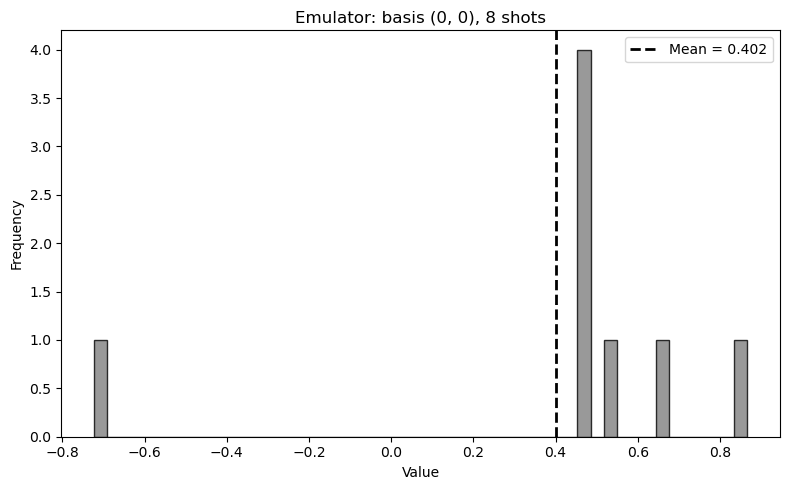

saved basis (q=0, X): 8 shots, mean +0.4019  ->  shadow_results_by_basis.pkl


{(0,
  2): {'estimates': array([1.99933627, 1.99933627, 1.99970663, 1.36867982, 0.33988896,
         1.95451873, 1.99933627, 1.99295393, 1.95451873, 1.96260872]), 'raw_counts': {'0011000000100011010100100000': 1,
   '0001010101101000010101100001': 1,
   '0011000110100101100110000010': 1,
   '0011000100001100010100100011': 1,
   '0000110010101010010100100101': 1,
   '0000111010010101101000100101': 1,
   '0010110010111011010100100101': 1,
   '0011000010110000011110100101': 1,
   '0011000010110001011100100101': 1,
   '0011000100001010011110100101': 1,
   '0011000100010010110100100101': 1,
   '0011000100010011011110100101': 1,
   '0011000100010111010100100101': 1,
   '0101100111011011010100100101': 1,
   '0010110001101011011111000101': 1,
   '0011000001001101010101000101': 1,
   '0011000011000101010101000101': 1,
   '0011000011100111010101000101': 1,
   '0011000011110011010101000101': 1,
   '0011000101001000011111000101': 1,
   '0011000111001101010101000101': 1,
   '00110010000001100101010

In [12]:
#ANALYSE AND SAVE RESULTS
name="MultiRegister_Circ_(0, 0)-2026_08_27-13-35-05"
basis_choice = (0, 0)
import pickle
import qnexus as qnx
with open(f'{name}_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)
print(len(job_refs), "job ref(s) loaded:", job_refs[0])

execute_job_result_refs = qnx.jobs.results(job_refs[0])
result = execute_job_result_refs[0].download_result()
result_counts = result.get_counts()

bitstring_counts = {
        nexus_to_statevector_order(''.join(map(str, bit_tuple)), PERM): count
    for bit_tuple, count in result_counts.items()
}
shots = freq_sorted[basis_choice]     # derived from the basis, not from run order


shadow_overlap = get_shadows_from_basis_single(bitstring_counts, target_state, basis_choice)
save_shadow_result(basis_choice, shadow_overlap, job_name=name, raw_counts=result_counts)


### (_,2) 194 Shots

cost of this is 338.21 hardware credits

In [ ]:
#Circuit Upload.
basis_choice=(12,2)
tk_circ=build_tket_circuit_from_tk_no_measure(tk_circ_clean,basis_choice)

import datetime

jobname_suffix = datetime.datetime.now().strftime("%Y_%m_%d-%H-%M-%S")
name=f"MultiRegister_Circ_{basis_choice}-{jobname_suffix}"
print(name)
circuits = [tk_circ]
backend = qnx.QuantinuumConfig(device_name="H2-1Eq",noisy_simulation=False) 
compiled_circuits_ref = quntinuum_compilation(
    circuits = circuits,
    backend= backend,
    name=name
)
compiled_circuits = [
    circuit.download_circuit() for circuit in compiled_circuits_ref
]

Target Qubit is:  12
Will measure  Z  at target qubit
MultiRegister_Circ_(12, 2)-2026_08_26-16-37-17


In [ ]:
#execute emulator (noisy job): note that this had an error so we hardcopy the bitstrings from the website in for the analysis here
name="MultiRegister_Circ_(12, 2)-2026_08_26-13-00-34q"
shots=194
job_ref = qnx.start_execute_job(
    programs=compiled_circuits_ref,
    n_shots=[shots]* len(compiled_circuits_ref),
    backend_config=backend,
    name=name
)
print(name)
with open(f'{name}_results.pkl', 'wb') as file:
    pickle.dump([job_ref], file)
with open(f'{name}_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)

MultiRegister_Circ_(12, 2)-2026_08_26-13-00-34


194 shots, 194 distinct
ancilla P(1) after remap = 0.026  (should be ~0; if it is ~0.5, flip portal_is_reversed)
Measuring on qubit 0 with ['0011000010110110010100101000', '0001100100101010011011001110', '0011000111101110101010001101', '0011000100001010011110100101', '0011001011101011001100001010', '0011001011000100001010001010', '0010100110101011010101110111', '0011000100001110001000001110', '0011000100001100010100100011', '0011001011001000010101001111']
Measuring on qubit 1 with ['0011001010010011010101000101', '0011000110101000110010001010', '0011000010110001011100100101', '0011001001001000010101001101']
Measuring on qubit 2 with ['0011000101001000011111000101', '0011010111000111011111101100', '0011000001000111010101001110', '0011000111010011111000000110', '0011001100101011111001000101', '0001100010101100010101101100', '0011001110101100010101000101', '0011000100011110010100110001', '0011000010111111011110101000', '0001000111001110011111101100']
Measuring on qubit 3 with ['0110100010

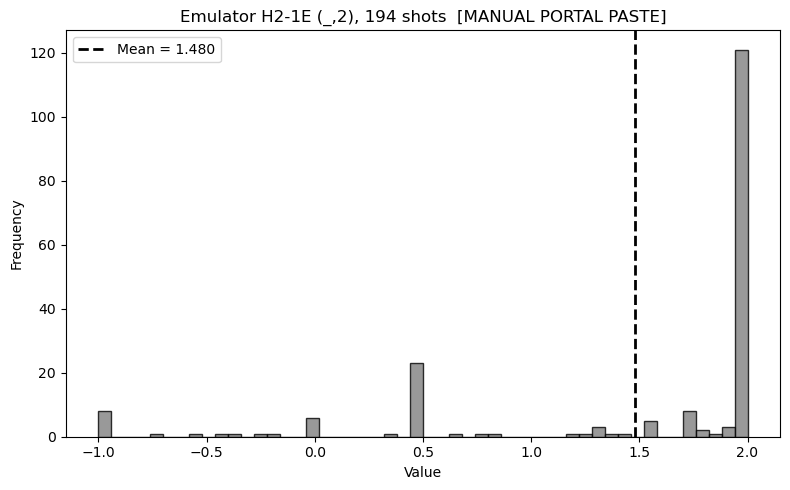

mean = 1.3756694748779552


In [28]:
# =============================================================================
#  ONE-OFF: emulator counts pasted by hand from the Nexus web portal.
#  Job MultiRegister_Circ_(12, 2)-2026_08_26-16-37-17 (H2-1E, noisy, 194 shots).
#  The execute cell was run twice, the duplicate cancelled and deleted, and Nexus
#  unlinked the results from the surviving job ref -- qnx.jobs.results() raises
#  ZeroMatches and the .pkl is dead. Only the portal still had the counts.
#  Everything below is normal machinery; the ONLY hand-entered thing is the list.
# =============================================================================



# ---- the only hand-entered data ----------------------------------------------
PORTAL_SHOTS = [
    "0000000101100000010001101010", "0000011100101010110100001010", "0000100001100011010010110011",
    "0000110101100010000110001010", "0001010100011001010101001010", "0001010100011101001010110100",
    "0001010101011001011101101010", "0001010101100001011000001111", "0001010101100001011000101110",
    "0001010101100010000101001111", "0001010101100010001001011010", "0001010101100010001001101111",
    "0001010101100010001011101010", "0001010110110011101101101010", "0001011001011000110101101111",
    "0001011001100000100110101010", "0001011001100001100010101010", "0001011001100001110011101010",
    "0001011001100001111001101010", "0001011001100010100100001111", "0001011001100011100110101010",
    "0001011001100100000011001010", "0001011001100100000101101010", "0001011001100101001001101010",
    "0001011001100101010100001101", "0001011001100101010101111001", "0001011001100110010101111100",
    "0001011001100111000100001010", "0001011001100111010110001010", "0001100001100011101001111100",
    "0001100101100011000011001111", "0001101001100101010101101111", "0001101001100110010111001010",
    "0001101001100111010010111110", "0001111101001001010010101010", "0010000101011001011000101010",
    "0010000101011001011010001010", "0010000101100001010010001010", "0010000101100001010110101011",
    "0010000101100001011011001010", "0010000101100001011011101010", "0010000101100001011111101111",
    "0010000101100010001011001101", "0010000101100011100011001010", "0010000101100111100011001001",
    "0010001001011000110100001010", "0010001001011000110111101101", "0010001001011111110010101010",
    "0010001001100001010110101010", "0010001001100001100110101010", "0010001001100011100111001010",
    "0010001001100100000101101110", "0010001001100101000010101010", "0010001001100110000111101111",
    "0010001001100110010110101101", "0010001001100111000100001010", "0010001011000011100010101010",
    "0010001011011100000111001010", "0010100001100001010100010111", "0010100001100001010101100000",
    "0010100001100001010101111001", "0010100001100001010110110001", "0010100001100001010110111110",
    "0010100001100001011011001001", "0010100001100001110111001101", "0010100001100010000010111000",
    "0010100001100010000110101101", "0010100001100010000111100010", "0010100001100010100010101001",
    "0010100001100010110110100100", "0010100001100011010100000001", "0010100001100011010100011001",
    "0010100001100011011011101011", "0010100001100011100010110010", "0010100001100011100101100111",
    "0010100001100100000100010001", "0010100001100101100010000101", "0010100001100101110101100110",
    "0010100001100110010100010101", "0010100001100111010111001100", "0010100010011001010100000001",
    "0010101110101010000101101010", "0010110001100011100110100110", "0010110101011001011010001111",
    "0010110101011001011101110110", "0010110101100001000010001010", "0010110101100001010110001001",
    "0010110101100010000001110000", "0010110101100010000010101111", "0010110101100111110100101010",
    "0010110110000010001010001010", "0010110110000011010101001010", "0010110110000011100100101101",
    "0010110111100011001111001010", "0010111001001011110101101010", "0010111001100000100100001111",
    "0010111001100100100101101010", "0010111101001001010010101010", "0010111111010011111000001010",
    "0010111111011100000100000111", "0011000001100010000010101011", "0011001001100000110101100010",
    "0011001001100001100010101010", "0011001001100110110100001010", "0011001001100111000101101010",
    "0011001100001001010010101011", "0011001100001001010101101010", "0011001100100001010101101010",
    "0011001100100010000101101010", "0011001100100011100111001111", "0011001100100100000010101010",
    "0011001100101001010101101101", "0011001100101010110101101111", "0011001100101011100101100101",
    "0011001100101101010111101010", "0011001100110001010110001010", "0011001100110010000101101010",
    "0011001100110100001111101111", "0011001101000001100101101101", "0011001101000010000111001110",
    "0011001101010001010011101010", "0011001101100001010101101110", "0011001101101001010010111111",
    "0011001101101010110111101110", "0011001101101011100011101111", "0011001101110001011001101111",
    "0011001110000011100010101111", "0011001110001010000010101010", "0011001110001011000011001010",
    "0011001110010010110101101010", "0011001110100010000010101010", "0011001110100010000011111111",
    "0011001110101001010101101111", "0011001110111011010111001101", "0011001111000001010111001101",
    "0011001111010100000111001111", "0011001111100001010100001010", "0011001111101001010101101010",
    "0011001111101010001100001010", "0011010001000001010101100000", "0011010001100001010011110010",
    "0011010001100001010100000001", "0011010001100001010101110010", "0011010001100011100111001010",
    "0011010001100011110111010101", "0011010101100100110100101010", "0011011001100000010100001010",
    "0011011001100011110001001010", "0011011001100100100100001010", "0011011001100110010111001010",
    "0011011001110111100010101010", "0011100001100010000101101110", "0011100001100010000111000100",
    "0011100001100010110101100110", "0011100101100001010111001111", "0011100101100010000100001010",
    "0011100101100011111011101111", "0011100101110001010101101111", "0011100110010001010000001010",
    "0011101000100010110100001000", "0011101000110010010101001101", "0011101001100000100011101010",
    "0011101001100000100101101101", "0011101001100001100101101010", "0011101001100100100100001010",
    "0011101001100111011000001010", "0011101001111000001000001010", "0011101011100100100101101101",
    "0011110000000011000010111101", "0011110001100001010100000111", "0011110001100011000111011110",
    "0011110001100011100110100101", "0011110001100110110101101110", "0011110101100011011111001010",
    "0011110101101010000111100001", "0011111001100101100100001010", "0100000101011011101110101010",
    "0100000101100011000001001010", "0100001111010001010100001000", "0100010101100010001111001010",
    "0100110101100011100010101000", "0100111001100111010100001010", "0100111001100111010101101010",
    "0101100001100100110100011001", "0101100010000101101001111000", "0101101001100100111000001010",
    "0101110101100010000110101110", "0101111101010011010101101010", "0110011111100010110111001010",
    "1010001010011110001101101010", "1010001101100101110110101010", "1011000000101110101110111010",
    "1011000001011010100101100100", "1011001110000001011001101010",
]

# ---- run ----------------------------------------------------------------------
bitstring_counts = counts_from_portal_paste(PORTAL_SHOTS, qc)
assert sum(bitstring_counts.values()) == 194

target_state = mre.simulate_statevector(qc)
shadow_results_all_2_emulator = get_shadows_from_basis_allcomp(
    bitstring_counts, target_state,
    "Emulator H2-1E (_,2), 194 shots  [MANUAL PORTAL PASTE]", verbose=False)
print("mean =", float(np.mean(shadow_results_all_2)))


194 shots, 194 distinct
ancilla P(1) after remap = 0.026  (should be ~0; if it is ~0.5, flip portal_is_reversed)
Measuring on qubit 0 with ['0011001110101110011000001010', '0011001000001000100010001010', '0011010101101111011101101100', '0011001101101011011100001111', '0011000000101000010101001101', '0011000010110111010100101000', '0011000101101101001000001010', '0011000100010111010100100101', '0011000100010110011010101000', '0111001001001011011011001110']
Measuring on qubit 1 with ['1100000010110011010101101100', '0011001110001011010101001100', '0000010010101011010101101100', '0011001001001000010101001101']
Measuring on qubit 2 with ['0001000100001011010101101100', '0000000110000101111010001111', '0011000000100011010100100000', '0011000110000010010100110000', '0011001100101110010101000110', '0011000100000101110000001010', '0011000110101000000010001010', '0011000010110110010010001010', '0100100101101011010101101100', '0100110010101000000010001010']
Measuring on qubit 3 with ['0011001001

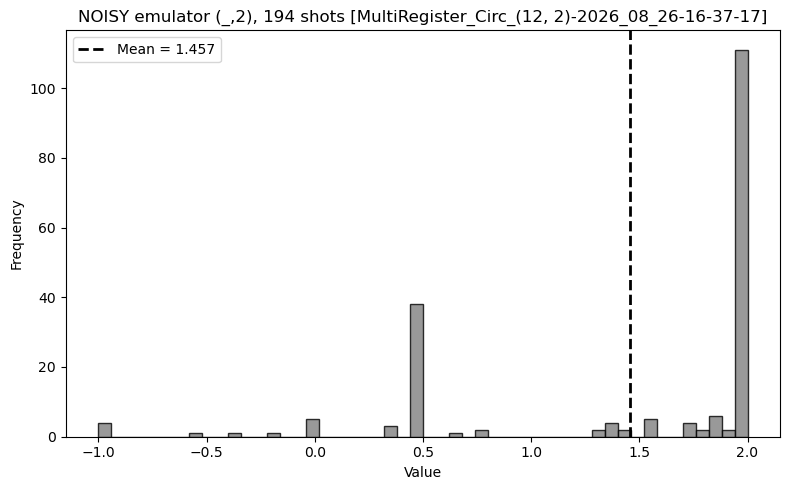

saved basis (q=0, Z): 10 shots, mean +1.7571  ->  shadow_results_by_basis.pkl
saved basis (q=1, Z): 4 shots, mean +0.9299   [WARNING: no raw counts stored]  ->  shadow_results_by_basis.pkl
saved basis (q=2, Z): 10 shots, mean +1.6186   [WARNING: no raw counts stored]  ->  shadow_results_by_basis.pkl
saved basis (q=3, Z): 5 shots, mean +1.4926   [WARNING: no raw counts stored]  ->  shadow_results_by_basis.pkl
saved basis (q=4, Z): 8 shots, mean +1.9916   [WARNING: no raw counts stored]  ->  shadow_results_by_basis.pkl
saved basis (q=5, Z): 8 shots, mean +1.6210   [WARNING: no raw counts stored]  ->  shadow_results_by_basis.pkl
saved basis (q=6, Z): 7 shots, mean +1.5711   [WARNING: no raw counts stored]  ->  shadow_results_by_basis.pkl
saved basis (q=7, Z): 6 shots, mean +1.3944   [WARNING: no raw counts stored]  ->  shadow_results_by_basis.pkl
saved basis (q=8, Z): 7 shots, mean +1.1193   [WARNING: no raw counts stored]  ->  shadow_results_by_basis.pkl
saved basis (q=9, Z): 1 shots, me

{(0,
  2): {'estimates': array([1.99933627, 1.99933627, 1.99970663, 1.36867982, 0.33988896,
         1.95451873, 1.99933627, 1.99295393, 1.95451873, 1.96260872]), 'raw_counts': {'0011000000100011010100100000': 1,
   '0001010101101000010101100001': 1,
   '0011000110100101100110000010': 1,
   '0011000100001100010100100011': 1,
   '0000110010101010010100100101': 1,
   '0000111010010101101000100101': 1,
   '0010110010111011010100100101': 1,
   '0011000010110000011110100101': 1,
   '0011000010110001011100100101': 1,
   '0011000100001010011110100101': 1,
   '0011000100010010110100100101': 1,
   '0011000100010011011110100101': 1,
   '0011000100010111010100100101': 1,
   '0101100111011011010100100101': 1,
   '0010110001101011011111000101': 1,
   '0011000001001101010101000101': 1,
   '0011000011000101010101000101': 1,
   '0011000011100111010101000101': 1,
   '0011000011110011010101000101': 1,
   '0011000101001000011111000101': 1,
   '0011000111001101010101000101': 1,
   '00110010000001100101010

In [39]:
# =============================================================================
#  File the NOISY emulator (_,2) Z batch into shadow_results_by_basis.pkl
#  Source: PORTAL_SHOTS -- the 194 bitstrings hand-pasted off the Nexus web
#  portal (job MultiRegister_Circ_(12, 2)-2026_08_26-16-37-17, H2-1E noisy).
#  The job ref was deleted, so this list is the ONLY copy of that data.
#  Recomputes from PORTAL_SHOTS rather than reusing shadow_results_all_2_emulator,
#  so it doesn't depend on anything else having run correctly first.
# =============================================================================
Z_JOB_NAME = "MultiRegister_Circ_(12, 2)-2026_08_26-16-37-17"
sizes_z = [10,4,10,5,8,8,7,6,7,1,6,5,14,5,10,6,3,6,6,4,12,5,10,8,3,6,9,10]

z_counts = counts_from_portal_paste(PORTAL_SHOTS, qc)
assert sum(z_counts.values()) == sum(sizes_z) == 194

z_estimates = np.asarray(get_shadows_from_basis_allcomp(
    z_counts, target_state, f"NOISY emulator (_,2), 194 shots [{Z_JOB_NAME}]",
    verbose=False), dtype=float)
assert len(z_estimates) == 194

# get_shadows_from_basis_allcomp returns a flat list in segment order:
# sizes_z[0] shots for qubit 0, then sizes_z[1] for qubit 1, ... -- split it back out.
start = 0
for q, size in enumerate(sizes_z):
    save_shadow_result((q, 2), z_estimates[start:start + size],
                       job_name=f"{Z_JOB_NAME} [shared Z batch, portal paste]",
                       raw_counts=z_counts if q == 0 else None)
    start += size

print(f"\nfiled 28 Z bases, {len(z_estimates)} shots, pooled mean "
      f"{z_estimates.mean():+.4f}")
shadow_coverage(freq_sorted)


In [ ]:
#execute emulator (noisfree job)
name="MultiRegister_Circ_(12, 2)-2026_08_26-16-37-17q"
shots=194
job_ref = qnx.start_execute_job(
    programs=compiled_circuits_ref,
    n_shots=[shots]* len(compiled_circuits_ref),
    backend_config=backend,
    name=name
)
print(name)
with open(f'{name}_results.pkl', 'wb') as file:
    pickle.dump([job_ref], file)
with open(f'{name}_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)

MultiRegister_Circ_(12, 2)-2026_08_26-16-37-17


Unknown OpType in BackendInfo: `RZZ`, will omit from BackendInfo. Consider updating your pytket version.
Unknown OpType in BackendInfo: `Rxxyyzz`, will omit from BackendInfo. Consider updating your pytket version.
Unknown OpType in BackendInfo: `U1q`, will omit from BackendInfo. Consider updating your pytket version.
Unknown OpType in BackendInfo: `ZZ`, will omit from BackendInfo. Consider updating your pytket version.


Measuring on qubit 0 with ['0110000110001000011011101100', '0011000110011010010100101110', '0011000011000101110000001010', '0100110100001011011011101100', '0011001011001011010101000101', '0011001111001000010101001011', '0011001001110010010100101011', '0011000111000011010100101110', '0011000100001000011110001010', '0011000100001110100010001001']
Measuring on qubit 1 with ['0011000010101110111100001010', '0011000110001000011011001100', '0011000010100101110110001111', '0101100100000101010101101100']
Measuring on qubit 2 with ['0011000100001101010110001111', '0011000100000000010100101100', '0011000010100101010100101011', '0111110100001011011011101100', '0011000111000101000000001010', '0011000100010000011010001010', '0111000111001100011011101100', '0011000010101100111010001010', '0011001000101110100101001000', '0011001110000101011101001000']
Measuring on qubit 3 with ['0100101001101110011111101100', '0101100100001011010101101100', '0011000110011001101010001111', '001100010000111001011000110

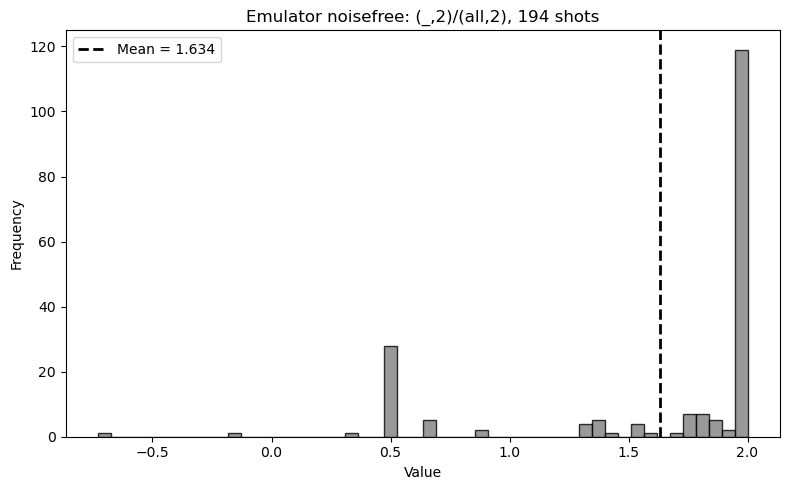

[np.float64(1.9997066269528838), np.float64(1.754531406973106), np.float64(1.9993362688988152), np.float64(1.9997066269528836), np.float64(1.992952207729231), np.float64(1.7356255043896827), np.float64(1.98232370771074), np.float64(1.7545314069731053), np.float64(1.9993362688988148), np.float64(0.8622375026002759), np.float64(1.9947353378072612), np.float64(-0.16300851037712472), np.float64(0.6491843309727823), np.float64(1.9992891006538427), np.float64(1.99692101125128), np.float64(-0.7274474560369599), np.float64(1.8290397186707499), np.float64(1.9983187606957624), np.float64(1.8371244473537522), np.float64(1.8371244473537525), np.float64(1.998318760695763), np.float64(1.8371244473537527), np.float64(1.3171066846807198), np.float64(1.3171066846807202), np.float64(1.9999994674236823), np.float64(1.9999994674236823), np.float64(1.99990642230118), np.float64(1.9961570318186332), np.float64(1.9999994674236823), np.float64(1.999757461286697), np.float64(1.9999999999197398), np.float64(1.9

In [ ]:
#NOISEFREE CHECK
name="MultiRegister_Circ_(12, 2)-2026_08_26-16-37-17"
target = mre.simulate_statevector(qc)

with open(f'{name}_results.pkl', 'rb') as file:
    job_refs = pickle.load(file)
execute_job_result_refs = qnx.jobs.results(job_refs[0])
execute_job_result_refs.df()
# Get the results of the execution
result = execute_job_result_refs[0].download_result()
result_counts=result.get_counts()
from pytket.extensions.qiskit import qiskit_to_tk

def nexus_bit_to_qiskit_index(qc):
    """PERM[i] = Qiskit global qubit index measured into classical bit c[i].
       pytket sorts qubits alphabetically by register (A0,A1,A2,A3,I,S,anc);
       Qiskit indexes them as declared (S,I,A0..A3,anc)."""
    names = [f"{q._register.name}[{q._index}]" for q in qc.qubits]
    tk = qiskit_to_tk(qc); tk.measure_all()
    wiring = {str(c.args[1]): str(c.args[0]) for c in tk if c.op.type.name == "Measure"}
    return [names.index(wiring[f"c[{i}]"]) for i in range(len(names))]

PERM = nexus_bit_to_qiskit_index(qc)

def nexus_to_statevector_order(b, perm=PERM):
    n = len(perm); s = [None] * n
    for i, g in enumerate(perm):
        s[n - 1 - g] = b[i]          # global qubit g sits at binary_repr position n-1-g
    return "".join(s)

bitstring_counts = {
    nexus_to_statevector_order(''.join(map(str, bit_tuple))): count
    for bit_tuple, count in result_counts.items()
}


target_state = mre.simulate_statevector(qc)
shadow_results_all_2=get_shadows_from_basis_allcomp(bitstring_counts,target_state,"Emulator noisefree: (_,2)/(all,2), 194 shots",verbose=False)
print(shadow_results_all_2)

# HARDWARE RUN DANGER

## Plotting

In [33]:
# ============================ HARDWARE RUN: SETUP ============================
import os, io, json, time, pickle, shutil, inspect, hashlib, datetime
import numpy as np, matplotlib.pyplot as plt

for _n in ("qc", "tk_circ_clean", "PERM", "target_state", "PAULIS",
           "nexus_to_statevector_order", "build_tket_circuit_from_tk_no_measure",
           "get_shadows_from_basis_single", "compute_local_overlap",
           "build_conditional_postmeasurement_single_qubit"):
    assert _n in dir(), f"run the main functions cell first -- {_n} is not defined"

RUN          = "hardware"
DEVICE       = "H2-1"                          # strip the q to arm
SHADOW_STORE = "shadow_results_hardware.pkl"
JOB_INDEX    = "shadow_jobs_hw.json"
POOL_PKL     = "compiled_pool_hw.pkl"
JOURNAL      = "shadow_journal_hw.jsonl"
PLAN_FILE    = "shadow_plan_hw.json"
BACKUP_DIR   = "backups"
N_SHOTS_HW, PLAN_SEED, Z_SHUFFLE_SEED = 200, 2026, 7

# ---- plan: drawn once, then loaded from disk forever ----
if os.path.exists(PLAN_FILE):
    freq_sorted = {tuple(int(x) for x in k.strip("()").split(",")): v
                   for k, v in json.load(open(PLAN_FILE)).items()}
else:
    from collections import Counter
    _rng = np.random.default_rng(PLAN_SEED)
    _draws = [(int(_rng.integers(0, 28)), int(_rng.integers(0, 3))) for _ in range(N_SHOTS_HW)]
    freq_sorted = dict(sorted(Counter(_draws).items(), key=lambda x: (x[0][0], x[0][1])))
    json.dump({str(k): v for k, v in freq_sorted.items()}, open(PLAN_FILE, "w"), indent=1)
    print(f"NEW plan written to {PLAN_FILE} (seed {PLAN_SEED})")
SIZES_Z = [freq_sorted.get((q, 2), 0) for q in range(28)]      # length 28, zeros allowed

# ---- storage ----
def _atomic_write(obj, path):
    tmp = path + ".tmp"
    with open(tmp, "wb") as f: pickle.dump(obj, f)
    for _ in range(30):
        try: os.replace(tmp, path); return
        except PermissionError: time.sleep(0.5)
    os.replace(tmp, path)

def load_shadow_results(path=None):
    path = path or SHADOW_STORE
    if not os.path.exists(path): return {}
    with open(path, "rb") as f: return pickle.load(f)

def code_fingerprint():
    sha = lambda b: hashlib.sha256(b).hexdigest()[:12]
    return {"qpy":   sha(open("mre_qc.qpy", "rb").read()),
            "build": sha(inspect.getsource(build_tket_circuit_from_tk_no_measure).encode()),
            "post":  sha(inspect.getsource(get_shadows_from_basis_single).encode()),
            "perm":  sha(str(PERM).encode())}

def _counts_to_json(raw):
    if raw is None: return None
    return {("".join(map(str, k)) if isinstance(k, (tuple, list)) else str(k)): int(v)
            for k, v in raw.items()}

def journal_append(basis, estimates, job_name=None, raw_counts=None, note=None, path=None):
    rec = {"basis": [int(basis[0]), int(basis[1])],
           "estimates": [float(x) for x in estimates], "n_shots": len(estimates),
           "job_name": job_name, "raw_counts": _counts_to_json(raw_counts),
           "note": note, "written": time.strftime("%Y-%m-%d %H:%M:%S")}
    with open(path or JOURNAL, "a", encoding="utf-8") as f:
        f.write(json.dumps(rec) + "\n"); f.flush(); os.fsync(f.fileno())

def snapshot(path=None):
    path = path or SHADOW_STORE
    os.makedirs(BACKUP_DIR, exist_ok=True)
    if os.path.exists(path):
        shutil.copy2(path, os.path.join(
            BACKUP_DIR, f"{os.path.basename(path)}.{time.strftime('%Y%m%d-%H%M%S')}"))

def save_shadow_result(basis, estimates, job_name=None, raw_counts=None,
                       path=None, overwrite=True, note=None):
    """Journal (append-only) -> snapshot -> update the store. 0-shot bases are skipped."""
    path = path or SHADOW_STORE
    b = (int(basis[0]), int(basis[1])); est = np.asarray(estimates, dtype=float)
    if len(est) == 0:
        print(f"  skip (q{b[0]},{PAULIS[b[1]]}): 0 shots"); return load_shadow_results(path)
    store = load_shadow_results(path)
    if b in store and not overwrite:
        raise KeyError(f"{b} already stored ({store[b]['n_shots']} shots)")
    journal_append(b, est, job_name, raw_counts, note or json.dumps(code_fingerprint()))
    snapshot(path)
    prev = store.get(b)
    store[b] = {"estimates": est, "raw_counts": dict(raw_counts) if raw_counts else None,
                "n_shots": len(est), "job_name": job_name,
                "saved": time.strftime("%Y-%m-%d %H:%M:%S")}
    _atomic_write(store, path)
    note_s = f" (replaced {prev['n_shots']}-shot entry)" if prev else ""
    print(f"saved (q{b[0]},{PAULIS[b[1]]}): {len(est)} shots, "
          f"mean {est.mean():+.4f}{note_s}  ->  {path}")
    return store

# ---- job index (key: "(q, p)" for X/Y, "Z" for the single Z batch) ----
_key = lambda b: "Z" if b == "Z" else str((int(b[0]), int(b[1])))

def register_job(basis, name, shots, extra=None, path=None):
    path = path or JOB_INDEX
    idx = json.load(open(path)) if os.path.exists(path) else {}
    idx[_key(basis)] = {"name": name, "shots": int(shots),
                        "submitted": time.strftime("%Y-%m-%d %H:%M:%S"), **(extra or {})}
    tmp = path + ".tmp"; json.dump(idx, open(tmp, "w"), indent=1); os.replace(tmp, path)

def _index(path=None):
    path = path or JOB_INDEX
    return json.load(open(path)) if os.path.exists(path) else {}

# ---- status ----
def basis_status():
    import ast
    store, idx = load_shadow_results(), _index()
    sent = {tuple(ast.literal_eval(k)) for k in idx if k != "Z"}
    z_sent = "Z" in idx
    return {"filed":   sorted(b for b in freq_sorted if b in store),
            "pending": sorted(b for b in freq_sorted if b not in store
                              and (b in sent or (b[1] == 2 and z_sent))),
            "todo":    sorted(b for b in freq_sorted if b not in store
                              and b not in sent and not (b[1] == 2 and z_sent))}

def next_basis():
    """Next X/Y basis never submitted. The Z batch is run separately as BASIS = 'Z'."""
    xy = [b for b in basis_status()["todo"] if b[1] != 2]
    return xy[0] if xy else None

def show_status():
    st = basis_status(); mark = {b: "#" for b in st["filed"]} | {b: "~" for b in st["pending"]}
    print("   q   X Y Z        # filed   ~ in flight   . not run   - no shots planned")
    for q in range(28):
        print(f"  {q:>3d}  " + " ".join(
            mark.get((q, p), "." if (q, p) in freq_sorted else "-") for p in range(3)))
    shots = lambda bs: sum(freq_sorted[b] for b in bs)
    for k in ("filed", "pending", "todo"):
        print(f"{k:>8s}: {len(st[k]):>2d} bases, {shots(st[k]):>3d} shots")
    z_state = ("filed" if all((q, 2) in load_shadow_results()
                              for q, s in enumerate(SIZES_Z) if s)
               else "in flight" if "Z" in _index() else "not run")
    print(f"\nZ batch ({sum(SIZES_Z)} shots, {sum(1 for s in SIZES_Z if s)} qubits): {z_state}")
    print(f"next X/Y basis: {next_basis()}")

# ---- Z batch post-processing (sizes passed in, seeded shuffle, 0-shot safe) ----
def shadows_allcomp_sized(results, target_state, sizes, num_qubits=28, seed=0, verbose=True):
    shot_list = [b for bs, c in results.items() for b in [bs] * c]
    assert len(shot_list) == sum(sizes), f"{len(shot_list)} shots vs sizes sum {sum(sizes)}"
    np.random.default_rng(seed).shuffle(shot_list)
    out, start = {}, 0
    for q, size in enumerate(sizes):
        if size == 0: continue
        seg, start = shot_list[start:start + size], start + size
        sp = num_qubits - 1 - q
        out[(q, 2)] = np.asarray(
            [compute_local_overlap(
                 build_conditional_postmeasurement_single_qubit(target_state, m, sp),
                 int(m[sp]), 'Z') for m in seg], dtype=float)
        if verbose: print(f"  q{q}: {size} shots, mean {out[(q, 2)].mean():+.4f}")
    return out

print(f"*** {RUN.upper()}  device {DEVICE}  store {SHADOW_STORE} ***")
print(f"plan: {len(freq_sorted)} bases, {sum(freq_sorted.values())} shots "
      f"({sum(SIZES_Z)} Z in one job, {sum(freq_sorted.values()) - sum(SIZES_Z)} X/Y)")
print("fingerprint:", code_fingerprint())


*** HARDWARE  device H2-1  store shadow_results_hardware.pkl ***
plan: 75 bases, 200 shots (58 Z in one job, 142 X/Y)
fingerprint: {'qpy': '09b532813157', 'build': 'e5a564606974', 'post': '06b1bb956983', 'perm': 'ae2e93d8d620'}


filed   (75 bases, 200 shots): (q0,X), (q0,Y), (q0,Z), (q1,X), (q1,Y), (q1,Z), (q2,X), (q2,Y), (q2,Z), (q3,X), (q3,Y), (q3,Z), (q4,X), (q4,Y), (q4,Z), (q5,Y), (q5,Z), (q6,X), (q6,Y), (q6,Z), (q7,X), (q7,Y), (q7,Z), (q8,X), (q8,Z), (q9,X), (q9,Y), (q10,X), (q10,Y), (q10,Z), (q11,X), (q11,Z), (q12,Y), (q12,Z), (q13,X), (q13,Y), (q13,Z), (q14,Y), (q14,Z), (q15,X), (q15,Y), (q15,Z), (q16,X), (q16,Y), (q16,Z), (q17,X), (q18,X), (q18,Y), (q18,Z), (q19,X), (q19,Y), (q19,Z), (q20,X), (q20,Y), (q20,Z), (q21,X), (q21,Y), (q22,X), (q22,Y), (q22,Z), (q23,X), (q23,Y), (q23,Z), (q24,X), (q24,Y), (q24,Z), (q25,X), (q25,Y), (q25,Z), (q26,X), (q26,Y), (q26,Z), (q27,X), (q27,Y), (q27,Z)
pending ( 0 bases,   0 shots): none
to run  ( 0 bases,   0 shots): none

Z batch (58 shots, 25 qubits): filed


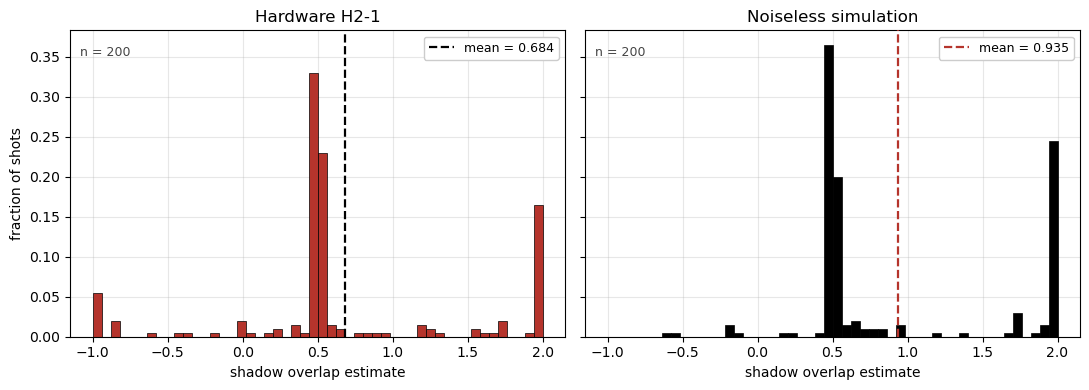

hardware    +0.6841 +/- 0.0550   (n=200, 75 of 75 bases)
simulation  +0.9354 +/- 0.0493   (n=200, full 600-shot plan)
implied fidelity F = 0.423 +/- 0.126


In [34]:
# ===================== HARDWARE: progress + comparison =====================
RED, BLACK, NBINS = "#b5342c", "#000000", 50
SIM_FILE = "multiregister_shadow_results_grouped.npy"

store, st = load_shadow_results(), basis_status()
fmt = lambda bs: ", ".join(f"(q{q},{PAULIS[p]})" for q, p in bs) or "none"
shots_of = lambda bs: sum(freq_sorted[b] for b in bs)

print(f"filed   ({len(st['filed']):>2d} bases, {shots_of(st['filed']):>3d} shots): {fmt(st['filed'])}")
print(f"pending ({len(st['pending']):>2d} bases, {shots_of(st['pending']):>3d} shots): {fmt(st['pending'])}")
print(f"to run  ({len(st['todo']):>2d} bases, {shots_of(st['todo']):>3d} shots): {fmt(st['todo'])}")
z_state = ("filed" if all((q, 2) in store for q, s in enumerate(SIZES_Z) if s)
           else "in flight" if "Z" in _index() else "not run")
print(f"\nZ batch ({sum(SIZES_Z)} shots, {sum(1 for s in SIZES_Z if s)} qubits): {z_state}")

if not st["filed"]:
    print("\nnothing filed yet -- nothing to plot")
else:
    hw  = np.concatenate([store[b]["estimates"] for b in st["filed"]])
    sim = np.asarray(np.load(SIM_FILE), dtype=float)

    edges = np.linspace(min(hw.min(), sim.min()), max(hw.max(), sim.max()), NBINS + 1)
    fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True, sharey=True)
    for ax, vals, fill, meanc, title in ((axes[0], hw,  RED,   BLACK, "Hardware H2-1"),
                                         (axes[1], sim, BLACK, RED,   "Noiseless simulation")):
        ax.hist(vals, bins=edges, weights=np.full(len(vals), 1 / len(vals)),
                color=fill, edgecolor="black", lw=0.5, zorder=2)
        ax.axvline(vals.mean(), color=meanc, ls="--", lw=1.6, zorder=3,
                   label=f"mean = {vals.mean():.3f}")
        ax.set_title(title, fontsize=12)
        ax.set_xlabel("shadow overlap estimate")
        ax.legend(fontsize=9, framealpha=1.0, loc="upper right")
        ax.grid(alpha=0.3, zorder=0)
        ax.text(0.02, 0.95, f"n = {len(vals)}", transform=ax.transAxes,
                va="top", fontsize=9, color="#444444")
    axes[0].set_ylabel("fraction of shots")
    plt.tight_layout(); plt.show()

    hw_se = hw.std(ddof=1) / np.sqrt(len(hw)) if len(hw) > 1 else float("nan")
    sim_se = sim.std(ddof=1) / np.sqrt(len(sim))
    print(f"hardware    {hw.mean():+.4f} +/- {hw_se:.4f}   "
          f"(n={len(hw)}, {len(st['filed'])} of {len(freq_sorted)} bases)")
    print(f"simulation  {sim.mean():+.4f} +/- {sim_se:.4f}   (n={len(sim)}, full 600-shot plan)")
    FLOOR = 0.5
    if sim.mean() > FLOOR + 1e-9:
        print(f"implied fidelity F = {(hw.mean() - FLOOR) / (sim.mean() - FLOOR):.3f} "
              f"+/- {hw_se / (sim.mean() - FLOOR):.3f}")


emulator   84 bases, 601 shots   (shadow_results_by_basis.pkl)
hardware   75 bases, 200 shots   (0 pending, 0 still to run)
noiseless             200 shots   (multiregister_shadow_results_grouped.npy)


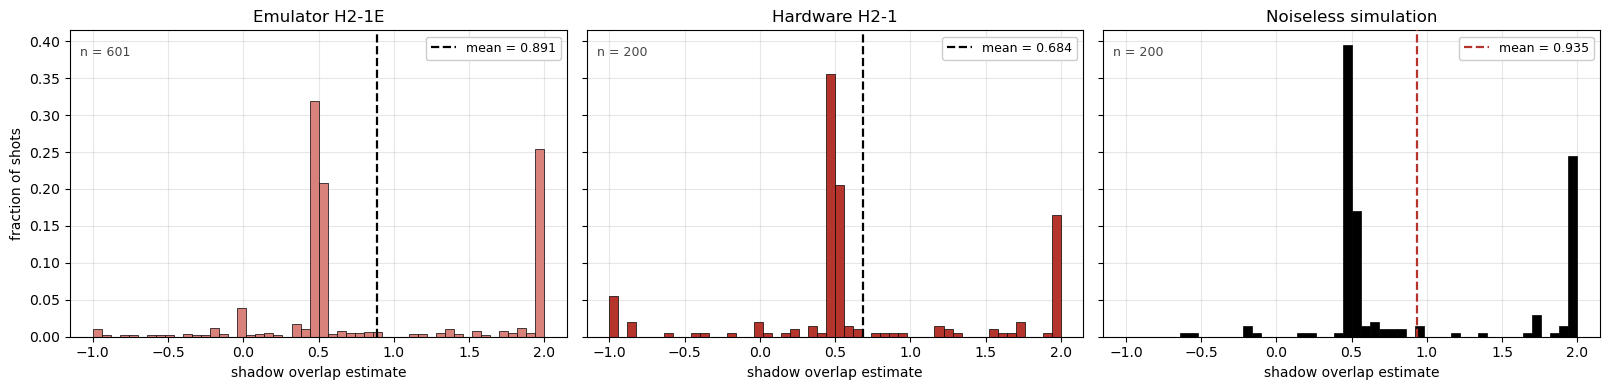

Emulator H2-1E         +0.8912 +/- 0.0305   (n=601)
Hardware H2-1          +0.6841 +/- 0.0550   (n=200)
Noiseless simulation   +0.9354 +/- 0.0493   (n=200)
implied fidelity (emulator) F = 0.898 +/- 0.070
implied fidelity (hardware) F = 0.423 +/- 0.126


In [35]:
# ============ EMULATOR vs HARDWARE vs NOISELESS: three-way comparison ============
RED, ROSE, BLACK, NBINS = "#b5342c", "#d9827b", "#000000", 50
EMU_STORE = "shadow_results_by_basis.pkl"                  # H2-1E emulator campaign
SIM_FILE  = "multiregister_shadow_results_grouped.npy"     # laptop noiseless sim
FLOOR     = 0.5

emu_store   = load_shadow_results(EMU_STORE)
hw_store, st = load_shadow_results(), basis_status()       # SHADOW_STORE = hardware
pool = lambda store, keys: (np.concatenate([np.asarray(store[b]["estimates"], float)
                                            for b in keys]) if keys else np.array([]))

emu = pool(emu_store, sorted(emu_store))
hw  = pool(hw_store, st["filed"])
sim = np.asarray(np.load(SIM_FILE), dtype=float)

print(f"emulator   {len(emu_store):>2d} bases, {len(emu):>3d} shots   ({EMU_STORE})")
print(f"hardware   {len(st['filed']):>2d} bases, {len(hw):>3d} shots   "
      f"({len(st['pending'])} pending, {len(st['todo'])} still to run)")
print(f"noiseless  {'':>2s}         {len(sim):>3d} shots   ({SIM_FILE})")

panels = [(t, v, f, m) for t, v, f, m in
          (("Emulator H2-1E",       emu, ROSE,  BLACK),
           ("Hardware H2-1",        hw,  RED,   BLACK),
           ("Noiseless simulation", sim, BLACK, RED)) if len(v)]

if not panels:
    print("\nnothing filed yet -- nothing to plot")
else:
    # shared bins and a fraction-of-shots y axis so the different n stay comparable
    edges = np.linspace(min(v.min() for _, v, _, _ in panels),
                        max(v.max() for _, v, _, _ in panels), NBINS + 1)
    fig, axes = plt.subplots(1, len(panels), figsize=(5.4 * len(panels), 4),
                             sharex=True, sharey=True)
    axes = np.atleast_1d(axes)
    for ax, (title, vals, fill, meanc) in zip(axes, panels):
        ax.hist(vals, bins=edges, weights=np.full(len(vals), 1 / len(vals)),
                color=fill, edgecolor="black", lw=0.5, zorder=2)
        ax.axvline(vals.mean(), color=meanc, ls="--", lw=1.6, zorder=3,
                   label=f"mean = {vals.mean():.3f}")
        ax.set_title(title, fontsize=12)
        ax.set_xlabel("shadow overlap estimate")
        ax.legend(fontsize=9, framealpha=1.0, loc="upper right")
        ax.grid(alpha=0.3, zorder=0)
        ax.text(0.02, 0.95, f"n = {len(vals)}", transform=ax.transAxes,
                va="top", fontsize=9, color="#444444")
    axes[0].set_ylabel("fraction of shots")
    plt.tight_layout(); plt.show()

    se = lambda v: v.std(ddof=1) / np.sqrt(len(v)) if len(v) > 1 else float("nan")
    for title, vals, _, _ in panels:
        print(f"{title:<22s} {vals.mean():+.4f} +/- {se(vals):.4f}   (n={len(vals)})")
    if sim.mean() > FLOOR + 1e-9:
        for title, vals in (("emulator", emu), ("hardware", hw)):
            if len(vals):
                print(f"implied fidelity ({title:<8s}) F = "
                      f"{(vals.mean() - FLOOR) / (sim.mean() - FLOOR):.3f} +/- "
                      f"{se(vals) / (sim.mean() - FLOOR):.3f}")


## Running

In [207]:
show_status()

   q   X Y Z        # filed   ~ in flight   . not run   - no shots planned
    0  # # #
    1  # # #
    2  # # #
    3  # # #
    4  # # #
    5  - # #
    6  # # #
    7  # # #
    8  # - #
    9  # # -
   10  # # #
   11  # - #
   12  - # #
   13  # # #
   14  - # #
   15  # # #
   16  # # #
   17  # - -
   18  # # #
   19  # # #
   20  # # #
   21  # # -
   22  # # #
   23  # # #
   24  # # #
   25  # ~ #
   26  ~ . #
   27  . . #
   filed: 70 bases, 185 shots
 pending:  2 bases,   3 shots
    todo:  3 bases,  12 shots

Z batch (58 shots, 25 qubits): filed
next X/Y basis: (26, 1)


In [213]:
BASIS =  (27,1)        # or (0, 1) explicitly, or "Z" for the whole Z batch
assert RUN == "hardware"
assert BASIS == "Z" or BASIS in basis_status()["todo"], f"{BASIS} already filed or in flight"
assert BASIS != "Z" or "Z" not in _index(), "Z batch already submitted"

is_z    = (BASIS == "Z")
shots   = sum(SIZES_Z) if is_z else freq_sorted[BASIS]
label   = "Zbatch" if is_z else str(BASIS)
stamp   = datetime.datetime.now().strftime("%Y_%m_%d-%H-%M-%S")
name    = f"HW_MRE_{label}-{stamp}"
backend = qnx.QuantinuumConfig(device_name=DEVICE)

tkc = build_tket_circuit_from_tk_no_measure(tk_circ_clean, False if is_z else BASIS)
up  = qnx.circuits.upload(circuit=tkc, name=name)
job = qnx.start_compile_job(programs=[up], backend_config=backend,
                            name=name, optimisation_level=2)
qnx.jobs.wait_for(job, timeout=1800, strategy=qnx.jobs.PollingStrategy())
ref = qnx.jobs.results(job)[0].get_output()

pool = load_shadow_results(POOL_PKL)
pool[BASIS] = {"ref": ref, "name": name, "shots": shots}
_atomic_write(pool, POOL_PKL)
print(f"compiled {BASIS} -> {name}  ({shots} shots planned)")


target: qiskit q27 = anc[0] (tket/clbit 27), measuring Y
compiled (27, 1) -> HW_MRE_(27, 1)-2026_09_01-20-07-19  (5 shots planned)


In [ ]:
ARM = False        # <<< True to submit, then set back to False
assert ARM, "not armed"
assert RUN == "hardware"
assert "q" not in DEVICE, f"device is still {DEVICE} -- strip the q in SETUP to arm"

entry = load_shadow_results(POOL_PKL)[BASIS]
name, shots = entry["name"], entry["shots"]
pkl = f"{name}_results.pkl"
assert not os.path.exists(pkl), f"{pkl} exists -- refusing to overwrite"
backend = qnx.QuantinuumConfig(device_name=DEVICE)

job_ref = qnx.start_execute_job(programs=[entry["ref"]], n_shots=[shots],
                                backend_config=backend, name=name)
with open(pkl, "wb") as f:
    pickle.dump([job_ref], f)
register_job(BASIS, name, shots,
             extra={"sizes": SIZES_Z, "shuffle_seed": Z_SHUFFLE_SEED} if BASIS == "Z" else None)
print(f"submitted {BASIS}: {shots} shots -> {name}")


submitted (27, 1): 5 shots -> HW_MRE_(27, 1)-2026_09_01-20-07-19


In [219]:
#Analysis cell
ONLY, REANALYSE = None, False
import ast
from qnexus.models.job_status import JobStatusEnum

store, idx = load_shadow_results(), _index()

def _ready(name):
    pkl = f"{name}_results.pkl"
    if not os.path.exists(pkl):
        print(f"  {pkl} missing -- skipped"); return None
    with open(pkl, "rb") as f: refs = pickle.load(f)
    try: st = qnx.jobs.status(refs[0]).status
    except Exception as e:
        print(f"  {name}: status failed ({type(e).__name__}: {e})"); return None
    if st != JobStatusEnum.COMPLETED:
        print(f"  {name}: {st.value} -- not ready"); return None
    return qnx.jobs.results(refs[0])[0].download_result().get_counts()

filed = 0
for k, rec in sorted(idx.items()):
    name = rec["name"]
    if k == "Z":
        if not REANALYSE and all((q, 2) in store for q, s in enumerate(rec["sizes"]) if s):
            continue
        counts = _ready(name)
        if counts is None: continue
        bits = {nexus_to_statevector_order(''.join(map(str, bt)), PERM): c
                for bt, c in counts.items()}
        for i, (b, est) in enumerate(sorted(shadows_allcomp_sized(
                bits, target_state, rec["sizes"], seed=rec["shuffle_seed"]).items())):
            save_shadow_result(b, est, job_name=f"{name} [Z batch]",
                               raw_counts=counts if i == 0 else None, overwrite=REANALYSE)
            filed += 1
        continue

    basis = tuple(ast.literal_eval(k))
    if (ONLY is not None and basis != tuple(ONLY)) or (basis in store and not REANALYSE):
        continue
    assert f"HW_MRE_{basis}-" in name, f"index mismatch: {basis} vs {name}"
    counts = _ready(name)
    if counts is None: continue
    planned = freq_sorted.get(basis)
    if planned is not None and sum(counts.values()) != planned:
        print(f"  {basis}: WARNING got {sum(counts.values())} shots, plan says {planned}")
    bits = {nexus_to_statevector_order(''.join(map(str, bt)), PERM): c
            for bt, c in counts.items()}
    save_shadow_result(basis, get_shadows_from_basis_single(bits, target_state, basis,
                                                            plot=(ONLY is not None)),
                       job_name=name, raw_counts=counts, overwrite=REANALYSE)
    filed += 1

print(f"\nfiled {filed}")
show_status()


Unknown OpType in BackendInfo: `RZZ`, will omit from BackendInfo. Consider updating your pytket version.
Unknown OpType in BackendInfo: `Rxxyyzz`, will omit from BackendInfo. Consider updating your pytket version.
Unknown OpType in BackendInfo: `U1q`, will omit from BackendInfo. Consider updating your pytket version.
Unknown OpType in BackendInfo: `ZZ`, will omit from BackendInfo. Consider updating your pytket version.


saved (q26,Y): 4 shots, mean +0.3750  ->  shadow_results_hardware.pkl


Unknown OpType in BackendInfo: `RZZ`, will omit from BackendInfo. Consider updating your pytket version.
Unknown OpType in BackendInfo: `Rxxyyzz`, will omit from BackendInfo. Consider updating your pytket version.
Unknown OpType in BackendInfo: `U1q`, will omit from BackendInfo. Consider updating your pytket version.
Unknown OpType in BackendInfo: `ZZ`, will omit from BackendInfo. Consider updating your pytket version.


saved (q27,X): 3 shots, mean +0.5000  ->  shadow_results_hardware.pkl


Unknown OpType in BackendInfo: `RZZ`, will omit from BackendInfo. Consider updating your pytket version.
Unknown OpType in BackendInfo: `Rxxyyzz`, will omit from BackendInfo. Consider updating your pytket version.
Unknown OpType in BackendInfo: `U1q`, will omit from BackendInfo. Consider updating your pytket version.
Unknown OpType in BackendInfo: `ZZ`, will omit from BackendInfo. Consider updating your pytket version.


saved (q27,Y): 5 shots, mean +0.5000  ->  shadow_results_hardware.pkl

filed 3
   q   X Y Z        # filed   ~ in flight   . not run   - no shots planned
    0  # # #
    1  # # #
    2  # # #
    3  # # #
    4  # # #
    5  - # #
    6  # # #
    7  # # #
    8  # - #
    9  # # -
   10  # # #
   11  # - #
   12  - # #
   13  # # #
   14  - # #
   15  # # #
   16  # # #
   17  # - -
   18  # # #
   19  # # #
   20  # # #
   21  # # -
   22  # # #
   23  # # #
   24  # # #
   25  # # #
   26  # # #
   27  # # #
   filed: 75 bases, 200 shots
 pending:  0 bases,   0 shots
    todo:  0 bases,   0 shots

Z batch (58 shots, 25 qubits): filed
next X/Y basis: None


# Shadow overlap Classical Simulation

## Simulation of hardware workflow

### Specific (n,p) basis LAPTOP SIMULATION

Number of samples: 100
Mean: 0.8781173223347969
Standard error: 0.06572877604466673
90% confidence interval: [0.7700031066626458, 0.986231538006948]
BASIS MEASURED IN IS [7, 0]


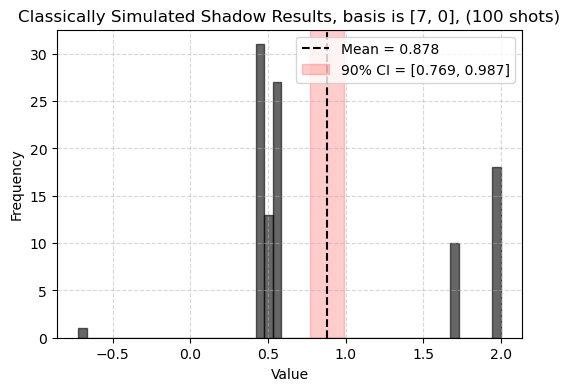

[np.float64(0.5446178511053724), np.float64(0.45538214889462675), np.float64(0.48443128315101025), np.float64(0.5446178511053728), np.float64(0.45538214889462664), np.float64(0.45538214889462675), np.float64(1.9999999999999991), np.float64(0.4553821488946265), np.float64(0.45538214889462647), np.float64(0.5446178511053725), np.float64(0.5446178511053726), np.float64(1.9999999999999991), np.float64(1.9999999999999993), np.float64(0.4553821488946266), np.float64(0.5155687168489892), np.float64(0.5446178511053724), np.float64(1.9999999999999991), np.float64(1.7228635949722457), np.float64(0.5446178511053725), np.float64(0.5446178511053725), np.float64(1.999999999999999), np.float64(0.4553821488946266), np.float64(0.4553821488946265), np.float64(0.515568716848989), np.float64(0.5446178511053728), np.float64(0.4553821488946266), np.float64(0.5155687168489888), np.float64(0.5446178511053725), np.float64(1.9999999999999991), np.float64(1.9999999999999993), np.float64(0.5446178511053724), np.f

In [16]:
#Optimised version of simulation, single basis choice generator (fixed runtime of approx 10sec due to opimised process where time comes from initial state vector calculation then once that is done trials are done super fast)
num_qubits=28
circuit=qc

target = mre.simulate_statevector(qc)

#Manuly set the basis chosen if "batching" the random basis measurements.
basis_select=[7,0]

#Shots is number of times we run the circuit and measure the output
shots=100

multiregister_estimated_fideleities= run_multiple_shadow_overlaps_cached(
    target, target, num_qubits, shots, verbose=False, basis_select=basis_select)
confidence_interval_90=get_confidence_interval(multiregister_estimated_fideleities,confidence=0.90,verbose=True)
print("BASIS MEASURED IN IS", basis_select)
# {basis_select} basis
plot_single_shot_CI(multiregister_estimated_fideleities,tau=18,bins=50,title=f"Classically Simulated Shadow Results, basis is {basis_select}, ({shots} shots)", show_mean=True, ci=0.90,show_fidelity=False)
np.save("multiregister_shadow_results_noiseless.npy", multiregister_estimated_fideleities)
print(multiregister_estimated_fideleities)

### (_,2) 194 shots LAPTOP SIMULATION

194 shots across 28 qubits (Z basis only)
qubit=0  (10 shots)
qubit=1  (4 shots)
qubit=2  (10 shots)
qubit=3  (5 shots)
qubit=4  (8 shots)
qubit=5  (8 shots)
qubit=6  (7 shots)
qubit=7  (6 shots)
qubit=8  (7 shots)
qubit=9  (1 shots)
qubit=10  (6 shots)
qubit=11  (5 shots)
qubit=12  (14 shots)
qubit=13  (5 shots)
qubit=14  (10 shots)
qubit=15  (6 shots)
qubit=16  (3 shots)
qubit=17  (6 shots)
qubit=18  (6 shots)
qubit=19  (4 shots)
qubit=20  (12 shots)
qubit=21  (5 shots)
qubit=22  (10 shots)
qubit=23  (8 shots)
qubit=24  (3 shots)
qubit=25  (6 shots)
qubit=26  (9 shots)
qubit=27  (10 shots)
Number of samples: 194
Mean: 1.6434512247290791
Standard error: 0.04721245127134356
90% confidence interval: [1.56579365301814, 1.7211087964400182]


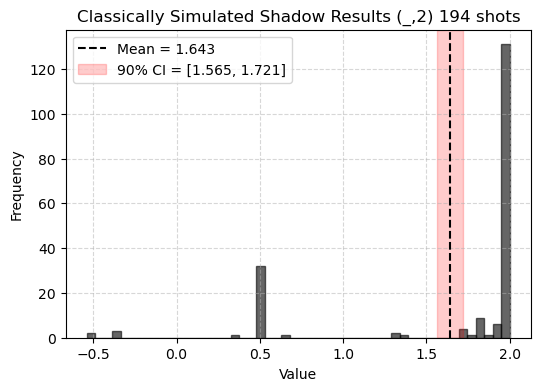

In [12]:
#This is for the (_,2) run on the emulator.
sizes_z = [10,4,10,5,8,8,7,6,7,1,6,5,14,5,10,6,3,6,6,4,12,5,10,8,3,6,9,10]

#Run all together
target = mre.simulate_statevector(qc)

#no basis select -- shot allocation comes directly from freq_sorted (your real hardware plan)

multiregister_estimated_fideleities = run_shadow_grouped_allcomp(target, target, num_qubits=28, freq_sorted=sizes_z, verbose=True)
confidence_interval_90 = get_confidence_interval(multiregister_estimated_fideleities, confidence=0.90, verbose=True)
plot_single_shot_CI(multiregister_estimated_fideleities, tau=18, bins=50, title="Classically Simulated Shadow Results (_,2) 194 shots", show_mean=True, ci=0.90, show_fidelity=False)
np.save("multiregister_shadow_results_noiseless.npy", multiregister_estimated_fideleities)



## ALL RESULTS TOGETHER LAPTOP SIMULAITON

200 shots landed on 75 distinct (qubit, Pauli) combinations out of 84 possible
[1/75] qubit=24 pauli=X  (3 shots)
[2/75] qubit=8 pauli=Y  (2 shots)
[3/75] qubit=6 pauli=X  (4 shots)
[4/75] qubit=11 pauli=X  (2 shots)
[5/75] qubit=16 pauli=X  (10 shots)
[6/75] qubit=11 pauli=Z  (5 shots)
[7/75] qubit=23 pauli=Y  (3 shots)
[8/75] qubit=3 pauli=Y  (4 shots)
[9/75] qubit=1 pauli=Z  (4 shots)
[10/75] qubit=23 pauli=Z  (4 shots)
[11/75] qubit=0 pauli=Y  (4 shots)
[12/75] qubit=7 pauli=Y  (5 shots)
[13/75] qubit=15 pauli=Y  (4 shots)
[14/75] qubit=10 pauli=Z  (3 shots)
[15/75] qubit=27 pauli=Z  (3 shots)
[16/75] qubit=21 pauli=X  (1 shots)
[17/75] qubit=13 pauli=Y  (3 shots)
[18/75] qubit=27 pauli=Y  (4 shots)
[19/75] qubit=15 pauli=X  (6 shots)
[20/75] qubit=20 pauli=X  (2 shots)
[21/75] qubit=15 pauli=Z  (2 shots)
[22/75] qubit=16 pauli=Z  (5 shots)
[23/75] qubit=25 pauli=Z  (5 shots)
[24/75] qubit=1 pauli=X  (3 shots)
[25/75] qubit=25 pauli=X  (2 shots)
[26/75] qubit=19 pauli=Z  (1 shots)


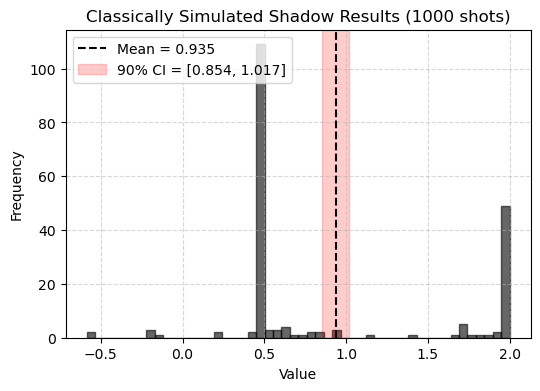

In [83]:
#Run all together: note that this will use a fair bit of memory as each shot takes a while.
target = mre.simulate_statevector(qc)

shots=200

#no basis select as the grouping is built purely for the full sampling of the circuit

multiregister_estimated_fideleities = run_shadow_grouped(target, target, num_qubits=28, total_shots=shots, verbose=False)
confidence_interval_90 = get_confidence_interval(multiregister_estimated_fideleities, confidence=0.90, verbose=True)
plot_single_shot_CI(multiregister_estimated_fideleities, tau=18, bins=50, title="Classically Simulated Shadow Results (1000 shots)", show_mean=True, ci=0.90, show_fidelity=False)
np.save("multiregister_shadow_results_noiseless.npy", multiregister_estimated_fideleities)


## Testing wrong states for shadow overlap

In [22]:
import numpy as np
import os
filename = "multiregister_shadows_vs_fidelity.npy"

if os.path.exists(filename):
    shadows_vs_fidelity = list(np.load(filename, allow_pickle=True))
    print(f"Loaded {len(shadows_vs_fidelity)} existing points.")
else:
    shadows_vs_fidelity = []
    print("No file -- starting fresh.")

def generate_state_with_fidelity_lowmem(target_state, fidelity):
    """Same math as generate_state_with_fidelity, but memory-frugal at 28-qubit scale
    (4.3GB per complex128 array). Uses in-place ops throughout instead of building
    several full-size temporaries -- the original peaked at ~5-6 simultaneous 4.3GB
    arrays (~20-26GB), which is what triggered the MemoryError. Assumes target_state
    is already a normalized 1D array (true for `target` from mre.simulate_statevector),
    so it skips the original's redundant flatten()+renormalize copy."""
    dim = target_state.shape[0]

    noise = np.empty(dim, dtype=np.complex128)
    noise.real = np.random.normal(size=dim)
    noise.imag = np.random.normal(size=dim)
    noise /= np.linalg.norm(noise)                 # in-place, no new array

    noise *= np.sqrt(1 - fidelity)                  # in-place scale
    noise += np.sqrt(fidelity) * target_state        # one 4.3GB temp for the RHS, added in-place

    noise /= np.linalg.norm(noise)                   # in-place final normalize
    return noise


num_qubits = 28
target = mre.simulate_statevector(qc)   # true state, computed once for the whole sweep

rng = np.random.default_rng()
num_trials = 40          
shots_per_trial = 600

for trial in range(num_trials):
    fidelity = rng.random()
    print(f"trial {trial}: generating wrong state at approx fidelity {fidelity:.4f}")

    psi0 = generate_state_with_fidelity_lowmem(target, fidelity)   # already normalized internally
    actual_fidelity = np.abs(np.vdot(psi0, target)) ** 2

    estimated_shadow_sample = run_shadow_grouped(
        target, psi0, num_qubits, shots_per_trial, verbose=False,
        save_path=f"shadow_vs_fidelity_trial{trial}_checkpoint.npy"
    )
    mean_estimate = np.mean(estimated_shadow_sample)
    print(f"  shadow estimate mean = {mean_estimate:.4f}   actual fidelity = {actual_fidelity:.4f}")
    shadows_vs_fidelity.append((mean_estimate, actual_fidelity))

    np.save(filename, shadows_vs_fidelity)   # save after every trial, not just at the end


Loaded 64 existing points.
trial 0: generating wrong state at approx fidelity 0.8825
600 shots landed on 84 distinct (qubit, Pauli) combinations out of 84 possible
[1/84] qubit=3 pauli=X  (9 shots)
[2/84] qubit=19 pauli=Z  (11 shots)
[3/84] qubit=26 pauli=Y  (12 shots)
[4/84] qubit=6 pauli=Y  (10 shots)
[5/84] qubit=27 pauli=X  (10 shots)
[6/84] qubit=2 pauli=Z  (9 shots)
[7/84] qubit=7 pauli=X  (8 shots)
[8/84] qubit=12 pauli=Z  (6 shots)
[9/84] qubit=5 pauli=Z  (12 shots)
[10/84] qubit=22 pauli=X  (4 shots)
[11/84] qubit=7 pauli=Y  (13 shots)
[12/84] qubit=23 pauli=X  (11 shots)
[13/84] qubit=27 pauli=Y  (9 shots)
[14/84] qubit=7 pauli=Z  (7 shots)
[15/84] qubit=14 pauli=X  (6 shots)
[16/84] qubit=11 pauli=Y  (10 shots)
[17/84] qubit=24 pauli=X  (11 shots)
[18/84] qubit=21 pauli=Z  (10 shots)
[19/84] qubit=17 pauli=X  (8 shots)
[20/84] qubit=17 pauli=Z  (8 shots)
[21/84] qubit=25 pauli=Y  (3 shots)
[22/84] qubit=4 pauli=Z  (9 shots)
[23/84] qubit=10 pauli=Z  (11 shots)
[24/84] qubit=

KeyboardInterrupt: 

Loaded 82 existing points.


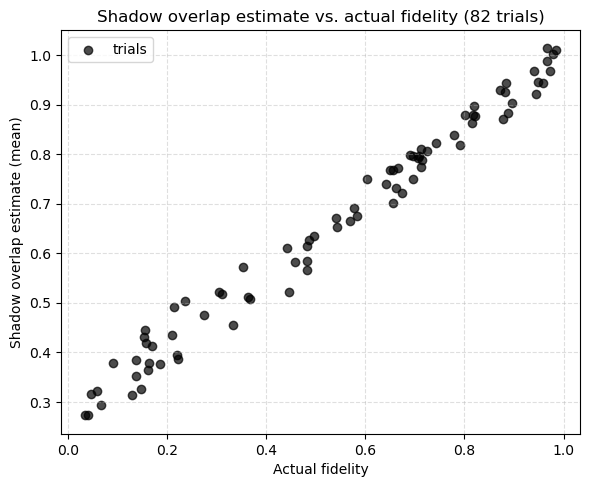

In [23]:
import matplotlib.pyplot as plt
import numpy as np
filename = "multiregister_shadows_vs_fidelity.npy"

if os.path.exists(filename):
    shadows_vs_fidelity = list(np.load(filename, allow_pickle=True))
    print(f"Loaded {len(shadows_vs_fidelity)} existing points.")
else:
    print("No file.")

shadows_vs_fidelity = np.array(shadows_vs_fidelity)   # columns: (shadow_estimate_mean, actual_fidelity)
est, true_fid = shadows_vs_fidelity[:, 0], shadows_vs_fidelity[:, 1]

plt.figure(figsize=(6, 6))
plt.scatter(true_fid, est, color='black', alpha=0.7, label="trials")

plt.xlabel("Actual fidelity")
plt.ylabel("Shadow overlap estimate (mean)")
plt.title(f"Shadow overlap estimate vs. actual fidelity ({len(shadows_vs_fidelity)} trials)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.4)
plt.gca().set_aspect('equal')
plt.tight_layout()
plt.show()


# Alternative Analysis

here what we will do is group by index result there should be 4 of them (i think equally weighted). what we will do is on each of these index branches we will look at how well each of these branches have been prepared by using the shadow overlap. i think this is possible by gettin the big data file of results i have (keeping in mind qubnit order), discarding the measurement on the preparation register and just doing 4 shadow overlap histograms on each of the data points. can you code this up and make a cell that does this, final output should be 12 plots, a noise free simulation on laptop of this plus the emulator and hardware. only use the results i have as there shuld be some basis stuff where we do different basis in the storage stage which will have to be used for shadow results ect. as in do it as if its random and just draw from the results i allready have. here is paper too as reference for overall method

In [36]:
# ============ SETUP for the per-branch storage-register analysis ============
# Everything the plotting cell needs and nothing else. No qnexus, no mre_prep,
# no 2^28 statevector: the ideal state is just the four 32-amplitude chunks, and
# the shots come from the two .pkl stores already on disk.
import os, pickle
import numpy as np
import matplotlib.pyplot as plt
from qiskit import qpy
from pytket.extensions.qiskit import qiskit_to_tk

PAULIS = ['X', 'Y', 'Z']
qc     = qpy.load(open('mre_qc.qpy', 'rb'))[0]
chunks = list(np.load('mre_target_data.npz')['chunks'])

def nexus_bit_to_qiskit_index(qc):
    """PERM[i] = Qiskit global qubit index measured into classical bit c[i].
       pytket sorts qubits alphabetically (A0..A3, I, S, anc); Qiskit indexes
       them as declared (S, I, A0..A3, anc). Not a reversal."""
    names = [f"{q._register.name}[{q._index}]" for q in qc.qubits]
    tk = qiskit_to_tk(qc); tk.measure_all()
    wiring = {str(c.args[1]): str(c.args[0]) for c in tk if c.op.type.name == "Measure"}
    return [names.index(wiring[f"c[{i}]"]) for i in range(len(names))]

PERM = nexus_bit_to_qiskit_index(qc)
assert PERM == [7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20,
                21, 22, 23, 24, 25, 26, 5, 6, 0, 1, 2, 3, 4, 27], \
    f"PERM changed -- the stored raw counts were filed under the old wiring: {PERM}"

def nexus_to_statevector_order(b, perm=PERM):
    """get_counts() bit order -> np.binary_repr order, so int(b, 2) indexes a statevector."""
    n = len(perm); s = [None] * n
    for i, g in enumerate(perm):
        s[n - 1 - g] = b[i]
    return "".join(s)

def load_shadow_results(path):
    if not os.path.exists(path):
        return {}
    with open(path, "rb") as f:
        return pickle.load(f)

def rotated_outcome_to_zket(outcome, pauli):
    if pauli == 'Z':
        return np.array([1, 0], dtype=complex) if outcome == 0 else np.array([0, 1], dtype=complex)
    if pauli == 'X':
        return np.array([1, 1], dtype=complex)/np.sqrt(2) if outcome == 0 else np.array([1, -1], dtype=complex)/np.sqrt(2)
    if pauli == 'Y':
        return np.array([1, 1j], dtype=complex)/np.sqrt(2) if outcome == 0 else np.array([1, -1j], dtype=complex)/np.sqrt(2)
    raise ValueError(f"Pauli must be X, Y or Z, got {pauli!r}")

def compute_local_overlap(cond, outcome, P, verbose=False):
    """omega = <phi| (3|s><s| - I) |phi>  for a single-qubit conditional state."""
    s = rotated_outcome_to_zket(outcome, P)
    O3 = 3 * np.outer(s, s.conj()) - np.eye(2, dtype=complex)
    return np.vdot(np.asarray(cond, dtype=complex), O3 @ np.asarray(cond, dtype=complex)).real

print(f"qc: {qc.num_qubits} qubits   chunks: {len(chunks)} x {len(chunks[0])}")
for _p in ("shadow_results_by_basis.pkl", "shadow_results_hardware.pkl"):
    _st = load_shadow_results(_p)
    print(f"  {_p}: {len(_st)} bases, {sum(v['n_shots'] for v in _st.values())} shots")


qc: 28 qubits   chunks: 4 x 32
  shadow_results_by_basis.pkl: 84 bases, 601 shots
  shadow_results_hardware.pkl: 75 bases, 200 shots


  note: 2 of 90 shots landed outside the ideal support and were scored omega = 0


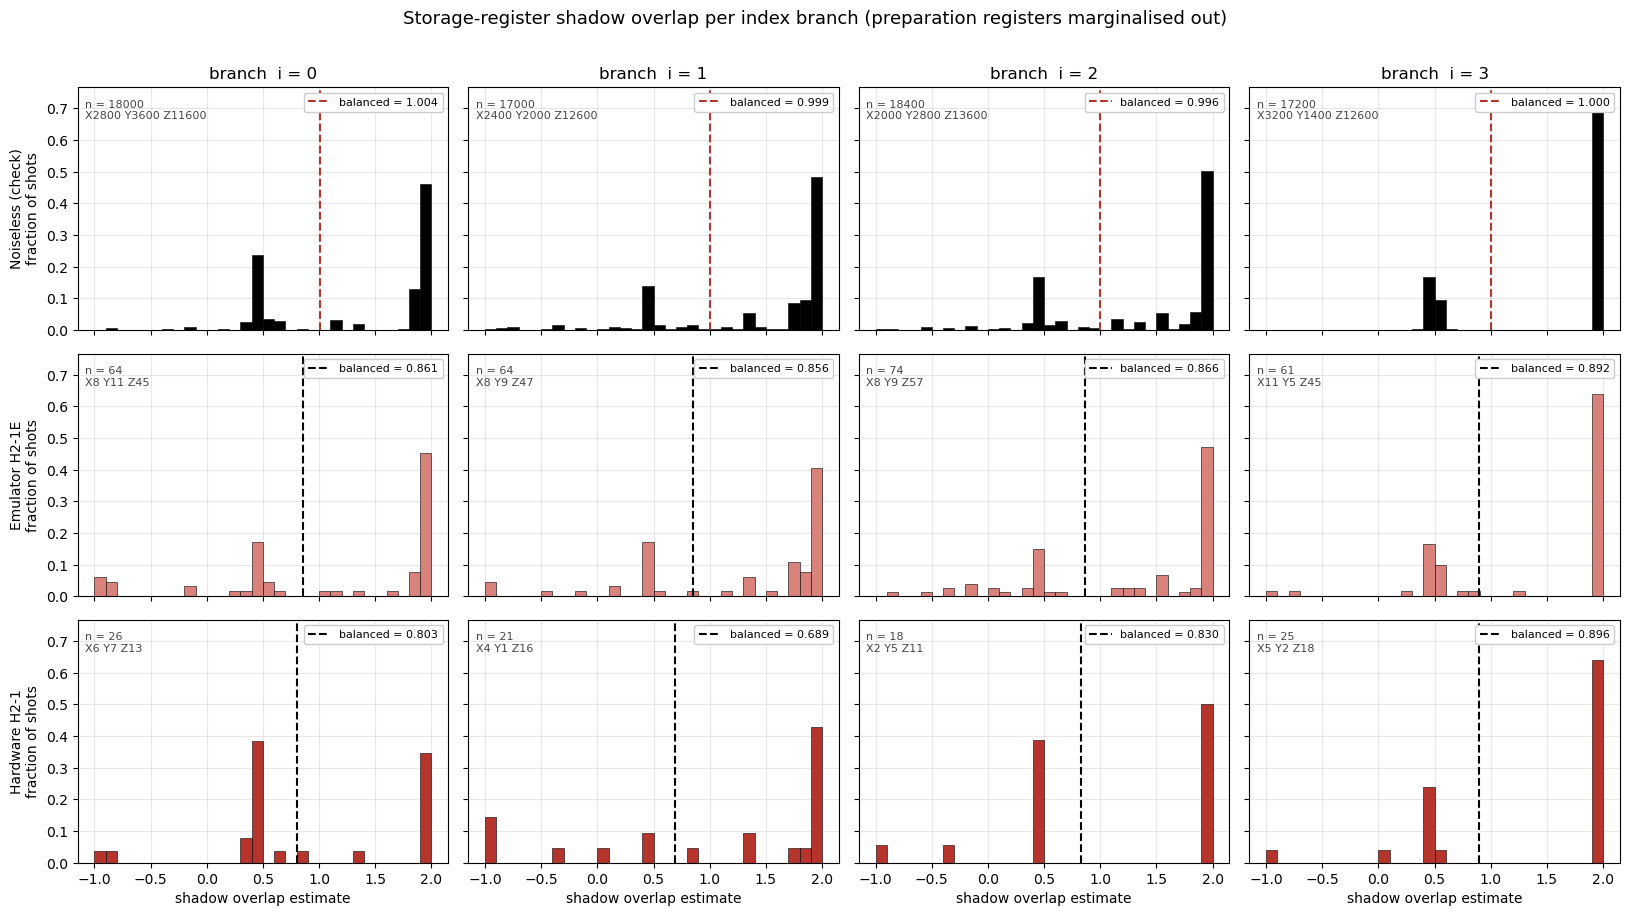

                           branch 0            branch 1            branch 2            branch 3           pooled
Noiseless (check)     +1.004+/-0.003(18000)  +0.999+/-0.004(17000)  +0.996+/-0.005(18400)  +1.000+/-0.000(17200)   +0.9933+/-0.0016
Emulator H2-1E        +0.861+/-0.100( 64)  +0.856+/-0.062( 64)  +0.866+/-0.112( 74)  +0.892+/-0.049( 61)   +0.8632+/-0.0396
Hardware H2-1         +0.803+/-0.105( 26)  +0.689+/-0.130( 21)  +0.830+/-0.109( 18)  +0.896+/-0.065( 25)   +0.8099+/-0.0500

means are BALANCED (average of the X, Y and Z means) -- a plain mean would be pulled by the Z surplus; a perfect state gives 1.000 in every cell,
so 1 - value is the shortfall.  A single-shot stratum still counts, with its variance borrowed from the same Pauli pooled over the other branches.
Emulator H2-1E         X/Y shots per branch: [19, 17, 17, 16]   <- these, not the Z surplus, set the error bars
Hardware H2-1          X/Y shots per branch: [13, 5, 7, 7]   <- these, not the Z surplus, set the err

In [37]:
# ============ STORAGE-REGISTER SHADOW OVERLAP, PER INDEX BRANCH ============
# Conditioning the record on the index register makes the preparation-register
# outcome irrelevant: projecting Eq.(5) onto |i>_I leaves S in |psi_i> up to the
# scalar w_i, which normalises away. So every estimate here runs off the
# 32-amplitude chunks[i], never the 2^28 statevector -- no big sim, no cache.
#
# An all-Z shot measures EVERY S qubit in Z, so the whole Z batch is usable for
# any target qubit, while X/Y shots exist only where the rotation physically
# landed on an S qubit. Z is hugely oversupplied, so the per-branch mean averages
# the three per-Pauli means ("balanced mean"), restoring the uniform X/Y/Z design
# the estimator needs while still using every Z shot.
import random

RED, ROSE, BLACK, NBINS = "#b5342c", "#d9827b", "#000000", 30
S_QUBITS, I_QUBITS, N_S = tuple(range(5)), (5, 6), 5
M_BRANCH  = 2 ** len(I_QUBITS)
EMU_STORE = "shadow_results_by_basis.pkl"
HW_STORE  = "shadow_results_hardware.pkl"
Z_ASSIGN_SEED, SIM_SEED, SIM_REPS = 11, 2026, 200

CHUNKS = [np.asarray(c, dtype=complex) / np.linalg.norm(c) for c in chunks]
assert len(CHUNKS) == M_BRANCH and len(CHUNKS[0]) == 2 ** N_S

def sv_bits(key):
    if isinstance(key, (tuple, list)):
        return nexus_to_statevector_order("".join(map(str, key)), PERM)
    return str(key)

def s_bits(b):   return b[-N_S:]                 # qubits 4..0, i.e. binary_repr order
def branch_of(b):
    n = len(b)
    return sum(int(b[n - 1 - q]) << k for k, q in enumerate(I_QUBITS))

NO_SUPPORT_TOL = 1e-12       # in the gap between 3.0e-16 dust and 8.9e-9 real data
_no_support = {"n": 0}

def omega(chunk, sb, q, p, tol=NO_SUPPORT_TOL):
    """One shadow-overlap estimate against a 32-amplitude chunk.
    The no-support guard MUST be a tolerance, not `== 0`: the ideally-vanishing
    amplitudes are stored as ~1e-16, never exactly zero, so an exact test never
    fires and the shot is scored against a unit vector made of rounding error.
    Below tol we return 0, which is the paper's w = 0 convention."""
    pos = N_S - 1 - q
    z, o = sb[:pos] + "0" + sb[pos+1:], sb[:pos] + "1" + sb[pos+1:]
    v = np.array([chunk[int(z, 2)], chunk[int(o, 2)]], dtype=complex)
    nv = np.linalg.norm(v)
    if nv < tol:
        _no_support["n"] += 1
        return 0.0
    return compute_local_overlap(v / nv, int(sb[pos]), PAULIS[p])

def storage_shots(path, seed=Z_ASSIGN_SEED):
    """-> [(s_bits, branch, target_qubit, pauli)] for every usable shot.
    X/Y: only where the rotation landed on an S qubit. Z: the whole batch,
    each shot assigned one S qubit (never reused across qubits)."""
    store, recs = load_shadow_results(path), []
    for (q, p), v in sorted(store.items()):
        if q not in S_QUBITS or p == 2 or not v["raw_counts"]:
            continue
        for k, c in v["raw_counts"].items():
            b = sv_bits(k)
            recs += [(s_bits(b), branch_of(b), q, p)] * c
    zblob = next((v["raw_counts"] for (q, p), v in sorted(store.items())
                  if p == 2 and v["raw_counts"]), None)
    if zblob:
        zs = [sv_bits(k) for k, c in zblob.items() for _ in range(c)]
        rng = random.Random(seed); rng.shuffle(zs)
        for j, b in enumerate(zs):
            recs.append((s_bits(b), branch_of(b), S_QUBITS[j % N_S], 2))
    return recs

_H, _Sdg = np.array([[1, 1], [1, -1]]) / np.sqrt(2), np.diag([1, -1j]).astype(complex)
def _rot_probs(vec, q, p):
    if p == 2:
        return np.abs(vec) ** 2
    U = _H if p == 0 else _H @ _Sdg
    v3 = vec.reshape(-1, 2, 2 ** q)
    b0, b1 = v3[:, 0, :], v3[:, 1, :]
    out = np.empty_like(v3)
    out[:, 0, :], out[:, 1, :] = U[0,0]*b0 + U[0,1]*b1, U[1,0]*b0 + U[1,1]*b1
    return np.abs(out.reshape(-1)) ** 2

def sim_like(recs, reps=SIM_REPS, seed=SIM_SEED):
    """Noiseless reference matched cell-for-cell to `recs`: same (branch, qubit,
    Pauli) design, only the outcome bits resampled from the ideal chunk."""
    rng, cdfs, out = np.random.default_rng(seed), {}, []
    for _, i, q, p in recs:
        if (i, q, p) not in cdfs:
            cdfs[(i, q, p)] = np.cumsum(_rot_probs(CHUNKS[i], q, p))
        cdf = cdfs[(i, q, p)]
        idx = np.minimum(np.searchsorted(cdf, rng.random(reps)), len(cdf) - 1)
        out += [(np.binary_repr(int(j), width=N_S), i, q, p) for j in idx]
    return out

def evaluate(recs):
    _no_support["n"] = 0
    est = np.array([omega(CHUNKS[i], sb, q, p) for sb, i, q, p in recs])
    if _no_support["n"]:
        print(f"  note: {_no_support['n']} of {len(recs)} shots landed outside the ideal "
              f"support and were scored omega = 0")
    return est, np.array([i for _, i, _, _ in recs]), np.array([p for *_, p in recs])

def pauli_var(est, pau):
    """Within-Pauli variance pooled over all branches of one dataset."""
    return {p: float(est[pau == p].var(ddof=1)) for p in range(3) if (pau == p).sum() > 1}

def balanced(est, pau, var_ref=None):
    """Uniform-design (X,Y,Z) mean and its SE -- unbiased at 1 for a perfect
    state no matter how lopsided the realised Pauli counts are. A stratum holding
    a single shot still contributes an unbiased mean; only its variance is
    unknowable from itself, so that term is borrowed from `var_ref`."""
    ms, vs = [], []
    for p in range(3):
        v = est[pau == p]
        if len(v) == 0:
            return float("nan"), float("nan")
        ms.append(v.mean())
        s2 = v.var(ddof=1) if len(v) > 1 else (var_ref or {}).get(p, np.nan)
        vs.append(s2 / len(v))
    return float(np.mean(ms)), float(np.sqrt(np.nansum(vs)) / 3)

# A perfect state gives a balanced mean of 1.000 in EVERY cell, so the noiseless
# row is a check that this pipeline reproduces what theory demands, not a calibration.
rows = [("Emulator H2-1E", ROSE, BLACK, storage_shots(EMU_STORE)),
        ("Hardware H2-1",  RED,  BLACK, storage_shots(HW_STORE))]
rows.insert(0, ("Noiseless (check)", BLACK, RED, sim_like(rows[0][3] + rows[1][3])))

data = []
for label, fill, meanc, recs in rows:
    est, br, pau = evaluate(recs)
    data.append((label, fill, meanc, est, br, pau, pauli_var(est, pau)))

edges = np.linspace(min(d[3].min() for d in data), max(d[3].max() for d in data), NBINS + 1)
fig, axes = plt.subplots(len(data), M_BRANCH, figsize=(4.1 * M_BRANCH, 3.1 * len(data)),
                         sharex=True, sharey=True)
for r, (label, fill, meanc, est, br, pau, vref) in enumerate(data):
    for i in range(M_BRANCH):
        ax, v, p = axes[r, i], est[br == i], pau[br == i]
        if len(v):
            ax.hist(v, bins=edges, weights=np.full(len(v), 1 / len(v)),
                    color=fill, edgecolor="black", lw=0.4, zorder=2)
            m, s = balanced(v, p, vref)
            ax.axvline(m, color=meanc, ls="--", lw=1.5, zorder=3,
                       label=f"balanced = {m:.3f}")
            ax.legend(fontsize=8, framealpha=1.0, loc="upper right")
            nx, ny, nz = [(p == k).sum() for k in (0, 1, 2)]
            ax.text(0.02, 0.95, f"n = {len(v)}\nX{nx} Y{ny} Z{nz}", transform=ax.transAxes,
                    va="top", fontsize=8, color="#444444")
        ax.grid(alpha=0.3, zorder=0)
        if r == 0: ax.set_title(f"branch  i = {i}", fontsize=12)
        if r == len(data) - 1: ax.set_xlabel("shadow overlap estimate")
    axes[r, 0].set_ylabel(f"{label}\nfraction of shots", fontsize=10)
fig.suptitle("Storage-register shadow overlap per index branch "
             "(preparation registers marginalised out)", fontsize=13)
plt.tight_layout(rect=(0, 0, 1, 0.97)); plt.show()

print(f"{'':<22s}" + "  ".join(f"branch {i}".center(18) for i in range(M_BRANCH)) + "      pooled")
for label, _, _, est, br, pau, vref in data:
    cells = []
    for i in range(M_BRANCH):
        m, s = balanced(est[br == i], pau[br == i], vref)
        cells.append((f"{m:+.3f}+/-{s:.3f}({(br==i).sum():>3d})" if m == m else "-").center(18))
    m, s = balanced(est, pau, vref)
    print(f"{label:<22s}" + "  ".join(cells) + f"   {m:+.4f}+/-{s:.4f}")
print("\nmeans are BALANCED (average of the X, Y and Z means) -- a plain mean would be "
      "pulled by the Z surplus; a perfect state gives 1.000 in every cell,")
print("so 1 - value is the shortfall.  A single-shot stratum still counts, with its "
      "variance borrowed from the same Pauli pooled over the other branches.")
for label, _, _, est, br, pau, _ in data[1:]:
    print(f"{label:<22s} X/Y shots per branch: "
          f"{[int(((br == i) & (pau < 2)).sum()) for i in range(M_BRANCH)]}"
          f"   <- these, not the Z surplus, set the error bars")


## Shadow Overlap simulation for Per Row analsysis

row 0, requested fidelity 0.85 -> actual 0.8500
exact shadow overlap for this one state (shots -> inf): 0.9267

  shots    trial sd   90% CI half      bias
     50      0.1107        0.1822   +0.0003
    100      0.0732        0.1204   +0.0017
    200      0.0509        0.0838   +0.0015
    500      0.0334        0.0550   +0.0021
   1000      0.0236        0.0388   +0.0005
   2000      0.0165        0.0271   +0.0005
   5000      0.0101        0.0166   -0.0008
  10000      0.0074        0.0122   -0.0003

state-to-state sd at this fidelity (the floor): 0.0082
shot noise drops below that floor at ~10000 shots/trial


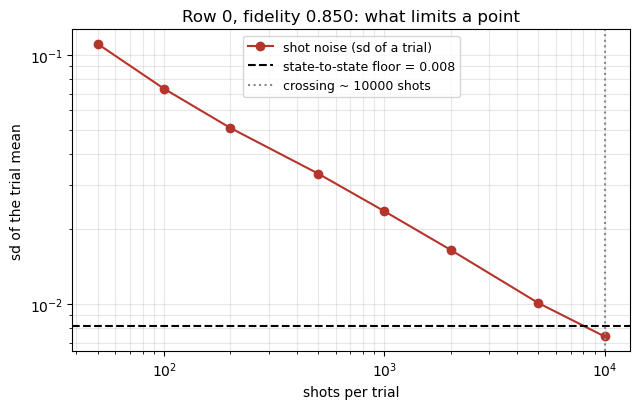

In [38]:
# ===== CALIBRATION: how many shots per trial does one point actually need? =====
# One row, one fidelity. Separates the two things that scatter a point:
#   shot noise      -- shrinks like 1/sqrt(shots), you control it
#   state-to-state  -- different random wrong-states AT THE SAME FIDELITY have
#                      genuinely different shadow overlaps; a floor no number of
#                      shots removes.
# Past the crossing point, more shots buy nothing, so that is the number to use.
N_S    = 5                                    # qubits per row: 32 amplitudes
CHUNKS = [np.asarray(c, dtype=complex) / np.linalg.norm(c) for c in chunks]

ROW, FIDELITY = 0, 0.85
SHOT_LADDER   = [50, 100, 200, 500, 1000, 2000, 5000, 10000]
N_REPEATS     = 300      # repeats per ladder rung, to measure the shot noise
N_STATES      = 300      # independent wrong-states, to measure the floor
CAL_SEED      = 7

_H, _Sdg = np.array([[1, 1], [1, -1]]) / np.sqrt(2), np.diag([1, -1j]).astype(complex)

def rot_probs(vec, q, p):
    """|rotated vec|^2 for Pauli p on qubit q of a 5-qubit (32-amplitude) state."""
    if p == 2:
        return np.abs(vec) ** 2
    U = _H if p == 0 else _H @ _Sdg
    v3 = vec.reshape(-1, 2, 2 ** q)
    b0, b1 = v3[:, 0, :], v3[:, 1, :]
    out = np.empty_like(v3)
    out[:, 0, :], out[:, 1, :] = U[0,0]*b0 + U[0,1]*b1, U[1,0]*b0 + U[1,1]*b1
    return np.abs(out.reshape(-1)) ** 2

def omega_table(target, tol=1e-12):
    """T[q, p, idx] = the estimate a shot scores if the shadow target were qubit q
    in basis p and the measured 5-bit outcome were idx. Only 5*3*32 = 480 possible
    values, so every trial afterwards is a table lookup rather than linear algebra.
    Cells with no ideal support (pair norm below tol -- float dust at ~1e-16, not
    exactly zero) are set to 0 rather than scored against normalised rounding error."""
    T = np.empty((N_S, 3, 2 ** N_S))
    for q in range(N_S):
        pos = N_S - 1 - q
        for idx in range(2 ** N_S):
            b = np.binary_repr(idx, width=N_S)
            z, o = b[:pos] + "0" + b[pos+1:], b[:pos] + "1" + b[pos+1:]
            v = np.array([target[int(z, 2)], target[int(o, 2)]], dtype=complex)
            nv = np.linalg.norm(v)
            for p in range(3):
                T[q, p, idx] = 0.0 if nv < tol else compute_local_overlap(
                    v / nv, int(b[pos]), PAULIS[p])
    return T

def state_at_fidelity(target, f, rng):
    """Random state of fidelity EXACTLY f. Projecting the noise onto the
    orthogonal complement first makes <target|nu> = 0, so the superposition is
    already normalised and F = |<chi|target>|^2 = f identically."""
    nu = rng.normal(size=target.shape) + 1j * rng.normal(size=target.shape)
    nu -= np.vdot(target, nu) * target          # Gram-Schmidt
    nu /= np.linalg.norm(nu)
    return np.sqrt(f) * target + np.sqrt(1 - f) * nu, float(f)

def exact_mean(T, psi):
    """The value a trial converges to as shots -> infinity: the design average of
    E[omega] over all 15 (qubit, Pauli) choices. No sampling, so no shot noise."""
    return float(np.mean([rot_probs(psi, q, p) @ T[q, p]
                          for q in range(N_S) for p in range(3)]))

def run_trial(T, psi, n_shots, rng):
    """One simulated experiment: n_shots uniform (qubit, Pauli) draws, outcomes
    sampled from psi, each scored against the target. Returns the mean."""
    cells = rng.multinomial(n_shots, np.full(3 * N_S, 1 / (3 * N_S)))
    tot = 0.0
    for c, n in enumerate(cells):
        if not n:
            continue
        q, p = divmod(c, 3)
        idx = rng.choice(2 ** N_S, size=n, p=rot_probs(psi, q, p))
        tot += T[q, p, idx].sum()
    return tot / n_shots

# ---------------------------------------------------------------- run it
rng = np.random.default_rng(CAL_SEED)
tgt = CHUNKS[ROW]
T   = omega_table(tgt)

psi, f_actual = state_at_fidelity(tgt, FIDELITY, rng)
truth = exact_mean(T, psi)
print(f"row {ROW}, requested fidelity {FIDELITY} -> actual {f_actual:.4f}")
print(f"exact shadow overlap for this one state (shots -> inf): {truth:.4f}\n")

print(f"{'shots':>7}{'trial sd':>12}{'90% CI half':>14}{'bias':>10}")
sds = []
for n in SHOT_LADDER:
    vals = np.array([run_trial(T, psi, n, rng) for _ in range(N_REPEATS)])
    sd = vals.std(ddof=1); sds.append(sd)
    print(f"{n:>7}{sd:>12.4f}{1.645*sd:>14.4f}{vals.mean()-truth:>+10.4f}")

floor = np.array([exact_mean(T, state_at_fidelity(tgt, FIDELITY, rng)[0])
                  for _ in range(N_STATES)])
print(f"\nstate-to-state sd at this fidelity (the floor): {floor.std(ddof=1):.4f}")
good = next((n for n, s in zip(SHOT_LADDER, sds) if s < floor.std(ddof=1)), None)
print(f"shot noise drops below that floor at ~{good} shots/trial"
      if good else "shot noise never reaches the floor on this ladder -- extend it")

fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.loglog(SHOT_LADDER, sds, "o-", color="#b5342c", label="shot noise (sd of a trial)")
ax.axhline(floor.std(ddof=1), color="black", ls="--",
           label=f"state-to-state floor = {floor.std(ddof=1):.3f}")
if good:
    ax.axvline(good, color="#888888", ls=":", label=f"crossing ~ {good} shots")
ax.set_xlabel("shots per trial"); ax.set_ylabel("sd of the trial mean")
ax.set_title(f"Row {ROW}, fidelity {f_actual:.3f}: what limits a point")
ax.grid(alpha=0.3, which="both"); ax.legend(fontsize=9)
plt.tight_layout(); plt.show()


5000 shots/trial, adding 9000 trials per row (existing: [9000, 9000, 9000, 9000])
  row 0: +9000 -> 18000 trials (estimate spans 0.282 to 1.025)
  row 1: +9000 -> 18000 trials (estimate spans 0.338 to 1.026)
  row 2: +9000 -> 18000 trials (estimate spans 0.317 to 1.026)
  row 3: +9000 -> 18000 trials (estimate spans 0.307 to 1.025)


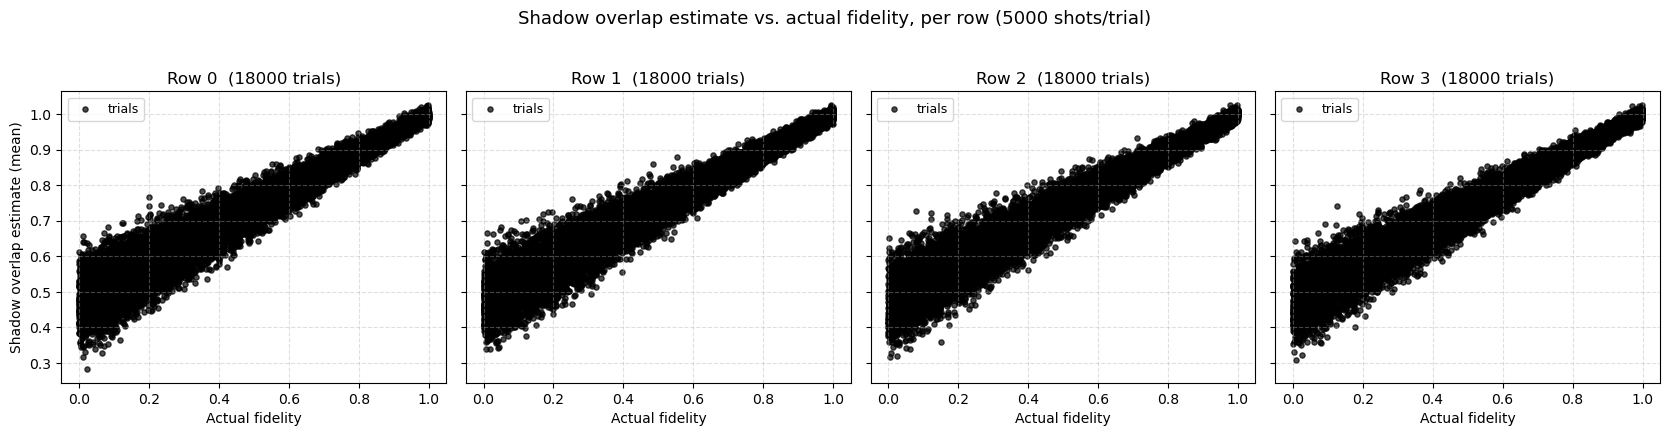


saved -> shadow_vs_fidelity_rows_orth.npz   keys: row<i>_fid, row<i>_est, row<i>_exact
'exact' is the shots -> infinity value of the same trial, stored so you can plot the relationship without shot noise if you want it.


In [43]:
# ===== SHADOW OVERLAP vs FIDELITY, one panel per row =====
# Needs the helper functions from the calibration cell (omega_table,
# state_at_fidelity, exact_mean, run_trial, rot_probs).
# Appends to the .npz on every row, so it is safe to stop and re-run: raise
# N_TRIALS and run again to add points to what is already there.
SHOTS_PER_TRIAL = 5000                          # from the calibration cell
N_TRIALS        = 9000                           # per row, ADDED to whatever is saved
FID_RANGE       = (0.0, 1.0)
ROWS_FILE       = "shadow_vs_fidelity_rows_orth.npz"
PROD_SEED       = None                          # None = fresh randomness each run
def state_at_fidelity(target, f, rng):
    """Random state of fidelity EXACTLY f. Projecting the noise onto the
    orthogonal complement first makes <target|nu> = 0, so the superposition is
    already normalised and F = |<chi|target>|^2 = f identically -- there is no
    realised-vs-nominal distinction to record."""
    nu = rng.normal(size=target.shape) + 1j * rng.normal(size=target.shape)
    nu -= np.vdot(target, nu) * target          # Gram-Schmidt
    nu /= np.linalg.norm(nu)
    psi = np.sqrt(f) * target + np.sqrt(1 - f) * nu
    return psi, float(f)

def load_rows(path=ROWS_FILE):
    if not os.path.exists(path):
        return {i: {k: np.empty(0) for k in ("fid", "est", "exact")} for i in range(len(CHUNKS))}
    with np.load(path) as z:          # context manager: releases the file handle,
        return {i: {k: z[f"row{i}_{k}"] for k in ("fid", "est", "exact")}   # else Windows
                for i in range(len(CHUNKS))}                                # blocks os.replace

def save_rows(store, path=ROWS_FILE):
    tmp = path + ".tmp.npz"
    np.savez(tmp, shots_per_trial=SHOTS_PER_TRIAL,
             **{f"row{i}_{k}": v[k] for i, v in store.items() for k in ("fid", "est", "exact")})
    os.replace(tmp, path)

store = load_rows()
rng = np.random.default_rng(PROD_SEED)
print(f"{SHOTS_PER_TRIAL} shots/trial, adding {N_TRIALS} trials per row "
      f"(existing: {[len(store[i]['fid']) for i in store]})")

for i, target in enumerate(CHUNKS):
    T = omega_table(target)
    fid, est, exa = [], [], []
    for t in range(N_TRIALS):
        f = rng.uniform(*FID_RANGE)
        psi, f_actual = state_at_fidelity(target, f, rng)
        fid.append(f_actual)
        est.append(run_trial(T, psi, SHOTS_PER_TRIAL, rng))
        exa.append(exact_mean(T, psi))
    for k, v in (("fid", fid), ("est", est), ("exact", exa)):
        store[i][k] = np.concatenate([store[i][k], np.asarray(v, float)])
    save_rows(store)
    print(f"  row {i}: +{N_TRIALS} -> {len(store[i]['fid'])} trials "
          f"(estimate spans {store[i]['est'].min():.3f} to {store[i]['est'].max():.3f})")

fig, axes = plt.subplots(1, len(CHUNKS), figsize=(4.2 * len(CHUNKS), 4.4),
                         sharex=True, sharey=True)
for i, ax in enumerate(np.atleast_1d(axes)):
    d = store[i]
    ax.scatter(d["fid"], d["est"], color="black", alpha=0.7, s=14, label="trials")
    ax.set_xlabel("Actual fidelity")
    ax.set_title(f"Row {i}  ({len(d['fid'])} trials)")
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.legend(fontsize=9, loc="upper left")
np.atleast_1d(axes)[0].set_ylabel("Shadow overlap estimate (mean)")
fig.suptitle(f"Shadow overlap estimate vs. actual fidelity, per row "
             f"({SHOTS_PER_TRIAL} shots/trial)", fontsize=13)
plt.tight_layout(rect=(0, 0, 1, 0.95)); plt.show()
print(f"\nsaved -> {ROWS_FILE}   keys: row<i>_fid, row<i>_est, row<i>_exact")
print("'exact' is the shots -> infinity value of the same trial, stored so you can "
      "plot the relationship without shot noise if you want it.")


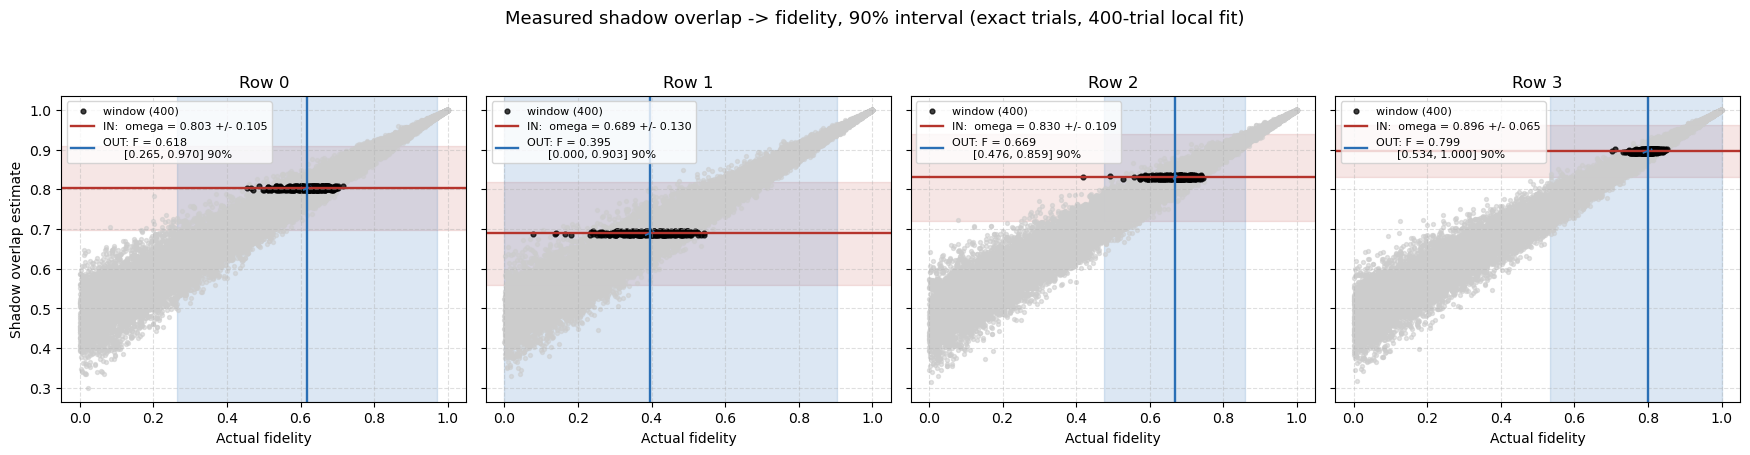

 row        measured omega        F      90% interval   width   dF/dw
   0       0.803 +/- 0.105    0.618   [0.265, 0.970]   0.705    1.99
   1       0.689 +/- 0.130    0.395   [0.000, 0.903]   0.903    2.32
   2       0.830 +/- 0.109    0.669   [0.476, 0.859]   0.384    1.01
   3       0.896 +/- 0.065    0.799   [0.534, 1.000]   0.466    2.45

where each interval's width comes from (1 sd each, added in quadrature):
  row 0: state-to-state 0.045   your omega error 0.209   -> your shot count dominates
  row 1: state-to-state 0.071   your omega error 0.301   -> your shot count dominates
  row 2: state-to-state 0.040   your omega error 0.110   -> your shot count dominates
  row 3: state-to-state 0.022   your omega error 0.160   -> your shot count dominates

window check -- sd should be flat, i.e. the choice of k is not setting the answer:
  row 0:  k=50:0.050  k=100:0.046  k=200:0.044  k=400:0.045  k=800:0.043  k=1600:0.045
  row 1:  k=50:0.070  k=100:0.072  k=200:0.071  k=400:0.071  k=80

In [44]:
# ===== INVERSION: you put in a measured omega, it gives back a fidelity + CI =====
# INPUT below: one measured shadow overlap per row, and its uncertainty.
# OUTPUT: for each row, the fidelity that omega implies, with a confidence
#         interval, plus a panel showing the omega band mapping to a fidelity band.
#
# It reads the TRIALS saved by the production cell (shadow_vs_fidelity_rows.npz),
# not the plots -- the plots and this cell are two different views of that file.
#
# Method: local linear (LOESS-style) inverse regression. Take the k trials whose
# omega is nearest yours, fit F = a + b*(omega - omega*) across them, and read off
# a. Fitting a line rather than averaging a flat band removes the systematic drift
# of F across the window, which would otherwise masquerade as spread.
#
# The interval is built by resampling the fit's own residuals rather than assuming
# a bell curve, because they are measurably left-skewed (a state can be a lot worse
# than typical at a given omega, but cannot be much better than F = 1). So expect
# asymmetric intervals -- that is real, not a bug.

MEASURED = {              # row -> (measured omega, uncertainty on it; use 0 if none)
    0: (0.803, 0.105),
    1: (0.689, 0.130),    # was (0.608, 0.166) before the no-support fix
    2: (0.830, 0.109),
    3: (0.896, 0.065),    # was (0.887, 0.070)
}
CONF         = 0.90       # confidence level for the interval
K_NEIGHBOURS = 400        # trials nearest omega* used for the local fit
USE          = "exact"    # "exact" (no shot noise) or "est" (finite-shot trials)
ROWS_FILE    = "shadow_vs_fidelity_rows_orth.npz"
with np.load(ROWS_FILE) as _z:        # copy out, then release the handle
    z = {k: _z[k] for k in _z.files}

K_LADDER     = [50, 100, 200, 400, 800, 1600]
N_MC, MC_SEED = 200_000, 0

def invert(F, w, omega_star, k):
    """Fit F = a + b*(omega - omega*) over the k trials nearest omega*."""
    sel = np.argsort(np.abs(w - omega_star))[:min(k, len(w))]
    ww, ff = w[sel] - omega_star, F[sel]
    b, a = np.polyfit(ww, ff, 1)
    resid = ff - (a + b * ww)
    return dict(a=a, b=b, resid=resid, sd=resid.std(ddof=2), sel=sel,
                se=resid.std(ddof=2) / np.sqrt(len(sel)),
                lo=w[sel].min(), hi=w[sel].max(), n=len(sel))

def predict(fit, omega_star, omega_se, conf, rng, n=N_MC):
    """Confidence interval on the fidelity of the state you actually measured.
    Two independent unknowns, both folded in:
      which state you have -- drawn from the empirical residual pool, so the
                              interval keeps the real skew instead of a bell curve
      what omega really is -- your own measurement error, if you supplied one"""
    draws = rng.normal(omega_star, omega_se, n) if omega_se else np.full(n, omega_star)
    vals = fit["a"] + fit["b"] * (draws - omega_star) + rng.choice(fit["resid"], n)
    lo, hi = np.percentile(vals, [(1 - conf) / 2 * 100, (1 + conf) / 2 * 100])
    return float(np.clip(lo, 0, 1)), float(np.clip(hi, 0, 1))

with np.load(ROWS_FILE) as _z:          # copy out, then release the handle
    z = {k: _z[k] for k in _z.files}
rng = np.random.default_rng(MC_SEED)
rows = sorted(MEASURED)
fig, axes = plt.subplots(1, len(rows), figsize=(4.4 * len(rows), 4.6),
                         sharex=True, sharey=True)
results = {}

for ax, row in zip(np.atleast_1d(axes), rows):
    omega_star, omega_se = MEASURED[row]
    w, F = z[f"row{row}_{USE}"], z[f"row{row}_fid"]
    if not (w.min() <= omega_star <= w.max()):
        print(f"WARNING row {row}: omega* = {omega_star} is outside the simulated "
              f"range [{w.min():.3f}, {w.max():.3f}] -- extrapolating")
    fit = invert(F, w, omega_star, K_NEIGHBOURS)
    lo, hi = predict(fit, omega_star, omega_se, CONF, rng)
    results[row] = (fit, lo, hi)

    inside = np.zeros(len(w), bool); inside[fit["sel"]] = True
    ax.scatter(F[~inside], w[~inside], color="#cccccc", alpha=0.55, s=8)
    ax.scatter(F[inside],  w[inside],  color="black",   alpha=0.75, s=12,
               label=f"window ({fit['n']})")
    if omega_se:
        ax.axhspan(omega_star - omega_se, omega_star + omega_se,
                   color="#b5342c", alpha=0.12, zorder=0)
    ax.axhline(omega_star, color="#b5342c", lw=1.7,
               label=f"IN:  omega = {omega_star:.3f}"
                     + (f" +/- {omega_se:.3f}" if omega_se else ""))
    ax.axvspan(lo, hi, color="#2a6fb5", alpha=0.16, zorder=0)
    ax.axvline(fit["a"], color="#2a6fb5", lw=1.7,
               label=f"OUT: F = {fit['a']:.3f}\n      [{lo:.3f}, {hi:.3f}] {CONF:.0%}")
    xs = np.linspace(fit["lo"], fit["hi"], 50)
    ax.plot(fit["a"] + fit["b"] * (xs - omega_star), xs,
            color="#2a6fb5", ls="--", lw=1.2)
    ax.set_xlabel("Actual fidelity"); ax.set_title(f"Row {row}")
    ax.grid(True, ls="--", alpha=0.4); ax.legend(fontsize=8, loc="upper left")
np.atleast_1d(axes)[0].set_ylabel("Shadow overlap estimate")
fig.suptitle(f"Measured shadow overlap -> fidelity, {CONF:.0%} interval "
             f"({USE} trials, {K_NEIGHBOURS}-trial local fit)", fontsize=13)
plt.tight_layout(rect=(0, 0, 1, 0.94)); plt.show()

print(f"{'row':>4}{'measured omega':>22}{'F':>9}{'  ' + f'{CONF:.0%} interval':>18}"
      f"{'width':>8}{'dF/dw':>8}")
for row in rows:
    omega_star, omega_se = MEASURED[row]
    fit, lo, hi = results[row]
    om = f"{omega_star:.3f} +/- {omega_se:.3f}" if omega_se else f"{omega_star:.3f}"
    print(f"{row:>4}{om:>22}{fit['a']:>9.3f}   [{lo:.3f}, {hi:.3f}]{hi-lo:>8.3f}"
          f"{fit['b']:>8.2f}")

print(f"\nwhere each interval's width comes from (1 sd each, added in quadrature):")
for row in rows:
    omega_star, omega_se = MEASURED[row]
    fit, _, _ = results[row]
    meas = abs(fit["b"]) * omega_se
    print(f"  row {row}: state-to-state {fit['sd']:.3f}   your omega error {meas:.3f}"
          f"   -> {'your shot count' if meas > fit['sd'] else 'the physics'} dominates")

print(f"\nwindow check -- sd should be flat, i.e. the choice of k is not setting the answer:")
for row in rows:
    omega_star, _ = MEASURED[row]
    w, F = z[f"row{row}_{USE}"], z[f"row{row}_fid"]
    line = "  ".join(f"k={k}:{invert(F, w, omega_star, k)['sd']:.3f}"
                     for k in K_LADDER if k <= len(w))
    print(f"  row {row}:  {line}")


# Additional HARDWARE RUNS for the per index certificatoin

In [75]:
# ===== 2. PLAN: what is left to run on hardware =====
# Only X slots are ever planned. Z is already paid for (every prep/ancilla-targeted
# shot is a full Z shot on the storage register) and Y is exact at 0.5 for a real
# target, so neither costs a shot.
#
# The plan is drawn ONCE and frozen to disk, so this cell is reproducible: re-running
# it re-reads the same plan rather than redrawing it. Delete BR_PLAN_FILE to redraw.
#
# Allocation is BALANCED, not random: the Z bank size is known exactly, so each
# storage qubit is topped up to the same X count instead of hitting that on average.
# Randomising the counts would only add noise to a number we already know.
#
# Each slot is one circuit and one job, run start to finish, because there is an
# upfront cost per circuit. The only randomisation is therefore the ORDER the five
# slots are run in -- free, and it stops session drift from lining up with qubit
# index. That order is frozen in the plan file too.
import json, time, random

BR_STORE      = "shadow_branch_hw.pkl"
BR_PLAN_FILE  = "shadow_branch_plan.json"
BR_JOB_INDEX  = "shadow_branch_jobs.json"
BR_ORDER_SEED = 3

S_QUBITS, I_QUBITS, N_S, M_BRANCH = tuple(range(5)), (5, 6), 5, 4

# ---- shot classification helpers -------------------------------------------
# Defined here as well as in the PREP cell, because PREP is deleted after its one
# run and the INGEST cell still needs them.
def br_sv_bits(key):
    if isinstance(key, (tuple, list)):
        return nexus_to_statevector_order("".join(map(str, key)), PERM)
    return str(key)

def br_s_bits(b):  return b[-N_S:]
def br_branch(b):
    n = len(b)
    return sum(int(b[n - 1 - q]) << k for k, q in enumerate(I_QUBITS))

def br_key(branch, sbits):  return f"{branch}:{sbits}"

def br_load(path=BR_STORE):
    if not os.path.exists(path):
        return None
    with open(path, "rb") as f:
        return pickle.load(f)

def br_atomic(obj, path):
    tmp = path + ".tmp"
    with open(tmp, "wb") as f:
        pickle.dump(obj, f)
    for _ in range(30):
        try:
            os.replace(tmp, path); return
        except PermissionError:
            time.sleep(0.5)
    os.replace(tmp, path)

def br_index(path=BR_JOB_INDEX):
    return json.load(open(path)) if os.path.exists(path) else {}

def br_register(slot, name, shots, extra=None, path=BR_JOB_INDEX):
    idx = br_index(path)
    idx[str(tuple(slot))] = {"name": name, "shots": int(shots),
                             "submitted": time.strftime("%Y-%m-%d %H:%M:%S"), **(extra or {})}
    tmp = path + ".tmp"
    json.dump(idx, open(tmp, "w"), indent=1)
    os.replace(tmp, path)

def br_counts(store):
    """-> (n_z, {q: n_x}, {q: n_y_measured}) from a per-branch store."""
    nz = sum(store["z_pool"].values())
    nx = {q: sum(store["xy"].get((q, 0), {}).values()) for q in S_QUBITS}
    ny = {q: sum(store["xy"].get((q, 1), {}).values()) for q in S_QUBITS}
    return nz, nx, ny

store = br_load()
assert store is not None, f"{BR_STORE} not found -- run the PREP cell once first"
BANK_Z, have_x, have_y = br_counts(store)

# ---- the plan: drawn once, then loaded from disk forever --------------------
def br_write_plan(plan):
    tmp = BR_PLAN_FILE + ".tmp"
    json.dump(plan, open(tmp, "w"), indent=1)
    os.replace(tmp, BR_PLAN_FILE)

if os.path.exists(BR_PLAN_FILE):
    plan = json.load(open(BR_PLAN_FILE))
    need = {int(k): v for k, v in plan["need"].items()}
    print(f"loaded frozen plan from {BR_PLAN_FILE} (made {plan['created']})")
    if "slot_order" not in plan:          # plan written before the order was frozen
        _o = list(S_QUBITS)
        random.Random(plan.get("order_seed", BR_ORDER_SEED)).shuffle(_o)
        plan["slot_order"] = [int(q) for q in _o]
        br_write_plan(plan)
        print(f"  added a frozen slot order to the existing plan: {plan['slot_order']}")
else:
    target = BANK_Z // N_S
    need = {q: max(target - have_x[q], 0) for q in S_QUBITS}
    order = list(S_QUBITS)
    random.Random(BR_ORDER_SEED).shuffle(order)
    plan = {"target_per_qubit": int(target), "bank_z_at_plan": int(BANK_Z),
            "have_x_at_plan": {str(q): int(have_x[q]) for q in S_QUBITS},
            "need": {str(q): int(need[q]) for q in S_QUBITS},
            "slot_order": [int(q) for q in order],
            "order_seed": BR_ORDER_SEED, "created": time.strftime("%Y-%m-%d %H:%M:%S")}
    br_write_plan(plan)
    print(f"NEW plan written to {BR_PLAN_FILE}")

TARGET = plan["target_per_qubit"]
print(f"\nZ bank {BANK_Z} shots  ->  X target {TARGET} per storage qubit "
      f"({TARGET*N_S} X shots total)")
print(f"Y: analytic at 0.5, zero variance -- never planned, never submitted"
      f"   ({sum(have_y.values())} measured Y shots on file, kept as a null check)\n")

# ---- status ----------------------------------------------------------------
idx = br_index()
print(f"{'slot':>10}{'have':>7}{'plan':>7}{'sent':>7}{'todo':>7}   status")
todo = {}
for q in S_QUBITS:
    key = str((q, 0))
    sent = idx.get(key, {}).get("shots", 0) if key in idx else 0
    done = have_x[q] - plan["have_x_at_plan"][str(q)]     # filed since the plan was frozen
    left = max(need[q] - done, 0)
    todo[q] = left
    state = ("filed" if left == 0 else
             "in flight" if key in idx else "not run")
    print(f"{'X on S'+str(q):>10}{have_x[q]:>7d}{need[q]:>7d}{sent:>7d}{left:>7d}   {state}")
print(f"{'total':>10}{sum(have_x.values()):>7d}{sum(need.values()):>7d}"
      f"{sum(v.get('shots',0) for v in idx.values()):>7d}{sum(todo.values()):>7d}")

# ---- the run order: one circuit per slot, run to completion -----------------
ORDER = [int(q) for q in plan["slot_order"]]
print(f"\nrun the slots in this frozen random order (seed {plan['order_seed']}):")
for n, q in enumerate(ORDER, 1):
    state = "done" if todo[q] == 0 else ("in flight" if str((q, 0)) in idx else "")
    print(f"  {n}. X on S{q}   {need[q]:>3d} shots   {state}")
print("  one circuit, one job per slot -- there is an upfront cost per circuit, so")
print("  each slot is run start to finish rather than interleaved. Randomising which")
print("  qubit goes first is free and keeps session drift off the qubit index.")

nxt = next((q for q in ORDER if todo[q] > 0 and str((q, 0)) not in idx), None)
print(f"\nnext slot to run: "
      f"{('BR_SLOT = (%d, 0)   # %d shots' % (nxt, todo[nxt])) if nxt is not None else 'none -- plan complete'}")


loaded frozen plan from shadow_branch_plan.json (made 2026-09-03 10:58:40)

Z bank 165 shots  ->  X target 33 per storage qubit (165 X shots total)
Y: analytic at 0.5, zero variance -- never planned, never submitted   (15 measured Y shots on file, kept as a null check)

      slot   have   plan   sent   todo   status
   X on S0     33     32     32      0   filed
   X on S1     33     29     29      0   filed
   X on S2     33     29     29      0   filed
   X on S3     33     31     31      0   filed
   X on S4     33     27     27      0   filed
     total    165    148    148      0

run the slots in this frozen random order (seed 3):
  1. X on S0    32 shots   done
  2. X on S2    29 shots   done
  3. X on S3    31 shots   done
  4. X on S4    27 shots   done
  5. X on S1    29 shots   done
  one circuit, one job per slot -- there is an upfront cost per circuit, so
  each slot is run start to finish rather than interleaved. Randomising which
  qubit goes first is free and keeps ses

  note: 7 of 495 shots landed outside the ideal support and were scored omega = 0


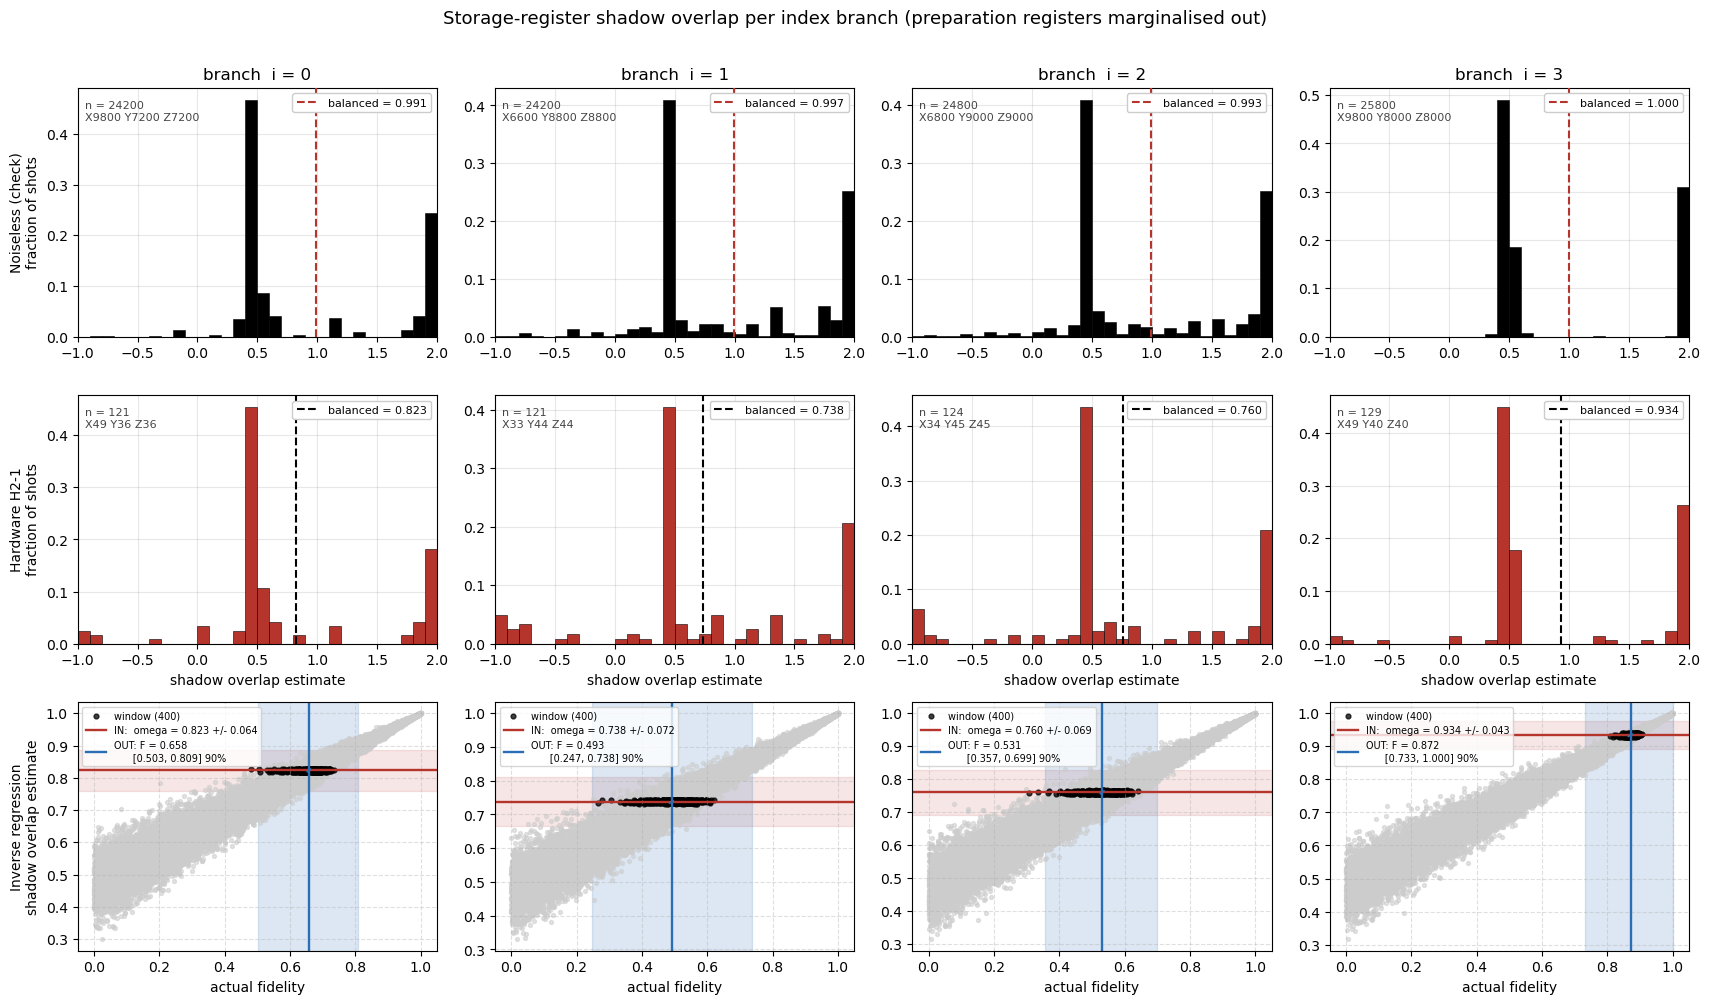

                           branch 0            branch 1            branch 2            branch 3           pooled
Noiseless (check)     +0.991+/-0.002(24200)  +0.997+/-0.003(24200)  +0.993+/-0.003(24800)  +1.000+/-0.000(25800)   +0.9880+/-0.0012
Hardware H2-1         +0.823+/-0.064( 121)  +0.738+/-0.072( 121)  +0.760+/-0.069( 124)  +0.934+/-0.043( 129)   +0.8114+/-0.0315

means are BALANCED (average of the X, Y and Z means) -- a plain mean would be pulled by the Z surplus; a perfect state gives 1.000 in every cell, so 1 - value
is the shortfall. The Y stratum is exactly 0.5 with zero spread, so it adds nothing to the SE; X and Z alone set the error bars.

 branch        measured omega        F      90% interval   width   dF/dw
      0       0.823 +/- 0.064    0.658   [0.503, 0.809]   0.306    1.32
      1       0.738 +/- 0.072    0.493   [0.247, 0.738]   0.491    1.91
      2       0.760 +/- 0.069    0.531   [0.357, 0.699]   0.342    1.31
      3       0.934 +/- 0.043    0.872   [0.733,

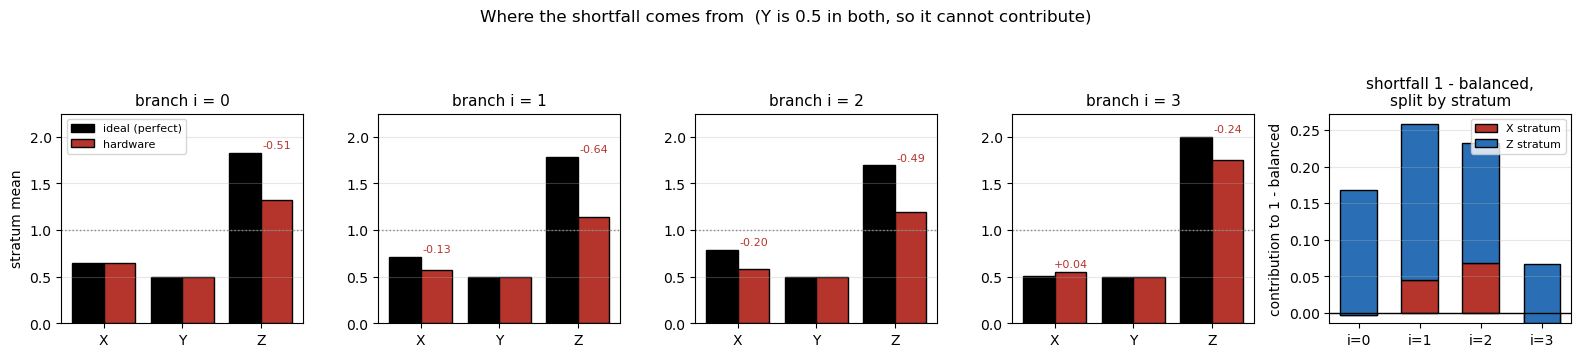

 branch  X ideal    X hw   X gap     Z ideal    Z hw   Z gap      1-bal   from X  from Z
      0    0.641   0.648  +0.007       1.830   1.320  -0.510      0.168   -0.002  +0.170
      1    0.709   0.575  -0.134       1.782   1.139  -0.642      0.259   +0.045  +0.214
      2    0.785   0.581  -0.204       1.693   1.199  -0.494      0.233   +0.068  +0.165
      3    0.504   0.547  +0.043       1.997   1.756  -0.241      0.066   -0.014  +0.080

Z is already fully measured (165 shots), so its gap is FIXED -- more X shots
cannot close it. X is the only stratum still moving, and it enters at 1/3 weight.


In [78]:
# ============ STORAGE-REGISTER SHADOW OVERLAP, PER INDEX BRANCH ============
# Same cell as before, reading the per-branch store instead of the raw pkl, with a
# third row that turns each measured omega into a fidelity.
#
# THE DESIGN IS UNIFORM: equal numbers of X, Y and Z. Every stratum is plotted at its
# design size, so the histogram shows the same design the mean assumes.
#   Z  165 measured shots. Every prep/ancilla-targeted shot leaves all five storage
#      qubits in Z, so the bank is 165, each shot assigned one S qubit, round robin.
#   Y  165 shots at exactly 0.5, not run. For a REAL target a Y measurement gives
#      |<s_Y|phi>|^2 = 1/2 for both outcomes whatever the device did, so omega = 0.5
#      identically. These are not invented data, they are the value the measurement is
#      guaranteed to return -- which is why running Y would be a waste of shots. The Y
#      shots genuinely on file are checked against 0.5 at the bottom as a null test.
#   X  165 planned, however many are in the file so far. THIS is the incomplete one.
#
# So a third of the mass sits at 0.5 by construction, and while X is short the other
# two strata are over-represented and the mean is pulled. That is meant to show.
import random

RED, BLACK, NBINS = "#b5342c", "#000000", 30
S_QUBITS, N_S, M_BRANCH = tuple(range(5)), 5, 4
BR_STORE  = "shadow_branch_hw.pkl"
ROWS_FILE = "shadow_vs_fidelity_rows_orth.npz"
Y_VALUE, Z_ASSIGN_SEED, SIM_SEED, SIM_REPS = 0.5, 11, 2026, 200
CONF, K_NEIGHBOURS, USE, N_MC, MC_SEED = 0.90, 400, "exact", 200_000, 0
NO_SUPPORT_TOL = 1e-12

CHUNKS = [np.asarray(c, dtype=complex) / np.linalg.norm(c) for c in chunks]
assert len(CHUNKS) == M_BRANCH and len(CHUNKS[0]) == 2 ** N_S

_no_support = {"n": 0}
def omega(chunk, sb, q, p, tol=NO_SUPPORT_TOL):
    """One shadow-overlap estimate against a 32-amplitude chunk.
    The no-support guard MUST be a tolerance, not `== 0`: the ideally-vanishing
    amplitudes are stored as ~1e-16, never exactly zero."""
    pos = N_S - 1 - q
    z, o = sb[:pos] + "0" + sb[pos+1:], sb[:pos] + "1" + sb[pos+1:]
    v = np.array([chunk[int(z, 2)], chunk[int(o, 2)]], dtype=complex)
    nv = np.linalg.norm(v)
    if nv < tol:
        _no_support["n"] += 1
        return 0.0
    return compute_local_overlap(v / nv, int(sb[pos]), PAULIS[p])

def storage_shots(store, seed=Z_ASSIGN_SEED):
    """-> [(s_bits, branch, target_qubit, pauli)] for every usable shot.
    X: the qubit the rotation landed on. Z: the whole bank, each shot assigned one S
    qubit, never reused. Y: one per Z shot in the same branch, since the design is
    uniform and every Y shot is known to be 0.5 without running it."""
    recs = []
    for (q, p), d in store["xy"].items():
        if p == 1:
            continue                       # measured Y superseded by the analytic stratum
        for k, c in d.items():
            i, sb = k.split(":")
            recs += [(sb, int(i), q, p)] * c
    zs = [(k.split(":")[1], int(k.split(":")[0]))
          for k, c in store["z_pool"].items() for _ in range(c)]
    random.Random(seed).shuffle(zs)
    recs += [(sb, i, S_QUBITS[j % N_S], 2) for j, (sb, i) in enumerate(zs)]
    recs += [(sb, i, S_QUBITS[j % N_S], 1) for j, (sb, i) in enumerate(zs)]
    return recs

def measured_y(store):
    """The Y shots actually on file -- used only as a null test that omega == 0.5."""
    return [(k.split(":")[1], int(k.split(":")[0]), q)
            for (q, p), d in store["xy"].items() if p == 1
            for k, c in d.items() for _ in range(c)]

_H, _Sdg = np.array([[1, 1], [1, -1]]) / np.sqrt(2), np.diag([1, -1j]).astype(complex)
def _rot_probs(vec, q, p):
    if p == 2:
        return np.abs(vec) ** 2
    U = _H if p == 0 else _H @ _Sdg
    v3 = vec.reshape(-1, 2, 2 ** q)
    b0, b1 = v3[:, 0, :], v3[:, 1, :]
    out = np.empty_like(v3)
    out[:, 0, :], out[:, 1, :] = U[0,0]*b0 + U[0,1]*b1, U[1,0]*b0 + U[1,1]*b1
    return np.abs(out.reshape(-1)) ** 2

def sim_like(recs, reps=SIM_REPS, seed=SIM_SEED):
    """Noiseless reference matched cell-for-cell to `recs`: same (branch, qubit,
    Pauli) design, only the outcome bits resampled from the ideal chunk."""
    rng, cdfs, out = np.random.default_rng(seed), {}, []
    for _, i, q, p in recs:
        if (i, q, p) not in cdfs:
            cdfs[(i, q, p)] = np.cumsum(_rot_probs(CHUNKS[i], q, p))
        cdf = cdfs[(i, q, p)]
        idx = np.minimum(np.searchsorted(cdf, rng.random(reps)), len(cdf) - 1)
        out += [(np.binary_repr(int(j), width=N_S), i, q, p) for j in idx]
    return out

def evaluate(recs):
    _no_support["n"] = 0
    est = np.array([omega(CHUNKS[i], sb, q, p) for sb, i, q, p in recs])
    if _no_support["n"]:
        print(f"  note: {_no_support['n']} of {len(recs)} shots landed outside the ideal "
              f"support and were scored omega = 0")
    return est, np.array([i for _, i, _, _ in recs]), np.array([p for *_, p in recs])

def pauli_var(est, pau):
    return {p: float(est[pau == p].var(ddof=1)) for p in range(3) if (pau == p).sum() > 1}

def balanced(est, pau, var_ref=None):
    """Uniform-design (X,Y,Z) mean and its SE -- unbiased at 1 for a perfect state no
    matter how lopsided the realised Pauli counts are.
    Y is exactly 0.5 with ZERO variance for a real target, so that third is known
    without measuring it and contributes nothing to the error bar. X and Z alone set
    the SE, which is why the X shortfall is what widens it."""
    ms, vs = [], []
    for p in range(3):
        v = est[pau == p]
        if p == 1:
            ms.append(Y_VALUE); vs.append(0.0); continue
        if len(v) == 0:
            return float("nan"), float("nan")
        ms.append(v.mean())
        s2 = v.var(ddof=1) if len(v) > 1 else (var_ref or {}).get(p, np.nan)
        vs.append(s2 / len(v))
    return float(np.mean(ms)), float(np.sqrt(np.nansum(vs)) / 3)

def invert(F, w, omega_star, k):
    """Fit F = a + b*(omega - omega*) over the k trials nearest omega*."""
    sel = np.argsort(np.abs(w - omega_star))[:min(k, len(w))]
    ww, ff = w[sel] - omega_star, F[sel]
    b, a = np.polyfit(ww, ff, 1)
    resid = ff - (a + b * ww)
    return dict(a=a, b=b, resid=resid, sd=resid.std(ddof=2), sel=sel,
                lo=w[sel].min(), hi=w[sel].max(), n=len(sel))

def predict(fit, omega_star, omega_se, conf, rng, n=N_MC):
    draws = rng.normal(omega_star, omega_se, n) if omega_se else np.full(n, omega_star)
    vals = fit["a"] + fit["b"] * (draws - omega_star) + rng.choice(fit["resid"], n)
    lo, hi = np.percentile(vals, [(1 - conf) / 2 * 100, (1 + conf) / 2 * 100])
    return float(np.clip(lo, 0, 1)), float(np.clip(hi, 0, 1))

# A perfect state gives a balanced mean of 1.000 in EVERY cell, so the noiseless row
# is a check that this pipeline reproduces what theory demands, not a calibration.
with open(BR_STORE, "rb") as f:
    hw_recs = storage_shots(pickle.load(f))
rows = [("Noiseless (check)", BLACK, RED,  sim_like(hw_recs)),
        ("Hardware H2-1",     RED,   BLACK, hw_recs)]

data = []
for label, fill, meanc, recs in rows:
    est, br, pau = evaluate(recs)
    data.append((label, fill, meanc, est, br, pau, pauli_var(est, pau)))
with np.load(ROWS_FILE) as _z:
    z = {k: _z[k] for k in _z.files}

edges = np.linspace(min(d[3].min() for d in data), max(d[3].max() for d in data), NBINS + 1)
fig, axes = plt.subplots(3, M_BRANCH, figsize=(4.3 * M_BRANCH, 3.4 * 3), squeeze=False)
for r, (label, fill, meanc, est, br, pau, vref) in enumerate(data):
    for i in range(M_BRANCH):
        ax, v, p = axes[r, i], est[br == i], pau[br == i]
        if len(v):
            ax.hist(v, bins=edges, weights=np.full(len(v), 1 / len(v)),
                    color=fill, edgecolor="black", lw=0.4, zorder=2)
            m, s = balanced(v, p, vref)
            ax.axvline(m, color=meanc, ls="--", lw=1.5, zorder=3,
                       label=f"balanced = {m:.3f}")
            ax.legend(fontsize=8, framealpha=1.0, loc="upper right")
            nx, ny, nz = [(p == k).sum() for k in (0, 1, 2)]
            ax.text(0.02, 0.95, f"n = {len(v)}\nX{nx} Y{ny} Z{nz}", transform=ax.transAxes,
                    va="top", fontsize=8, color="#444444")
        ax.set_xlim(edges[0], edges[-1]); ax.grid(alpha=0.3, zorder=0)
        if r == 0: ax.set_title(f"branch  i = {i}", fontsize=12)
        else: ax.set_xlabel("shadow overlap estimate")
    axes[r, 0].set_ylabel(f"{label}\nfraction of shots", fontsize=10)

# ---- row 3: the fidelity each measured omega implies ----
_, _, _, est, br, pau, vref = data[1]
rng, results = np.random.default_rng(MC_SEED), {}
for i in range(M_BRANCH):
    ax = axes[2, i]
    omega_star, omega_se = balanced(est[br == i], pau[br == i], vref)
    w, F = z[f"row{i}_{USE}"], z[f"row{i}_fid"]
    if omega_star != omega_star:
        ax.text(0.5, 0.5, "no estimate yet", transform=ax.transAxes, ha="center"); continue
    if not (w.min() <= omega_star <= w.max()):
        print(f"WARNING branch {i}: omega* = {omega_star:.3f} is outside the simulated "
              f"range [{w.min():.3f}, {w.max():.3f}] -- extrapolating")
    fit = invert(F, w, omega_star, K_NEIGHBOURS)
    lo, hi = predict(fit, omega_star, omega_se, CONF, rng)
    results[i] = (omega_star, omega_se, fit, lo, hi)
    inside = np.zeros(len(w), bool); inside[fit["sel"]] = True
    ax.scatter(F[~inside], w[~inside], color="#cccccc", alpha=0.55, s=8)
    ax.scatter(F[inside],  w[inside],  color="black",   alpha=0.75, s=12,
               label=f"window ({fit['n']})")
    ax.axhspan(omega_star - omega_se, omega_star + omega_se, color=RED, alpha=0.12, zorder=0)
    ax.axhline(omega_star, color=RED, lw=1.7,
               label=f"IN:  omega = {omega_star:.3f} +/- {omega_se:.3f}")
    ax.axvspan(lo, hi, color="#2a6fb5", alpha=0.16, zorder=0)
    ax.axvline(fit["a"], color="#2a6fb5", lw=1.7,
               label=f"OUT: F = {fit['a']:.3f}\n      [{lo:.3f}, {hi:.3f}] {CONF:.0%}")
    xs = np.linspace(fit["lo"], fit["hi"], 50)
    ax.plot(fit["a"] + fit["b"] * (xs - omega_star), xs, color="#2a6fb5", ls="--", lw=1.2)
    ax.set_xlabel("actual fidelity"); ax.grid(True, ls="--", alpha=0.4)
    ax.legend(fontsize=7, loc="upper left")
axes[2, 0].set_ylabel("Inverse regression\nshadow overlap estimate", fontsize=10)

nx = int((data[1][5] == 0).sum()); nz = int((data[1][5] == 2).sum())
warn = f"\nPROVISIONAL -- {nx} X shots against {nz} Z, {nz-nx} still to run" if nx < nz else ""
fig.suptitle("Storage-register shadow overlap per index branch "
             "(preparation registers marginalised out)" + warn,
             fontsize=13, color=RED if warn else "black")
plt.tight_layout(rect=(0, 0, 1, 0.95 if warn else 0.97))
fig.savefig("hardware_results_final.pdf", bbox_inches="tight")
plt.show()

print(f"{'':<22s}" + "  ".join(f"branch {i}".center(18) for i in range(M_BRANCH)) + "      pooled")
for label, _, _, est, br, pau, vref in data:
    cells = []
    for i in range(M_BRANCH):
        m, s = balanced(est[br == i], pau[br == i], vref)
        cells.append((f"{m:+.3f}+/-{s:.3f}({(br==i).sum():>4d})" if m == m else "-").center(18))
    m, s = balanced(est, pau, vref)
    print(f"{label:<22s}" + "  ".join(cells) + f"   {m:+.4f}+/-{s:.4f}")
print("\nmeans are BALANCED (average of the X, Y and Z means) -- a plain mean would be "
      "pulled by the Z surplus; a perfect state gives 1.000 in every cell, so 1 - value")
print("is the shortfall. The Y stratum is exactly 0.5 with zero spread, so it adds "
      "nothing to the SE; X and Z alone set the error bars.")

print(f"\n{'branch':>7}{'measured omega':>22}{'F':>9}{'  '+f'{CONF:.0%} interval':>18}"
      f"{'width':>8}{'dF/dw':>8}")
for i in sorted(results):
    om, se, fit, lo, hi = results[i]
    print(f"{i:>7}{f'{om:.3f} +/- {se:.3f}':>22}{fit['a']:>9.3f}   "
          f"[{lo:.3f}, {hi:.3f}]{hi-lo:>8.3f}{fit['b']:>8.2f}")
with open(BR_STORE, "rb") as f:
    _ym = measured_y(pickle.load(f))
if _ym:
    _v = np.array([omega(CHUNKS[i], sb, q, 1) for sb, i, q in _ym])
    print(f"\nnull test: the {len(_v)} Y shots genuinely on file give "
          f"max |omega - 0.5| = {np.abs(_v - Y_VALUE).max():.2e}  "
          f"{'PASS' if np.abs(_v - Y_VALUE).max() < 1e-9 else 'FAIL'}"
          f"  -- this is what licenses the {nz} analytic Y above")
if nx < nz:
    print(f"PROVISIONAL -- {nz-nx} more X shots to run; until then X is under-weighted "
          f"in the picture and the row-3 bands inherit the wide row-2 SE.")

# ---- where is the shortfall coming from? X, Y or Z ----
# balanced = (mean_X + mean_Y + mean_Z)/3, and a perfect state gives exactly 1, so
#     1 - balanced  =  [(X_ideal - X) + (Z_ideal - Z)] / 3
# i.e. the shortfall splits cleanly into an X part and a Z part. Y is 0.5 in both
# the ideal and the measurement, so it contributes nothing to the gap by construction.
_, _, _, e0, b0, p0, _ = data[0]          # noiseless = the ideal
_, _, _, e1, b1, p1, _ = data[1]          # hardware
PN = ["X", "Y", "Z"]

fig2, ax2 = plt.subplots(1, M_BRANCH + 1, figsize=(3.2 * (M_BRANCH + 1), 3.6),
                         squeeze=False)
share = {p: [] for p in range(3)}
for i in range(M_BRANCH):
    ax = ax2[0, i]
    idl = [e0[(b0 == i) & (p0 == p)].mean() for p in range(3)]
    hw  = [e1[(b1 == i) & (p1 == p)].mean() for p in range(3)]
    hw[1] = Y_VALUE                        # Y is analytic; see balanced()
    x = np.arange(3)
    ax.bar(x - 0.2, idl, 0.4, color=BLACK, edgecolor="black", label="ideal (perfect)")
    ax.bar(x + 0.2, hw,  0.4, color=RED,   edgecolor="black", label="hardware")
    for k in range(3):
        share[k].append(idl[k] - hw[k])
        if abs(idl[k] - hw[k]) > 0.02:
            ax.annotate(f"{hw[k]-idl[k]:+.2f}", (k + 0.2, max(hw[k], idl[k]) + 0.05),
                        ha="center", fontsize=8, color=RED)
    ax.axhline(1.0, color="#888888", ls=":", lw=1)
    ax.set_xticks(x); ax.set_xticklabels(PN); ax.set_ylim(0, 2.25)
    ax.set_title(f"branch i = {i}", fontsize=11); ax.grid(alpha=0.3, axis="y")
    if i == 0:
        ax.set_ylabel("stratum mean"); ax.legend(fontsize=8, loc="upper left")

ax = ax2[0, M_BRANCH]
w = 0.6
bot = np.zeros(M_BRANCH)
for k, col in ((0, "#b5342c"), (2, "#2a6fb5")):
    v = np.array(share[k]) / 3
    ax.bar(range(M_BRANCH), v, w, bottom=bot, color=col, edgecolor="black",
           label=f"{PN[k]} stratum")
    bot += v
ax.axhline(0, color="black", lw=1)
ax.set_xticks(range(M_BRANCH)); ax.set_xticklabels([f"i={i}" for i in range(M_BRANCH)])
ax.set_title("shortfall 1 - balanced,\nsplit by stratum", fontsize=11)
ax.set_ylabel("contribution to 1 - balanced"); ax.grid(alpha=0.3, axis="y")
ax.legend(fontsize=8)
fig2.suptitle("Where the shortfall comes from  (Y is 0.5 in both, so it cannot contribute)",
              fontsize=12)
plt.tight_layout(rect=(0, 0, 1, 0.92))
fig2.savefig("hardware_results_strata.pdf", bbox_inches="tight")
plt.show()

print(f"{'branch':>7}{'X ideal':>9}{'X hw':>8}{'X gap':>8}   "
      f"{'Z ideal':>9}{'Z hw':>8}{'Z gap':>8}   {'1-bal':>8}{'  from X':>9}{'from Z':>8}")
for i in range(M_BRANCH):
    idl = [e0[(b0 == i) & (p0 == p)].mean() for p in range(3)]
    hw  = [e1[(b1 == i) & (p1 == p)].mean() for p in range(3)]
    gx, gz = idl[0] - hw[0], idl[2] - hw[2]
    print(f"{i:>7}{idl[0]:>9.3f}{hw[0]:>8.3f}{-gx:>+8.3f}   "
          f"{idl[2]:>9.3f}{hw[2]:>8.3f}{-gz:>+8.3f}   "
          f"{(gx+gz)/3:>8.3f}{gx/3:>+9.3f}{gz/3:>+8.3f}")
print("\nZ is already fully measured (165 shots), so its gap is FIXED -- more X shots")
print("cannot close it. X is the only stratum still moving, and it enters at 1/3 weight.")


In [67]:
# ===== 4. CONFIG: compile one slot =====
BR_SLOT = (4, 0)          # <<< the X slot to run, from the PLAN cell's "next slot"

assert BR_SLOT[1] == 0, "only X slots are planned -- Y is analytic, Z is already banked"
assert BR_SLOT[0] in S_QUBITS, f"{BR_SLOT[0]} is not a storage qubit"
assert RUN == "hardware"
assert str(tuple(BR_SLOT)) not in br_index(), f"{BR_SLOT} already submitted"
br_shots = todo[BR_SLOT[0]]
assert br_shots > 0, f"{BR_SLOT} has nothing left to run"

br_stamp = datetime.datetime.now().strftime("%Y_%m_%d-%H-%M-%S")
br_name  = f"HWBR_MRE_{BR_SLOT}-{br_stamp}"
br_backend = qnx.QuantinuumConfig(device_name=DEVICE)

br_tkc = build_tket_circuit_from_tk_no_measure(tk_circ_clean, BR_SLOT)
br_up  = qnx.circuits.upload(circuit=br_tkc, name=br_name)
br_job = qnx.start_compile_job(programs=[br_up], backend_config=br_backend,
                               name=br_name, optimisation_level=2)
qnx.jobs.wait_for(br_job, timeout=1800, strategy=qnx.jobs.PollingStrategy())
br_ref = qnx.jobs.results(br_job)[0].get_output()

BR_POOL_PKL = "compiled_pool_branch.pkl"
br_pool = br_load(BR_POOL_PKL) or {}
br_pool[tuple(BR_SLOT)] = {"ref": br_ref, "name": br_name, "shots": int(br_shots)}
br_atomic(br_pool, BR_POOL_PKL)
print(f"compiled {BR_SLOT} -> {br_name}  ({br_shots} shots planned)")


target: qiskit q4 = S[4] (tket/clbit 26), measuring X
compiled (4, 0) -> HWBR_MRE_(4, 0)-2026_09_03-12-05-58  (27 shots planned)


In [ ]:
# ===== 5. EXECUTE: submit the compiled slot =====
BR_ARM = False        # <<< True to submit, then set back to False

assert BR_ARM, "not armed"
assert RUN == "hardware"
assert "q" not in DEVICE, f"device is still {DEVICE} -- strip the q in SETUP to arm"

br_entry = br_load("compiled_pool_branch.pkl")[tuple(BR_SLOT)]
br_name, br_shots = br_entry["name"], br_entry["shots"]
br_pkl = f"{br_name}_results.pkl"
assert not os.path.exists(br_pkl), f"{br_pkl} exists -- refusing to overwrite"

br_job_ref = qnx.start_execute_job(programs=[br_entry["ref"]], n_shots=[br_shots],
                                   backend_config=qnx.QuantinuumConfig(device_name=DEVICE),
                                   name=br_name)
with open(br_pkl, "wb") as f:
    pickle.dump([br_job_ref], f)
br_register(BR_SLOT, br_name, br_shots)
print(f"submitted {BR_SLOT}: {br_shots} shots -> {br_name}")


submitted (4, 0): 27 shots -> HWBR_MRE_(4, 0)-2026_09_03-12-05-58


In [74]:
# ===== 6. INGEST: download finished slots into the per-branch store =====
# Classifies each returned shot the same way the PREP cell did, so a shot that
# somehow landed on an index qubit is dropped rather than silently mis-filed.
BR_ONLY, BR_REANALYSE = None, False
import ast
from qnexus.models.job_status import JobStatusEnum

br_store = br_load(BR_STORE)
assert br_store is not None, f"{BR_STORE} not found -- run the PREP cell once first"
br_idx = br_index()

def br_ready(name):
    pkl = f"{name}_results.pkl"
    if not os.path.exists(pkl):
        print(f"  {pkl} missing -- skipped"); return None
    with open(pkl, "rb") as f:
        refs = pickle.load(f)
    try:
        st = qnx.jobs.status(refs[0]).status
    except Exception as e:
        print(f"  {name}: status failed ({type(e).__name__}: {e})"); return None
    if st != JobStatusEnum.COMPLETED:
        print(f"  {name}: {st.value} -- not ready"); return None
    return qnx.jobs.results(refs[0])[0].download_result().get_counts()

br_filed = 0
for k, rec in sorted(br_idx.items()):
    slot = tuple(ast.literal_eval(k))
    if BR_ONLY is not None and slot != tuple(BR_ONLY):
        continue
    if rec.get("ingested") and not BR_REANALYSE:
        continue
    counts = br_ready(rec["name"])
    if counts is None:
        continue
    got = sum(counts.values())
    if got != rec["shots"]:
        print(f"  {slot}: WARNING got {got} shots, index says {rec['shots']}")

    q, p = slot
    added = dropped = 0
    for key, c in counts.items():
        b = br_sv_bits(key)
        if q in I_QUBITS and p != 2:
            dropped += c; continue
        d = br_store["xy"].setdefault((q, p), {})
        kk = br_key(br_branch(b), br_s_bits(b))
        d[kk] = d.get(kk, 0) + c
        added += c
    br_store["provenance"].append(
        {"source": rec["name"], "slot": [int(q), int(p)], "n_added": added,
         "n_dropped_index": dropped, "when": time.strftime("%Y-%m-%d %H:%M:%S")})
    br_atomic(br_store, BR_STORE)
    br_idx[k]["ingested"] = time.strftime("%Y-%m-%d %H:%M:%S")
    json.dump(br_idx, open(BR_JOB_INDEX + ".tmp", "w"), indent=1)
    os.replace(BR_JOB_INDEX + ".tmp", BR_JOB_INDEX)
    print(f"  filed {slot}: +{added} shots"
          + (f", {dropped} dropped" if dropped else "") + f"  -> {BR_STORE}")
    br_filed += 1

print(f"\ningested {br_filed} slot(s). Re-run the PLAN cell to see what is left, "
      f"then the PLOT cell.")


Unknown OpType in BackendInfo: `RZZ`, will omit from BackendInfo. Consider updating your pytket version.
Unknown OpType in BackendInfo: `Rxxyyzz`, will omit from BackendInfo. Consider updating your pytket version.
Unknown OpType in BackendInfo: `U1q`, will omit from BackendInfo. Consider updating your pytket version.
Unknown OpType in BackendInfo: `ZZ`, will omit from BackendInfo. Consider updating your pytket version.


  filed (4, 0): +27 shots  -> shadow_branch_hw.pkl

ingested 1 slot(s). Re-run the PLAN cell to see what is left, then the PLOT cell.


In [82]:

# ===== NORM-WEIGHTED OVERALL FIDELITY =====
# Row i carries |w_i|^2 of the encoded state's norm, so the figure of merit for the
# whole encoding is the weighted sum, not the plain average. Each row's fidelity error
# is its calibration scatter and its omega error in quadrature; the rows are
# independent (every shot belongs to exactly one branch) so they add the same way.
W  = np.array([0.092629, 0.390162, 0.282708, 0.234501])     # from v_direct row norms
F  = np.array([results[i][2]["a"] for i in range(M_BRANCH)])
sd = np.array([np.hypot(results[i][2]["sd"], results[i][2]["b"] * results[i][1])
               for i in range(M_BRANCH)])
print(f"F_tot = {W @ F:.4f} +/- {np.sqrt(W**2 @ sd**2):.4f}")


F_tot = 0.6081 +/- 0.0689


# 4 Middle rows

In [92]:
# ============ SETUP for the 4x1024 (middle rows, L1) per-branch analysis ============
import os, pickle
import numpy as np
import matplotlib.pyplot as plt
from qiskit import qpy
from qiskit.quantum_info import Statevector
from pytket.extensions.qiskit import qiskit_to_tk

TAG = "4x1024_L1_mid"
PAULIS = ['X', 'Y', 'Z']

qc            = qpy.load(open(f'mre_qc_{TAG}.qpy', 'rb'))[0]
prep_circuits = qpy.load(open(f'mre_prep_circuits_{TAG}.qpy', 'rb'))
_data         = np.load(f'mre_target_data_{TAG}.npz')
chunks        = list(_data['chunks'])          # true row data -- kept for reference/plots only
fids          = _data['fids']                  # per-row SSO prep fidelity (circuit vs true row)

N_S, M_BRANCH = prep_circuits[0].num_qubits, len(prep_circuits)

# THE reference for shadow overlap: what the circuit itself ideally outputs for branch i,
# NOT the raw target row -- this isolates hardware noise from the (deliberately lossy,
# 1-layer) SSO encoding approximation. fids[i] should equal fidelity(IDEAL[i], chunks[i]).
IDEAL = [np.asarray(Statevector(prep_circuits[i])) for i in range(M_BRANCH)]
for i in range(M_BRANCH):
    f_check = np.abs(np.vdot(IDEAL[i], chunks[i] / np.linalg.norm(chunks[i]))) ** 2
    print(f"row {i}: fidelity(prep circuit, true row) = {f_check:.6f}  (saved F_i = {fids[i]:.6f})")

def nexus_bit_to_qiskit_index(qc):
    """Recomputed fresh for THIS circuit -- N_S changed (8 -> 10), so PERM changed too."""
    names = [f"{q._register.name}[{q._index}]" for q in qc.qubits]
    tk = qiskit_to_tk(qc); tk.measure_all()
    wiring = {str(c.args[1]): str(c.args[0]) for c in tk if c.op.type.name == "Measure"}
    return [names.index(wiring[f"c[{i}]"]) for i in range(len(names))]

PERM = nexus_bit_to_qiskit_index(qc)
print("PERM for this circuit -- once you trust it (verify against a real returned")
print("shot's branch/qubit), freeze it back into an assertion like the old cell did:")
print(PERM)

def nexus_to_statevector_order(b, perm=PERM):
    n = len(perm); s = [None] * n
    for i, g in enumerate(perm):
        s[n - 1 - g] = b[i]
    return "".join(s)

def rotated_outcome_to_zket(outcome, pauli):
    if pauli == 'Z':
        return np.array([1, 0], dtype=complex) if outcome == 0 else np.array([0, 1], dtype=complex)
    if pauli == 'X':
        return np.array([1, 1], dtype=complex)/np.sqrt(2) if outcome == 0 else np.array([1, -1], dtype=complex)/np.sqrt(2)
    if pauli == 'Y':
        return np.array([1, 1j], dtype=complex)/np.sqrt(2) if outcome == 0 else np.array([1, -1j], dtype=complex)/np.sqrt(2)
    raise ValueError(f"Pauli must be X, Y or Z, got {pauli!r}")

def compute_local_overlap(cond, outcome, P):
    s = rotated_outcome_to_zket(outcome, P)
    O3 = 3 * np.outer(s, s.conj()) - np.eye(2, dtype=complex)
    return np.vdot(np.asarray(cond, dtype=complex), O3 @ np.asarray(cond, dtype=complex)).real

print(f"\nqc: {qc.num_qubits} qubits   IDEAL: {M_BRANCH} branches x {N_S} qubits each")


row 0: fidelity(prep circuit, true row) = 0.898579  (saved F_i = 0.898579)
row 1: fidelity(prep circuit, true row) = 0.845440  (saved F_i = 0.845440)
row 2: fidelity(prep circuit, true row) = 0.905920  (saved F_i = 0.905920)
row 3: fidelity(prep circuit, true row) = 0.865529  (saved F_i = 0.865529)
PERM for this circuit -- once you trust it (verify against a real returned
shot's branch/qubit), freeze it back into an assertion like the old cell did:
[12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 10, 11, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 52]

qc: 53 qubits   IDEAL: 4 branches x 10 qubits each


In [2]:
# ===== CALIBRATION: shadow overlap vs fidelity, one curve per row =====
# target = IDEAL[i] (the circuit's own noiseless output), NOT the raw row -- so the F
# inverted from hardware omega later is a pure hardware/noise fidelity, with the SSO
# encoding's own approximation error (tracked separately via `fids`) factored out.
CHUNKS = [np.asarray(c, dtype=complex) / np.linalg.norm(c) for c in IDEAL]
SHOTS_PER_TRIAL = 5000
N_TRIALS        = 9000
ROWS_FILE       = f"shadow_vs_fidelity_rows_{TAG}_vs_ideal.npz"

_H, _Sdg = np.array([[1, 1], [1, -1]]) / np.sqrt(2), np.diag([1, -1j]).astype(complex)

def rot_probs(vec, q, p):
    if p == 2:
        return np.abs(vec) ** 2
    U = _H if p == 0 else _H @ _Sdg
    v3 = vec.reshape(-1, 2, 2 ** q)
    b0, b1 = v3[:, 0, :], v3[:, 1, :]
    out = np.empty_like(v3)
    out[:, 0, :], out[:, 1, :] = U[0,0]*b0 + U[0,1]*b1, U[1,0]*b0 + U[1,1]*b1
    return np.abs(out.reshape(-1)) ** 2

def omega_table(target, tol=1e-12):
    T = np.empty((N_S, 3, 2 ** N_S))
    for q in range(N_S):
        pos = N_S - 1 - q
        for idx in range(2 ** N_S):
            b = np.binary_repr(idx, width=N_S)
            z, o = b[:pos] + "0" + b[pos+1:], b[:pos] + "1" + b[pos+1:]
            v = np.array([target[int(z, 2)], target[int(o, 2)]], dtype=complex)
            nv = np.linalg.norm(v)
            for p in range(3):
                T[q, p, idx] = 0.0 if nv < tol else compute_local_overlap(v / nv, int(b[pos]), PAULIS[p])
    return T

def state_at_fidelity(target, f, rng):
    nu = rng.normal(size=target.shape) + 1j * rng.normal(size=target.shape)
    nu -= np.vdot(target, nu) * target
    nu /= np.linalg.norm(nu)
    return np.sqrt(f) * target + np.sqrt(1 - f) * nu, float(f)

def exact_mean(T, psi):
    return float(np.mean([rot_probs(psi, q, p) @ T[q, p] for q in range(N_S) for p in range(3)]))

def run_trial(T, psi, n_shots, rng):
    cells = rng.multinomial(n_shots, np.full(3 * N_S, 1 / (3 * N_S)))
    tot = 0.0
    for c, n in enumerate(cells):
        if not n: continue
        q, p = divmod(c, 3)
        idx = rng.choice(2 ** N_S, size=n, p=rot_probs(psi, q, p))
        tot += T[q, p, idx].sum()
    return tot / n_shots

def load_rows(path=ROWS_FILE):
    if not os.path.exists(path):
        return {i: {k: np.empty(0) for k in ("fid", "est", "exact")} for i in range(len(CHUNKS))}
    with np.load(path) as z:
        return {i: {k: z[f"row{i}_{k}"] for k in ("fid", "est", "exact")} for i in range(len(CHUNKS))}

def save_rows(store, path=ROWS_FILE):
    tmp = path + ".tmp.npz"
    np.savez(tmp, shots_per_trial=SHOTS_PER_TRIAL,
             **{f"row{i}_{k}": v[k] for i, v in store.items() for k in ("fid", "est", "exact")})
    os.replace(tmp, path)

store_cal = load_rows()
rng = np.random.default_rng(None)
for i, target in enumerate(CHUNKS):
    T = omega_table(target)
    fid, est, exa = [], [], []
    for t in range(N_TRIALS):
        f = rng.uniform(0.0, 1.0)
        psi, f_actual = state_at_fidelity(target, f, rng)
        fid.append(f_actual); est.append(run_trial(T, psi, SHOTS_PER_TRIAL, rng)); exa.append(exact_mean(T, psi))
    for k, v in (("fid", fid), ("est", est), ("exact", exa)):
        store_cal[i][k] = np.concatenate([store_cal[i][k], np.asarray(v, float)])
    save_rows(store_cal)
    print(f"row {i}: +{N_TRIALS} -> {len(store_cal[i]['fid'])} trials")
print(f"saved -> {ROWS_FILE}")


row 0: +9000 -> 9000 trials
row 1: +9000 -> 9000 trials
row 2: +9000 -> 9000 trials
row 3: +9000 -> 9000 trials
saved -> shadow_vs_fidelity_rows_4x1024_L1_mid_vs_ideal.npz


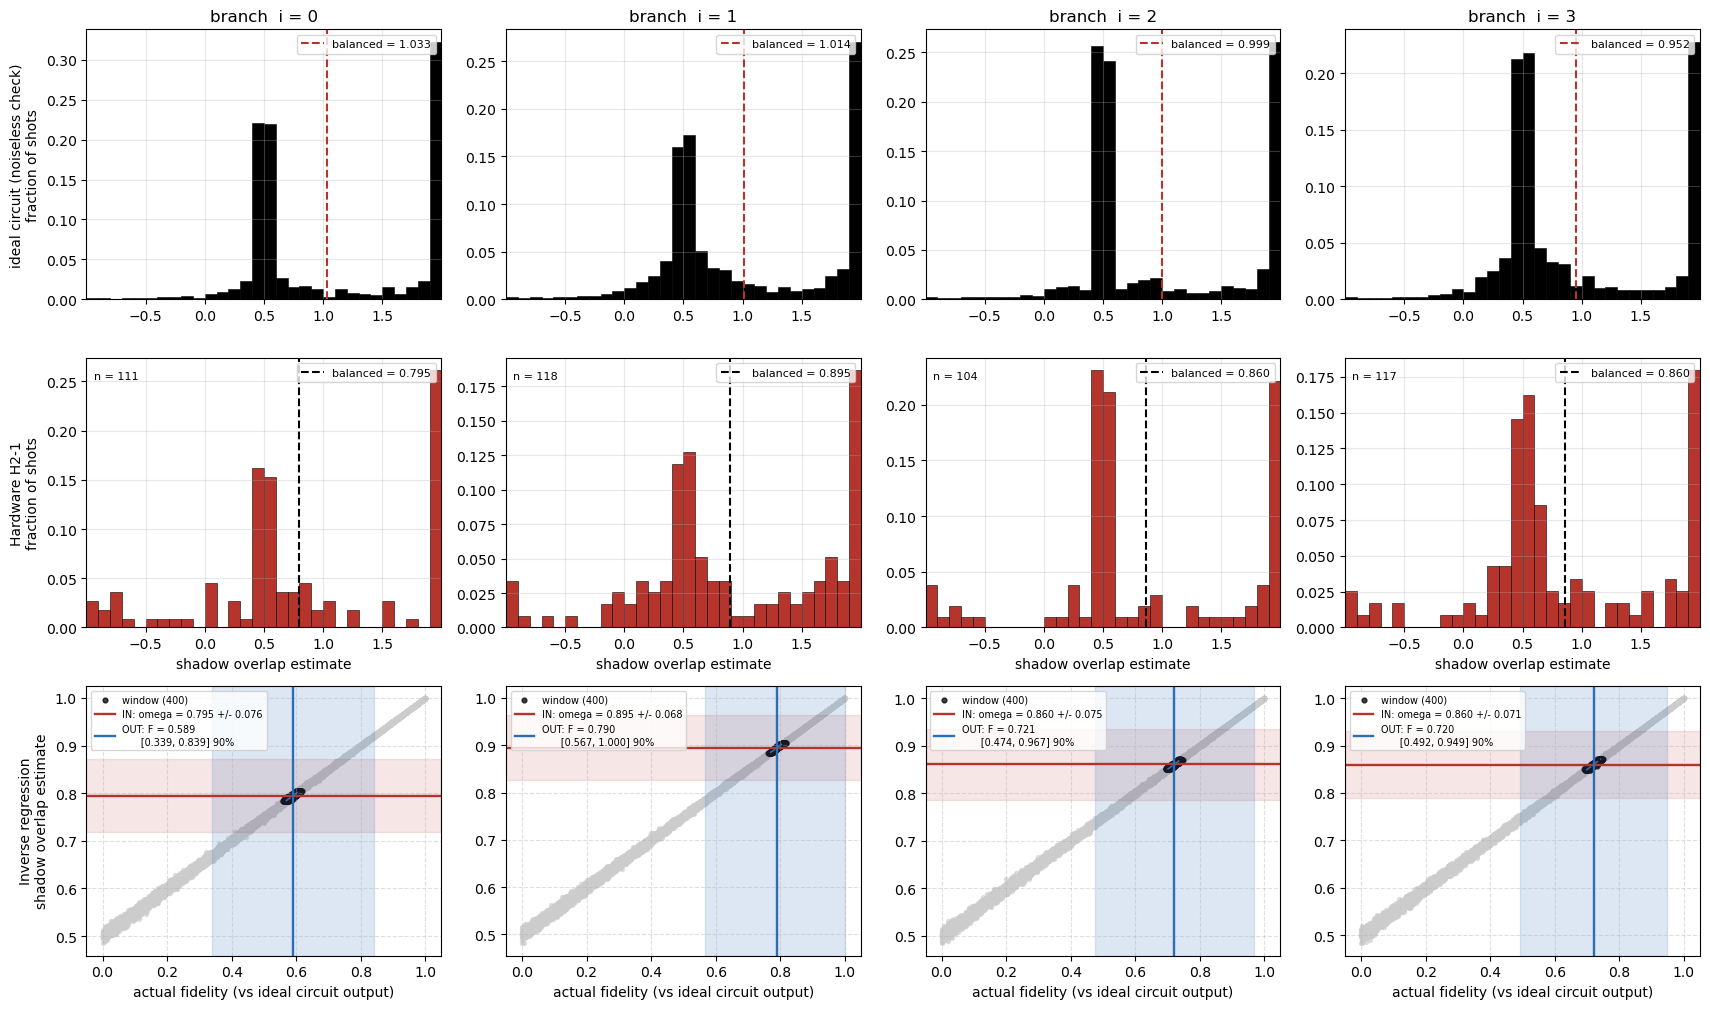

branch 0: omega 0.795+/-0.076  ->  F = 0.589  [0.339, 0.839] 90%  (vs ideal circuit output)
branch 1: omega 0.895+/-0.068  ->  F = 0.790  [0.567, 1.000] 90%  (vs ideal circuit output)
branch 2: omega 0.860+/-0.075  ->  F = 0.721  [0.474, 0.967] 90%  (vs ideal circuit output)
branch 3: omega 0.860+/-0.071  ->  F = 0.720  [0.492, 0.949] 90%  (vs ideal circuit output)


In [90]:
# ============ STORAGE-REGISTER SHADOW OVERLAP, PER INDEX BRANCH (4x1024_L1_mid) ============
# Reference is IDEAL[i] -- what the circuit itself prepares for branch i -- so the
# fidelity reported here is fidelity(hardware, ideal circuit output): pure hardware
# degradation, with the SSO encoding's own lossy approximation factored out. X, Y and Z
# are all genuinely measured now -- no analytic Y shortcut, since IDEAL need not be
# real-valued the way the raw row data was.
import random

RED, BLACK, BLUE, NBINS = "#b5342c", "#000000", "#2a6fb5", 30
BR_STORE  = f"shadow_branch_hw_{TAG}.pkl"
ROWS_FILE = f"shadow_vs_fidelity_rows_{TAG}_vs_ideal.npz"
Z_ASSIGN_SEED, SIM_SEED, SIM_REPS = 11, 2026, 200
CONF, K_NEIGHBOURS, USE, N_MC, MC_SEED = 0.90, 400, "exact", 200_000, 0
NO_SUPPORT_TOL = 1e-12

CHUNKS = [np.asarray(c, dtype=complex) / np.linalg.norm(c) for c in IDEAL]
assert len(CHUNKS) == M_BRANCH and len(CHUNKS[0]) == 2 ** N_S

_no_support = {"n": 0}
def omega(chunk, sb, q, p, tol=NO_SUPPORT_TOL):
    pos = N_S - 1 - q
    z, o = sb[:pos] + "0" + sb[pos+1:], sb[:pos] + "1" + sb[pos+1:]
    v = np.array([chunk[int(z, 2)], chunk[int(o, 2)]], dtype=complex)
    nv = np.linalg.norm(v)
    if nv < tol:
        _no_support["n"] += 1; return 0.0
    return compute_local_overlap(v / nv, int(sb[pos]), PAULIS[p])

def storage_shots(store, seed=Z_ASSIGN_SEED):
    """X and Y are both real hardware shots now; Z is the shared prep/ancilla-targeted bank."""
    recs = []
    for (q, p), d in store["xy"].items():
        for k, c in d.items():
            i, sb = k.split(":"); recs += [(sb, int(i), q, p)] * c
    zs = [(k.split(":")[1], int(k.split(":")[0])) for k, c in store["z_pool"].items() for _ in range(c)]
    random.Random(seed).shuffle(zs)
    recs += [(sb, i, S_QUBITS[j % N_S], 2) for j, (sb, i) in enumerate(zs)]
    return recs

_H, _Sdg = np.array([[1, 1], [1, -1]]) / np.sqrt(2), np.diag([1, -1j]).astype(complex)
def _rot_probs(vec, q, p):
    if p == 2: return np.abs(vec) ** 2
    U = _H if p == 0 else _H @ _Sdg
    v3 = vec.reshape(-1, 2, 2 ** q); b0, b1 = v3[:, 0, :], v3[:, 1, :]
    out = np.empty_like(v3)
    out[:, 0, :], out[:, 1, :] = U[0,0]*b0 + U[0,1]*b1, U[1,0]*b0 + U[1,1]*b1
    return np.abs(out.reshape(-1)) ** 2

def sim_like(recs, reps=SIM_REPS, seed=SIM_SEED):
    rng, cdfs, out = np.random.default_rng(seed), {}, []
    for _, i, q, p in recs:
        if (i, q, p) not in cdfs:
            cdfs[(i, q, p)] = np.cumsum(_rot_probs(CHUNKS[i], q, p))
        cdf = cdfs[(i, q, p)]
        idx = np.minimum(np.searchsorted(cdf, rng.random(reps)), len(cdf) - 1)
        out += [(np.binary_repr(int(j), width=N_S), i, q, p) for j in idx]
    return out

def evaluate(recs):
    _no_support["n"] = 0
    est = np.array([omega(CHUNKS[i], sb, q, p) for sb, i, q, p in recs])
    return est, np.array([i for _, i, _, _ in recs]), np.array([p for *_, p in recs])

def pauli_var(est, pau):
    return {p: float(est[pau == p].var(ddof=1)) for p in range(3) if (pau == p).sum() > 1}

def balanced(est, pau, var_ref=None):
    """Uniform-design (X,Y,Z) mean and its SE -- all three strata are genuinely measured."""
    ms, vs = [], []
    for p in range(3):
        v = est[pau == p]
        if len(v) == 0: return float("nan"), float("nan")
        ms.append(v.mean())
        s2 = v.var(ddof=1) if len(v) > 1 else (var_ref or {}).get(p, np.nan)
        vs.append(s2 / len(v))
    return float(np.mean(ms)), float(np.sqrt(np.nansum(vs)) / 3)

def invert(F, w, omega_star, k):
    sel = np.argsort(np.abs(w - omega_star))[:min(k, len(w))]
    ww, ff = w[sel] - omega_star, F[sel]
    b, a = np.polyfit(ww, ff, 1)
    resid = ff - (a + b * ww)
    return dict(a=a, b=b, resid=resid, sel=sel, lo=w[sel].min(), hi=w[sel].max(), n=len(sel))

def predict(fit, omega_star, omega_se, conf, rng, n=N_MC):
    draws = rng.normal(omega_star, omega_se, n) if omega_se else np.full(n, omega_star)
    vals = fit["a"] + fit["b"] * (draws - omega_star) + rng.choice(fit["resid"], n)
    lo, hi = np.percentile(vals, [(1 - conf) / 2 * 100, (1 + conf) / 2 * 100])
    return float(np.clip(lo, 0, 1)), float(np.clip(hi, 0, 1))

with open(BR_STORE, "rb") as f:
    hw_recs = storage_shots(pickle.load(f))
rows = [("ideal circuit (noiseless check)", BLACK, RED,  sim_like(hw_recs)),
        ("Hardware H2-1",                   RED,   BLACK, hw_recs)]
data = [(label, fill, meanc, *evaluate(recs), pauli_var(evaluate(recs)[0], evaluate(recs)[2]))
        for label, fill, meanc, recs in rows]
with np.load(ROWS_FILE) as _z:
    z = {k: _z[k] for k in _z.files}

edges = np.linspace(min(d[3].min() for d in data), max(d[3].max() for d in data), NBINS + 1)
fig, axes = plt.subplots(3, M_BRANCH, figsize=(4.3 * M_BRANCH, 3.4 * 3), squeeze=False)
for r, (label, fill, meanc, est, br, pau, vref) in enumerate(data):
    for i in range(M_BRANCH):
        ax, v, p = axes[r, i], est[br == i], pau[br == i]
        if len(v):
            ax.hist(v, bins=edges, weights=np.full(len(v), 1/len(v)), color=fill, edgecolor="black", lw=0.4)
            m, s = balanced(v, p, vref)
            ax.axvline(m, color=meanc, ls="--", lw=1.5, label=f"balanced = {m:.3f}")
            if label == "Hardware H2-1":
                ax.text(0.02, 0.95, f"n = {len(v)}", transform=ax.transAxes, va="top", fontsize=8)
            ax.legend(fontsize=8, loc="upper right")
        ax.set_xlim(edges[0], edges[-1]); ax.grid(alpha=0.3)
        if r == 0: ax.set_title(f"branch  i = {i}", fontsize=12)
        else: ax.set_xlabel("shadow overlap estimate")
    axes[r, 0].set_ylabel(f"{label}\nfraction of shots", fontsize=10)

_, _, _, est, br, pau, vref = data[1]
rng, results = np.random.default_rng(MC_SEED), {}
for i in range(M_BRANCH):
    ax = axes[2, i]
    omega_star, omega_se = balanced(est[br == i], pau[br == i], vref)
    w, F = z[f"row{i}_{USE}"], z[f"row{i}_fid"]
    if omega_star != omega_star:
        ax.text(0.5, 0.5, "no estimate yet", transform=ax.transAxes, ha="center"); continue
    fit = invert(F, w, omega_star, K_NEIGHBOURS)
    lo, hi = predict(fit, omega_star, omega_se, CONF, rng)
    results[i] = (omega_star, omega_se, fit, lo, hi)
    inside = np.zeros(len(w), bool); inside[fit["sel"]] = True
    ax.scatter(F[~inside], w[~inside], color="#cccccc", alpha=0.55, s=8)
    ax.scatter(F[inside], w[inside], color="black", alpha=0.75, s=12, label=f"window ({fit['n']})")
    ax.axhspan(omega_star - omega_se, omega_star + omega_se, color=RED, alpha=0.12)
    ax.axhline(omega_star, color=RED, lw=1.7, label=f"IN: omega = {omega_star:.3f} +/- {omega_se:.3f}")
    ax.axvspan(lo, hi, color=BLUE, alpha=0.16)
    ax.axvline(fit["a"], color=BLUE, lw=1.7, label=f"OUT: F = {fit['a']:.3f}\n      [{lo:.3f}, {hi:.3f}] {CONF:.0%}")
    xs = np.linspace(fit["lo"], fit["hi"], 50)
    ax.plot(fit["a"] + fit["b"] * (xs - omega_star), xs, color=BLUE, ls="--", lw=1.2)
    ax.set_xlabel("actual fidelity (vs ideal circuit output)"); ax.grid(True, ls="--", alpha=0.4)
    ax.legend(fontsize=7, loc="upper left")
axes[2, 0].set_ylabel("Inverse regression\nshadow overlap estimate", fontsize=10)
plt.tight_layout()
fig.savefig(f"hardware_results_final_{TAG}_vs_ideal.pdf", bbox_inches="tight")
plt.show()

for i in sorted(results):
    om, se, fit, lo, hi = results[i]
    print(f"branch {i}: omega {om:.3f}+/-{se:.3f}  ->  F = {fit['a']:.3f}  [{lo:.3f}, {hi:.3f}] {CONF:.0%}  (vs ideal circuit output)")



In [4]:
# ============================ SETUP for hardware runs ============================
import os, json, time, pickle, ast, datetime
from pytket.extensions.qiskit import qiskit_to_tk
import qnexus as qnx

RUN    = "hardware"
DEVICE = "H2-1"                                  # strip the trailing q to arm
S_QUBITS, I_QUBITS = tuple(range(N_S)), (N_S, N_S + 1)   # S=0..9, I=10,11 -- registers declared S,I,A0..A3,anc

tk_circ_clean = qiskit_to_tk(qc)

def build_tket_circuit_from_tk_no_measure(tk_circ, basis_choice=False, perm=None):
    circ = tk_circ.copy()
    if basis_choice:
        target_qubit, unitary_id = int(basis_choice[0]), int(basis_choice[1])
        p = PERM if perm is None else perm
        qubit = circ.qubits[p.index(target_qubit)]
        P = ['X', 'Y', 'Z'][unitary_id]
        if P == 'X': circ.H(qubit)
        elif P == 'Y': circ.Sdg(qubit); circ.H(qubit)
    circ.measure_all()
    return circ

def br_load(path):
    if not os.path.exists(path): return None
    with open(path, "rb") as f: return pickle.load(f)

def br_atomic(obj, path):
    tmp = path + ".tmp"
    with open(tmp, "wb") as f: pickle.dump(obj, f)
    for _ in range(30):
        try: os.replace(tmp, path); return
        except PermissionError: time.sleep(0.5)
    os.replace(tmp, path)

def br_index(path):
    return json.load(open(path)) if os.path.exists(path) else {}

def br_register(slot, name, shots, path):
    idx = br_index(path)
    idx[str(tuple(slot))] = {"name": name, "shots": int(shots), "submitted": time.strftime("%Y-%m-%d %H:%M:%S")}
    tmp = path + ".tmp"; json.dump(idx, open(tmp, "w"), indent=1); os.replace(tmp, path)

BR_STORE, BR_PLAN_FILE, BR_JOB_INDEX = f"shadow_branch_hw_{TAG}.pkl", f"shadow_branch_plan_{TAG}.json", f"shadow_branch_jobs_{TAG}.json"


In [5]:
# ===== PREP: seed a fresh per-branch store (run once) =====
if not os.path.exists(BR_STORE):
    br_atomic({"schema": 1, "meta": {"tag": TAG, "created": time.strftime("%Y-%m-%d %H:%M:%S")},
              "z_pool": {}, "xy": {}, "provenance": []}, BR_STORE)
    print(f"seeded empty {BR_STORE}")
else:
    print(f"{BR_STORE} already exists")

Z_SHOTS = 150     # your call -- drives per-qubit X/Y targets too (see PLAN below)


seeded empty shadow_branch_hw_4x1024_L1_mid.pkl


In [72]:
# ===== PLAN: what's left to run =====
# Uniform design: X, Y and Z each target Z_SHOTS shots total, X/Y split evenly per
# storage qubit (Z_SHOTS // N_S each) since Y is now a real measured stratum, not analytic.
def br_s_bits(b):  return b[-N_S:]
def br_branch(b):  n = len(b); return sum(int(b[n-1-q]) << k for k, q in enumerate(I_QUBITS))
def br_sv_bits(key):
    return nexus_to_statevector_order("".join(map(str, key)), PERM) if isinstance(key, (tuple, list)) else str(key)
def br_key(branch, sbits): return f"{branch}:{sbits}"

store = br_load(BR_STORE)
BANK_Z = sum(store["z_pool"].values())
have = {(q, p): sum(store["xy"].get((q, p), {}).values()) for q in S_QUBITS for p in (0, 1)}
idx = br_index(BR_JOB_INDEX)

def _in_flight(slot):
    k = str(tuple(slot))
    return k in idx and not idx[k].get("ingested")

z_in_flight = _in_flight(("Z", 2))
z_needed = max(Z_SHOTS - BANK_Z, 0) if not z_in_flight else 0
target = Z_SHOTS // N_S
need = {(q, p): max(target - have[(q, p)], 0) for q in S_QUBITS for p in (0, 1)}
in_flight = {(q, p): _in_flight((q, p)) for q in S_QUBITS for p in (0, 1)}

print(f"Z bank: {BANK_Z}/{Z_SHOTS}" + (" (in flight)" if z_in_flight else ""))
for q in S_QUBITS:
    xf = " (in flight)" if in_flight[(q, 0)] else ""
    yf = " (in flight)" if in_flight[(q, 1)] else ""
    print(f"  S{q}: X have {have[(q,0)]:>4d} need {need[(q,0)]:>4d}{xf:<12}"
          f"Y have {have[(q,1)]:>4d} need {need[(q,1)]:>4d}{yf}")

if z_needed > 0:
    print(f'\nnext slot: BR_SLOT = ("Z", 2)   # {z_needed} shots')
else:
    nxt = next(((q, p) for q in S_QUBITS for p in (0, 1)
                if need[(q, p)] > 0 and not in_flight[(q, p)]), None)
    print(f'\nnext slot: BR_SLOT = {nxt}   # {need[nxt]} shots' if nxt is not None else "\nplan complete")


Z bank: 150/150
  S0: X have   15 need    0            Y have   15 need    0
  S1: X have   15 need    0            Y have   15 need    0
  S2: X have   15 need    0            Y have   15 need    0
  S3: X have   15 need    0            Y have   15 need    0
  S4: X have    0 need   15 (in flight)Y have    0 need   15 (in flight)
  S5: X have    0 need   15 (in flight)Y have    0 need   15 (in flight)
  S6: X have    0 need   15 (in flight)Y have    0 need   15 (in flight)
  S7: X have    0 need   15 (in flight)Y have    0 need   15 (in flight)
  S8: X have    0 need   15 (in flight)Y have    0 need   15 (in flight)
  S9: X have    0 need   15 (in flight)Y have    0 need   15 (in flight)

plan complete


In [68]:
# ===== CONFIG: compile one slot =====
BR_SLOT = (9,1)      # <<< from PLAN's "next slot"

assert RUN == "hardware"
assert str(tuple(BR_SLOT)) not in idx, f"{BR_SLOT} already submitted"
br_shots = z_needed if BR_SLOT[0] == "Z" else need[tuple(BR_SLOT)]
assert br_shots > 0

br_name = f"HWBR_MRE_{TAG}_{BR_SLOT}-{datetime.datetime.now().strftime('%Y_%m_%d-%H-%M-%S')}"
br_tkc = build_tket_circuit_from_tk_no_measure(tk_circ_clean, False if BR_SLOT[0] == "Z" else BR_SLOT)
br_up  = qnx.circuits.upload(circuit=br_tkc, name=br_name)
br_job = qnx.start_compile_job(programs=[br_up], backend_config=qnx.QuantinuumConfig(device_name=DEVICE),
                               name=br_name, optimisation_level=2)
qnx.jobs.wait_for(br_job, timeout=1800, strategy=qnx.jobs.PollingStrategy())
br_ref = qnx.jobs.results(br_job)[0].get_output()

br_pool = br_load(f"compiled_pool_branch_{TAG}.pkl") or {}
br_pool[tuple(BR_SLOT)] = {"ref": br_ref, "name": br_name, "shots": int(br_shots)}
br_atomic(br_pool, f"compiled_pool_branch_{TAG}.pkl")
print(f"compiled {BR_SLOT} -> {br_name}  ({br_shots} shots)")


compiled (9, 1) -> HWBR_MRE_4x1024_L1_mid_(9, 1)-2026_09_19-15-34-41  (15 shots)


In [ ]:
# ===== EXECUTE: submit (ARM it, then set back to False) =====
BR_ARM = False        # <<< True to submit, then back to False

assert BR_ARM, "not armed"
assert "q" not in DEVICE, f"device is still {DEVICE} -- strip the q to arm"

br_entry = br_load(f"compiled_pool_branch_{TAG}.pkl")[tuple(BR_SLOT)]
br_pkl = f"{br_entry['name']}_results.pkl"
assert not os.path.exists(br_pkl)

br_job_ref = qnx.start_execute_job(programs=[br_entry["ref"]], n_shots=[br_entry["shots"]],
                                   backend_config=qnx.QuantinuumConfig(device_name=DEVICE), name=br_entry["name"])
pickle.dump([br_job_ref], open(br_pkl, "wb"))
br_register(BR_SLOT, br_entry["name"], br_entry["shots"], BR_JOB_INDEX)
print(f"submitted {BR_SLOT}: {br_entry['shots']} shots -> {br_entry['name']}")


submitted (9, 1): 15 shots -> HWBR_MRE_4x1024_L1_mid_(9, 1)-2026_09_19-15-34-41


In [89]:
# ===== INGEST: download completed slots into the store =====
from qnexus.models.job_status import JobStatusEnum

br_store, br_idx, br_filed = br_load(BR_STORE), br_index(BR_JOB_INDEX), 0
for k, rec in sorted(br_idx.items()):
    if rec.get("ingested"): continue
    slot = tuple(ast.literal_eval(k))
    pkl = f"{rec['name']}_results.pkl"
    if not os.path.exists(pkl): print(f"  {pkl} missing"); continue
    refs = pickle.load(open(pkl, "rb"))
    st = qnx.jobs.status(refs[0]).status
    if st != JobStatusEnum.COMPLETED: print(f"  {rec['name']}: {st.value}"); continue
    counts = qnx.jobs.results(refs[0])[0].download_result().get_counts()

    q, p, added = slot[0], slot[1], 0
    for key_, c in counts.items():
        b = br_sv_bits(key_)
        branch, sbits = br_branch(b), br_s_bits(b)
        kk = br_key(branch, sbits)
        if q == "Z": br_store["z_pool"][kk] = br_store["z_pool"].get(kk, 0) + c
        else:
            d = br_store["xy"].setdefault((q, p), {}); d[kk] = d.get(kk, 0) + c
        added += c
    br_store["provenance"].append({"source": rec["name"], "slot": list(slot), "n_added": added,
                                   "when": time.strftime("%Y-%m-%d %H:%M:%S")})
    br_atomic(br_store, BR_STORE)
    br_idx[k]["ingested"] = time.strftime("%Y-%m-%d %H:%M:%S")
    json.dump(br_idx, open(BR_JOB_INDEX + ".tmp", "w"), indent=1); os.replace(BR_JOB_INDEX + ".tmp", BR_JOB_INDEX)
    print(f"  filed {slot}: +{added} shots"); br_filed += 1
print(f"\ningested {br_filed} slot(s). Re-run PLAN for what's left.")


Unknown OpType in BackendInfo: `RZZ`, will omit from BackendInfo. Consider updating your pytket version.
Unknown OpType in BackendInfo: `Rxxyyzz`, will omit from BackendInfo. Consider updating your pytket version.
Unknown OpType in BackendInfo: `U1q`, will omit from BackendInfo. Consider updating your pytket version.
Unknown OpType in BackendInfo: `ZZ`, will omit from BackendInfo. Consider updating your pytket version.


  filed (9, 0): +15 shots


Unknown OpType in BackendInfo: `RZZ`, will omit from BackendInfo. Consider updating your pytket version.
Unknown OpType in BackendInfo: `Rxxyyzz`, will omit from BackendInfo. Consider updating your pytket version.
Unknown OpType in BackendInfo: `U1q`, will omit from BackendInfo. Consider updating your pytket version.
Unknown OpType in BackendInfo: `ZZ`, will omit from BackendInfo. Consider updating your pytket version.


  filed (9, 1): +15 shots

ingested 2 slot(s). Re-run PLAN for what's left.
